
## 1. Data Loading and Initial Inspection

The METABRIC clinical dataset was loaded to examine its structure, dimensions, and available variables. This initial inspection provides the basis for defining survival outcomes and selecting predictors for subsequent analyses.


In [2]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load clinical data
data_path = Path("../data/raw/brca_metabric_clinical_data.tsv")

if not data_path.exists():
    data_path = Path("data/raw/brca_metabric_clinical_data.tsv")

df = pd.read_csv(data_path, sep="\t")

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())


Dataset shape: (2509, 39)

Column names:
['Study ID', 'Patient ID', 'Sample ID', 'Age at Diagnosis', 'Type of Breast Surgery', 'Cancer Type', 'Cancer Type Detailed', 'Cellularity', 'Chemotherapy', 'Pam50 + Claudin-low subtype', 'Cohort', 'ER status measured by IHC', 'ER Status', 'Neoplasm Histologic Grade', 'HER2 status measured by SNP6', 'HER2 Status', 'Tumor Other Histologic Subtype', 'Hormone Therapy', 'Inferred Menopausal State', 'Integrative Cluster', 'Primary Tumor Laterality', 'Lymph nodes examined positive', 'Mutation Count', 'Nottingham prognostic index', 'Oncotree Code', 'Overall Survival (Months)', 'Overall Survival Status', 'PR Status', 'Radio Therapy', 'Relapse Free Status (Months)', 'Relapse Free Status', 'Number of Samples Per Patient', 'Sample Type', 'Sex', '3-Gene classifier subtype', 'TMB (nonsynonymous)', 'Tumor Size', 'Tumor Stage', "Patient's Vital Status"]


,Study ID,Patient ID,Sample ID,Age at Diagnosis,Type of Breast Surgery,Cancer Type,Cancer Type Detailed,Cellularity,Chemotherapy,Pam50 + Claudin-low subtype,...,Relapse Free Status (Months),Relapse Free Status,Number of Samples Per Patient,Sample Type,Sex,3-Gene classifier subtype,TMB (nonsynonymous),Tumor Size,Tumor Stage,Patient's Vital Status
0,brca_metabric,MB-0000,MB-0000,75.65,MASTECTOMY,Breast Cancer,Breast Invasive Ductal Carcinoma,NaN,NO,claudin-low,...,140.500000,0:Not Recurred,1,Primary,Female,ER-/HER2-,0.000000,22.0,2.0,Living
1,brca_metabric,MB-0002,MB-0002,43.19,BREAST CONSERVING,Breast Cancer,Breast Invasive Ductal Carcinoma,High,NO,LumA,...,84.633333,0:Not Recurred,1,Primary,Female,ER+/HER2- High Prolif,2.615035,10.0,1.0,Living
2,brca_metabric,MB-0005,MB-0005,48.87,MASTECTOMY,Breast Cancer,Breast Invasive Ductal Carcinoma,High,YES,LumB,...,153.300000,1:Recurred,1,Primary,Female,NaN,2.615035,15.0,2.0,Died of Disease
3,brca_metabric,MB-0006,MB-0006,47.68,MASTECTOMY,Breast Cancer,Breast Mixed Ductal and Lobular Carcinoma,Moderate,YES,LumB,...,164.933333,0:Not Recurred,1,Primary,Female,NaN,1.307518,25.0,2.0,Living
4,brca_metabric,MB-0008,MB-0008,76.97,MASTECTOMY,Breast Cancer,Breast Mixed Ductal and Lobular Carcinoma,High,YES,LumB,...,18.800000,1:Recurred,1,Primary,Female,ER+/HER2- High Prolif,2.615035,40.0,2.0,Died of Disease



## 2. Variable Overview and Missing Data

We examined variable types, missing values, and the number of unique observations to assess data completeness before defining the survival outcomes. No observations were excluded at this stage.


In [3]:

variable_summary = pd.DataFrame({
    "Variable": df.columns,
    "Type": df.dtypes.values,
    "Missing (n)": df.isna().sum().values,
    "Missing (%)": (df.isna().mean() * 100).round(2).values,
    "Unique values": df.nunique().values
})

display(variable_summary)


,Variable,Type,Missing (n),Missing (%),Unique values
0,Study ID,object,0,0.00,1
1,Patient ID,object,0,0.00,2509
2,Sample ID,object,0,0.00,2509
3,Age at Diagnosis,float64,11,0.44,1843
4,Type of Breast Surgery,object,554,22.08,2
5,Cancer Type,object,0,0.00,1
6,Cancer Type Detailed,object,0,0.00,8
7,Cellularity,object,592,23.60,3
8,Chemotherapy,object,529,21.08,2
9,Pam50 + Claudin-low subtype,object,529,21.08,7



## 3. Assessment of Survival Outcome Completeness

We examined the completeness and coding of overall survival time and event status. Missingness patterns were assessed to determine the number of patients with available survival outcomes before applying any exclusion criteria.


In [4]:

time_col = "Overall Survival (Months)"
status_col = "Overall Survival Status"

print("Survival status categories:")
print(df[status_col].value_counts(dropna=False))

print("\nMissingness pattern:")
missing_pattern = pd.crosstab(
    df[time_col].isna(),
    df[status_col].isna(),
    rownames=["Survival time missing"],
    colnames=["Survival status missing"]
)

display(missing_pattern)

print("\nSurvival time summary:")
print(df[time_col].describe())

print("\nNon-positive survival times:",
      (df[time_col].dropna() <= 0).sum())


Survival status categories:
Overall Survival Status
1:DECEASED    1144
0:LIVING       837
NaN            528
Name: count, dtype: int64

Missingness pattern:


Survival status missing,False,True
Survival time missing,,
False,1981,0
True,0,528



Survival time summary:
count    1981.000000
mean      125.244271
std        76.111772
min         0.000000
25%        60.866667
50%       116.466667
75%       185.133333
max       355.200000
Name: Overall Survival (Months), dtype: float64

Non-positive survival times: 1



### 3.1. Investigation of Zero and Short Survival Times

Patients with zero or very short recorded survival times were examined to identify potential data-quality issues before defining the final analytical cohort.


In [5]:

# Inspect patients with zero or very short survival times
short_survival = df.loc[
    df[time_col].notna() & (df[time_col] <= 1),
    ["Patient ID", "Age at Diagnosis", time_col, status_col]
].copy()

short_survival = short_survival.sort_values(time_col)

print("Patients with survival time <= 1 month:", len(short_survival))

display(short_survival)


Patients with survival time <= 1 month: 3


,Patient ID,Age at Diagnosis,Overall Survival (Months),Overall Survival Status
186,MB-0284,51.42,0.000000,0:LIVING
1694,MB-6229,75.33,0.100000,1:DECEASED
473,MB-0627,54.10,0.766667,0:LIVING



### 3.2. Survival Data Availability Across Cohorts

We examined the availability of overall survival data across the recorded METABRIC cohorts to identify potential differences in outcome completeness.


In [6]:

cohort = df["Cohort"].fillna(-1).astype(int)
os_available = df[time_col].notna()

cohort_summary = pd.crosstab(
    cohort,
    os_available,
    rownames=["Cohort"],
    colnames=["OS available"]
)

cohort_summary = cohort_summary.rename(
    columns={False: "Missing OS", True: "Available OS"}
)

cohort_summary["Total"] = cohort_summary.sum(axis=1)

display(cohort_summary)


OS available,Missing OS,Available OS,Total
Cohort,,,
-1,11,0,11
1,287,522,809
2,0,288,288
3,0,763,763
4,0,238,238
5,0,170,170
6,3,0,3
7,105,0,105
8,82,0,82



### 3.3. Overlap Between Survival Endpoints

The availability of overall survival (OS) and relapse-free survival (RFS) data was compared to identify patients with incomplete OS information but available RFS outcomes.


In [7]:

os_available = df["Overall Survival (Months)"].notna() & df["Overall Survival Status"].notna()

rfs_available = df["Relapse Free Status (Months)"].notna() & df["Relapse Free Status"].notna()

print("Overlap between OS and RFS:")
display(pd.crosstab(
    os_available,
    rfs_available,
    rownames=["OS available"],
    colnames=["RFS available"],
    margins=True
))

endpoint_summary = df.assign(
    OS_available=os_available,
    RFS_available=rfs_available
).groupby("Cohort", dropna=False).agg(
    Patients=("Patient ID", "size"),
    OS_available=("OS_available", "sum"),
    RFS_available=("RFS_available", "sum")
)

display(endpoint_summary)


Overlap between OS and RFS:


RFS available,False,True,All
OS available,,,
False,128,400,528
True,1,1980,1981
All,129,2380,2509


,Patients,OS_available,RFS_available
Cohort,,,
1.0,809,522,806
2.0,288,288,288
3.0,763,763,762
4.0,238,238,238
5.0,170,170,170
6.0,3,0,0
7.0,105,0,0
8.0,82,0,76
9.0,40,0,40



## 4. Definition of the Overall Survival Cohort

Patients with available overall survival time and event status were selected for the primary analysis. Death was defined as the event of interest, while patients alive at their last recorded follow-up were considered right-censored. The original dataset was retained unchanged.


In [8]:

# Define the overall survival cohort
os_mask = df[time_col].notna() & df[status_col].notna()

os_df = df.loc[os_mask].copy()

# Encode death as the event
event_codes = {
    "1:DECEASED": 1,
    "0:LIVING": 0
}

os_df["event"] = os_df[status_col].map(event_codes)

print("Initial patients:", len(df))
print("Missing OS information:", (~os_mask).sum())
print("Patients with available OS:", len(os_df))

print("\nEvents:", (os_df["event"] == 1).sum())
print("Censored:", (os_df["event"] == 0).sum())

print("\nData checks:")
print("Unknown event codes:", os_df["event"].isna().sum())
print("Negative survival times:", (os_df[time_col] < 0).sum())
print("Zero survival times:", (os_df[time_col] == 0).sum())
print("Duplicate patient IDs:", os_df["Patient ID"].duplicated().sum())


Initial patients: 2509
Missing OS information: 528
Patients with available OS: 1981

Events: 1144
Censored: 837

Data checks:
Unknown event codes: 0
Negative survival times: 0
Zero survival times: 1
Duplicate patient IDs: 0



## 5. Overall Survival Analysis

The Kaplan–Meier method was used to estimate the overall survival function. Median survival time and survival probabilities at selected follow-up times were calculated with 95% confidence intervals.


Median survival: 156.33 months


,Time (months),Survival probability
0,12,0.9847
1,36,0.8858
2,60,0.7802
3,120,0.5927


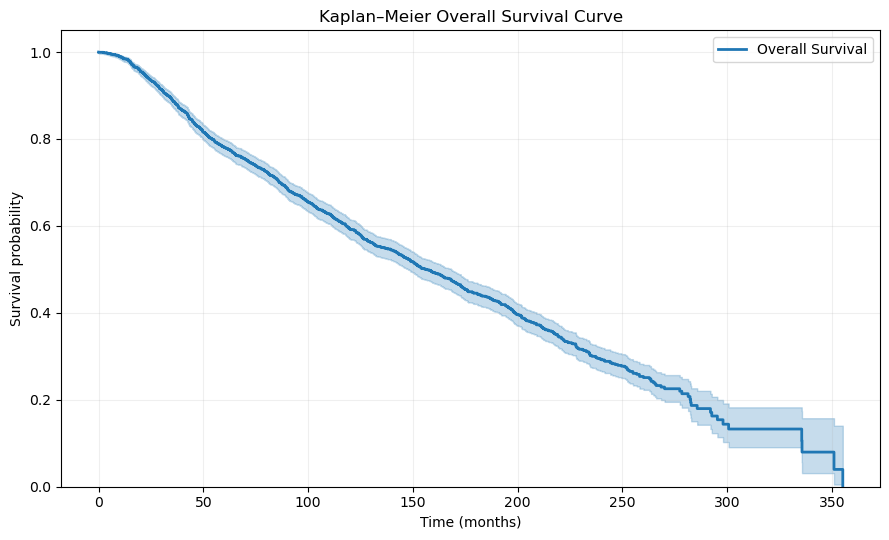

In [9]:

from lifelines import KaplanMeierFitter

km = KaplanMeierFitter()

km.fit(
    durations=os_df[time_col],
    event_observed=os_df["event"],
    label="Overall Survival"
)

print(f"Median survival: {km.median_survival_time_:.2f} months")

survival_times = [12, 36, 60, 120]

survival_estimates = pd.DataFrame({
    "Time (months)": survival_times,
    "Survival probability": km.survival_function_at_times(survival_times).values
})

display(survival_estimates.round(4))

fig, ax = plt.subplots(figsize=(9, 5.5))

km.plot_survival_function(
    ax=ax,
    ci_show=True,
    linewidth=2
)

ax.set_xlabel("Time (months)")
ax.set_ylabel("Survival probability")
ax.set_title("Kaplan–Meier Overall Survival Curve")
ax.set_ylim(0, 1.05)
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()



## 6. Data Splitting for Survival Prediction

Patients were randomly assigned to training (60%), calibration (20%), and test (20%) sets using an outcome-independent split. Separate datasets were maintained to prevent information leakage during model development, conformal calibration, and final evaluation.


In [10]:

from sklearn.model_selection import train_test_split

train_df, remaining_df = train_test_split(
    os_df,
    test_size=0.40,
    random_state=42
)

cal_df, test_df = train_test_split(
    remaining_df,
    test_size=0.50,
    random_state=42
)

split_summary = pd.DataFrame({
    "Dataset": ["Training", "Calibration", "Test"],
    "Patients": [len(train_df), len(cal_df), len(test_df)],
    "Deaths": [
        train_df["event"].sum(),
        cal_df["event"].sum(),
        test_df["event"].sum()
    ]
})

split_summary["Censored"] = (
    split_summary["Patients"] - split_summary["Deaths"]
)

split_summary["Event (%)"] = (
    100 * split_summary["Deaths"] / split_summary["Patients"]
).round(2)

display(split_summary)

train_ids = set(train_df["Patient ID"])
cal_ids = set(cal_df["Patient ID"])
test_ids = set(test_df["Patient ID"])

assert len(train_ids & cal_ids) == 0
assert len(train_ids & test_ids) == 0
assert len(cal_ids & test_ids) == 0

assert len(train_df) + len(cal_df) + len(test_df) == len(os_df)

print("All split checks passed.")


,Dataset,Patients,Deaths,Censored,Event (%)
0,Training,1188,686,502,57.74
1,Calibration,396,225,171,56.82
2,Test,397,233,164,58.69


All split checks passed.



## 7. Predictor Eligibility and Leakage Assessment

All variables were screened to identify potential predictors, outcome-related information, identifiers, and variables requiring temporal verification. Predictor eligibility was assessed before model development to minimize information leakage.


In [11]:

# Classify variables before model development

identifiers = [
    "Study ID", "Patient ID", "Sample ID"
]

outcome_vars = [
    "Overall Survival (Months)",
    "Overall Survival Status",
    "Relapse Free Status (Months)",
    "Relapse Free Status",
    "Patient's Vital Status",
    "event"
]

treatment_vars = [
    "Chemotherapy",
    "Hormone Therapy",
    "Radio Therapy",
    "Type of Breast Surgery"
]

variable_roles = []

for col in os_df.columns:

    if col in identifiers:
        role = "Identifier"

    elif col in outcome_vars:
        role = "Outcome / potential leakage"

    elif col == "Cohort":
        role = "Cohort information"

    elif col in treatment_vars:
        role = "Treatment - timing to verify"

    elif os_df[col].nunique(dropna=True) <= 1:
        role = "Constant variable"

    else:
        role = "Potential predictor - timing to verify"

    variable_roles.append({
        "Variable": col,
        "Role": role
    })

feature_audit = pd.DataFrame(variable_roles)

display(feature_audit)

print("\nVariable counts by role:")
display(feature_audit["Role"].value_counts())


,Variable,Role
0,Study ID,Identifier
1,Patient ID,Identifier
2,Sample ID,Identifier
3,Age at Diagnosis,Potential predictor - timing to verify
4,Type of Breast Surgery,Treatment - timing to verify
5,Cancer Type,Constant variable
6,Cancer Type Detailed,Potential predictor - timing to verify
7,Cellularity,Potential predictor - timing to verify
8,Chemotherapy,Treatment - timing to verify
9,Pam50 + Claudin-low subtype,Potential predictor - timing to verify



Variable counts by role:


Role
Potential predictor - timing to verify    22
Outcome / potential leakage                6
Constant variable                          4
Treatment - timing to verify               4
Identifier                                 3
Cohort information                         1
Name: count, dtype: int64


## 8. Definition of Candidate Predictors

Candidate predictors were identified using predefined exclusion rules. Identifiers, survival outcomes, treatment variables with uncertain timing, and cohort identifiers were excluded from the initial model. Constant features were identified using training data only. All remaining variables were retained for further eligibility assessment.


In [12]:

# Variables not eligible for the initial model
excluded_cols = [
    "Study ID",
    "Patient ID",
    "Sample ID",
    "Cohort",
    "Overall Survival (Months)",
    "Overall Survival Status",
    "Relapse Free Status (Months)",
    "Relapse Free Status",
    "Patient's Vital Status",
    "event",
    "Chemotherapy",
    "Hormone Therapy",
    "Radio Therapy",
    "Type of Breast Surgery"
]

# Check constant features using training data only
constant_cols = [
    col for col in train_df.columns
    if train_df[col].nunique(dropna=True) <= 1
]

# Retain all remaining candidate predictors
candidate_features = [
    col for col in train_df.columns
    if col not in excluded_cols
    and col not in constant_cols
]

print("Constant features:", constant_cols)
print("\nNumber of candidate predictors:", len(candidate_features))

print("\nCandidate predictors:")
for i, col in enumerate(candidate_features, 1):
    print(f"{i:2d}. {col}")

assert not set(candidate_features) & set(excluded_cols)
print("\nFeature exclusion check passed.")


Constant features: ['Study ID', 'Cancer Type', 'Number of Samples Per Patient', 'Sample Type', 'Sex']

Number of candidate predictors: 22

Candidate predictors:
 1. Age at Diagnosis
 2. Cancer Type Detailed
 3. Cellularity
 4. Pam50 + Claudin-low subtype
 5. ER status measured by IHC
 6. ER Status
 7. Neoplasm Histologic Grade
 8. HER2 status measured by SNP6
 9. HER2 Status
10. Tumor Other Histologic Subtype
11. Inferred Menopausal State
12. Integrative Cluster
13. Primary Tumor Laterality
14. Lymph nodes examined positive
15. Mutation Count
16. Nottingham prognostic index
17. Oncotree Code
18. PR Status
19. 3-Gene classifier subtype
20. TMB (nonsynonymous)
21. Tumor Size
22. Tumor Stage

Feature exclusion check passed.



## 9. Definition of Predictor Sets

Two predictor sets were predefined for retrospective survival prediction: a clinical-pathological set and an extended set incorporating molecular features. Treatment and outcome-related variables were excluded. The exact measurement dates of several tumor-derived features were unavailable; therefore, the analysis was not interpreted as prospective prediction at diagnosis.


In [13]:

# Clinical and pathological predictors
clinical_features = [
    "Age at Diagnosis",
    "Cancer Type Detailed",
    "Neoplasm Histologic Grade",
    "ER Status",
    "HER2 Status",
    "PR Status",
    "Tumor Size",
    "Tumor Stage",
    "Lymph nodes examined positive",
    "Inferred Menopausal State",
    "Primary Tumor Laterality"
]

# Extended model includes all previously eligible candidates
extended_features = candidate_features.copy()

assert set(clinical_features).issubset(set(extended_features))

print("Clinical predictors:", len(clinical_features))
print("Extended predictors:", len(extended_features))

print("\nAdditional predictors in the extended model:")
for col in extended_features:
    if col not in clinical_features:
        print("-", col)


Clinical predictors: 11
Extended predictors: 22

Additional predictors in the extended model:
- Cellularity
- Pam50 + Claudin-low subtype
- ER status measured by IHC
- HER2 status measured by SNP6
- Tumor Other Histologic Subtype
- Integrative Cluster
- Mutation Count
- Nottingham prognostic index
- Oncotree Code
- 3-Gene classifier subtype
- TMB (nonsynonymous)



## 10. Random Survival Forest Model Development

Two Random Survival Forest models were fitted using clinical-pathological and extended predictor sets. Identical model settings were used, and preprocessing was fitted exclusively on the training data. Calibration and test sets were reserved for subsequent analyses.


In [14]:

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sksurv.ensemble import RandomSurvivalForest
from sksurv.util import Surv

# Survival outcome
y_train = Surv.from_arrays(
    event=train_df["event"].astype(bool).to_numpy(),
    time=train_df[time_col].to_numpy()
)

def build_rsf(features):
    X = train_df[features]

    numeric = X.select_dtypes(include="number").columns.tolist()
    categorical = X.select_dtypes(exclude="number").columns.tolist()

    preprocessing = ColumnTransformer([
        ("numeric", SimpleImputer(strategy="median"), numeric),
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ))
        ]), categorical)
    ])

    model = RandomSurvivalForest(
        n_estimators=200,
        min_samples_split=10,
        min_samples_leaf=7,
        max_features="sqrt",
        n_jobs=-1,
        random_state=42
    )

    return Pipeline([
        ("preprocessing", preprocessing),
        ("rsf", model)
    ])


# Fit both models using training data only
rsf_clinical = build_rsf(clinical_features)
rsf_extended = build_rsf(extended_features)

rsf_clinical.fit(train_df[clinical_features], y_train)
rsf_extended.fit(train_df[extended_features], y_train)

print("Both models fitted successfully.")

for name, model, features in [
    ("Clinical", rsf_clinical, clinical_features),
    ("Extended", rsf_extended, extended_features)
]:
    n_encoded = model.named_steps["preprocessing"].transform(
        train_df[features]
    ).shape[1]

    print(f"\n{name} model")
    print("Patients:", len(train_df))
    print("Original predictors:", len(features))
    print("Encoded features:", n_encoded)
    print("Trees:", model.named_steps["rsf"].n_estimators)


Both models fitted successfully.

Clinical model
Patients: 1188
Original predictors: 11
Encoded features: 22
Trees: 200

Extended model
Patients: 1188
Original predictors: 22
Encoded features: 71
Trees: 200



## 11. Hyperparameter Optimization

Randomized search with three-fold cross-validation was used to optimize RSF hyperparameters within the training set. The integrated Brier score was evaluated over 12–120 months, with administrative censoring at 121 months applied only during validation scoring. All preprocessing was refitted within each training fold.


In [15]:

from sklearn.model_selection import RandomizedSearchCV, KFold
from sksurv.metrics import as_integrated_brier_score_scorer

# Restrict the evaluation horizon without changing model training
class HorizonIBS(as_integrated_brier_score_scorer):
    def score(self, X, y):
        y_eval = y.copy()
        event_col, time_col_y = y_eval.dtype.names

        horizon = float(self.times[-1]) + 1.0
        beyond = y_eval[time_col_y] > horizon

        y_eval[event_col][beyond] = False
        y_eval[time_col_y][beyond] = horizon

        return super().score(X, y_eval)


cv = KFold(n_splits=3, shuffle=True, random_state=42)
evaluation_times = np.linspace(12, 120, 20)

# Check follow-up support in each fold
for fold, (train_idx, val_idx) in enumerate(cv.split(train_df), 1):
    train_times = y_train["time"][train_idx]
    val_times = y_train["time"][val_idx]

    print(
        f"Fold {fold}: "
        f"train max = {train_times.max():.1f}, "
        f"validation max = {val_times.max():.1f}"
    )

    assert train_times.max() > 121
    assert val_times.max() > 120
    assert val_times.min() < 12


param_space = {
    "estimator__rsf__min_samples_leaf": [3, 5, 8, 12, 20],
    "estimator__rsf__min_samples_split": [6, 10, 20, 30],
    "estimator__rsf__max_features": ["sqrt", "log2", 0.5, 0.8],
    "estimator__rsf__max_depth": [5, 8, 12, None]
}

models = {
    "Clinical": (rsf_clinical, clinical_features),
    "Extended": (rsf_extended, extended_features)
}

random_searches = {}

for name, (model, features) in models.items():

    print(f"\nRandomized Search: {name}")

    model.set_params(rsf__n_jobs=1)

    scorer = HorizonIBS(
        estimator=model,
        times=evaluation_times
    )

    search = RandomizedSearchCV(
        estimator=scorer,
        param_distributions=param_space,
        n_iter=18,
        cv=cv,
        n_jobs=1,
        pre_dispatch=1,
        random_state=42,
        refit=True,
        error_score="raise",
        return_train_score=False
    )

    search.fit(train_df[features], y_train)

    random_searches[name] = search

    print("Best CV IBS:", round(-search.best_score_, 4))
    print("Best parameters:")

    for param, value in search.best_params_.items():
        print(f"  {param}: {value}")

    results = pd.DataFrame(search.cv_results_)
    results["CV IBS"] = -results["mean_test_score"]
    results["CV SD"] = results["std_test_score"]

    display(
        results[["CV IBS", "CV SD", "params"]]
        .sort_values("CV IBS")
        .head(5)
    )


Fold 1: train max = 351.0, validation max = 355.2
Fold 2: train max = 355.2, validation max = 351.0
Fold 3: train max = 355.2, validation max = 330.4

Randomized Search: Clinical
Best CV IBS: 0.1359
Best parameters:
  estimator__rsf__min_samples_split: 20
  estimator__rsf__min_samples_leaf: 3
  estimator__rsf__max_features: sqrt
  estimator__rsf__max_depth: 8


,CV IBS,CV SD,params
12,0.135922,0.003080,"{'estimator__rsf__min_samples_split': 20, 'est..."
5,0.135973,0.003498,"{'estimator__rsf__min_samples_split': 20, 'est..."
10,0.135973,0.003498,"{'estimator__rsf__min_samples_split': 20, 'est..."
6,0.136065,0.003321,"{'estimator__rsf__min_samples_split': 20, 'est..."
8,0.136130,0.003232,"{'estimator__rsf__min_samples_split': 6, 'esti..."



Randomized Search: Extended
Best CV IBS: 0.1358
Best parameters:
  estimator__rsf__min_samples_split: 6
  estimator__rsf__min_samples_leaf: 3
  estimator__rsf__max_features: sqrt
  estimator__rsf__max_depth: None


,CV IBS,CV SD,params
13,0.135841,0.003478,"{'estimator__rsf__min_samples_split': 6, 'esti..."
8,0.135903,0.003251,"{'estimator__rsf__min_samples_split': 6, 'esti..."
10,0.136308,0.002892,"{'estimator__rsf__min_samples_split': 20, 'est..."
12,0.136384,0.003129,"{'estimator__rsf__min_samples_split': 20, 'est..."
6,0.136435,0.003072,"{'estimator__rsf__min_samples_split': 20, 'est..."



## 12. Grid Search Refinement

Grid search with five-fold cross-validation was conducted to refine RSF hyperparameters identified during randomized search. The same candidate grid and evaluation horizon were applied to both predictor sets. Model selection was based on the integrated Brier score, using training data exclusively.


In [16]:

from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, KFold

# Five-fold cross-validation
grid_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Refined search space
grid_params = {
    "estimator__rsf__min_samples_leaf": [2, 3, 5],
    "estimator__rsf__min_samples_split": [6, 12, 20],
    "estimator__rsf__max_features": ["sqrt", 0.5],
    "estimator__rsf__max_depth": [8, None]
}

grid_searches = {}

for name, (base_model, features) in models.items():

    print(f"\nGrid Search: {name}")

    model = clone(base_model)
    model.set_params(rsf__n_jobs=1)

    scorer = HorizonIBS(
        estimator=model,
        times=evaluation_times
    )

    search = GridSearchCV(
        estimator=scorer,
        param_grid=grid_params,
        cv=grid_cv,
        n_jobs=1,
        refit=True,
        error_score="raise",
        return_train_score=False
    )

    search.fit(train_df[features], y_train)

    grid_searches[name] = search

    results = pd.DataFrame(search.cv_results_)

    results["CV IBS"] = -results["mean_test_score"]
    results["CV SD"] = results["std_test_score"]

    print(f"Best 5-fold CV IBS: {-search.best_score_:.4f}")

    print("\nBest parameters:")
    for param, value in search.best_params_.items():
        print(f"{param.replace('estimator__rsf__', '')}: {value}")

    print("\nTop 5 configurations:")
    display(
        results[["CV IBS", "CV SD", "params"]]
        .sort_values("CV IBS")
        .head(5)
    )



Grid Search: Clinical
Best 5-fold CV IBS: 0.1364

Best parameters:
max_depth: 8
max_features: sqrt
min_samples_leaf: 2
min_samples_split: 20

Top 5 configurations:


,CV IBS,CV SD,params
2,0.136439,0.008493,"{'estimator__rsf__max_depth': 8, 'estimator__r..."
20,0.136448,0.008055,"{'estimator__rsf__max_depth': None, 'estimator..."
5,0.136560,0.008522,"{'estimator__rsf__max_depth': 8, 'estimator__r..."
7,0.136569,0.008408,"{'estimator__rsf__max_depth': 8, 'estimator__r..."
3,0.136578,0.007905,"{'estimator__rsf__max_depth': 8, 'estimator__r..."



Grid Search: Extended
Best 5-fold CV IBS: 0.1360

Best parameters:
max_depth: None
max_features: sqrt
min_samples_leaf: 5
min_samples_split: 12

Top 5 configurations:


,CV IBS,CV SD,params
25,0.135951,0.009199,"{'estimator__rsf__max_depth': None, 'estimator..."
26,0.136084,0.009314,"{'estimator__rsf__max_depth': None, 'estimator..."
24,0.136099,0.009488,"{'estimator__rsf__max_depth': None, 'estimator..."
23,0.136184,0.009277,"{'estimator__rsf__max_depth': None, 'estimator..."
35,0.136219,0.009653,"{'estimator__rsf__max_depth': None, 'estimator..."



## 13. Censoring Diagnostics

The censoring distribution was examined in the training set to assess follow-up support and the potential stability of inverse probability of censoring weights. This diagnostic assessment precedes censoring-aware conformal calibration.


In [17]:

# Retrieve the tuned survival models
tuned_models = {
    name: grid_searches[name].best_estimator_.estimator_
    for name in ["Clinical", "Extended"]
}

# Estimate the censoring survival function
censor_km = KaplanMeierFitter()

censor_km.fit(
    durations=train_df[time_col],
    event_observed=(train_df["event"] == 0)
)

check_times = [12, 36, 60, 120]

censoring_summary = pd.DataFrame({
    "Time (months)": check_times,
    "Patients at risk": [
        (train_df[time_col] >= t).sum()
        for t in check_times
    ],
    "G(t)": censor_km.survival_function_at_times(check_times).values
})

censoring_summary["IPCW at t"] = (
    1 / censoring_summary["G(t)"]
)

display(censoring_summary.round(4))

print("Tuned models:", list(tuned_models.keys()))
print("Training patients:", len(train_df))
print("Observed deaths:", train_df["event"].sum())
print("Censored patients:", (train_df["event"] == 0).sum())


,Time (months),Patients at risk,G(t),IPCW at t
0,12,1165,0.9924,1.0076
1,36,1041,0.9808,1.0196
2,60,906,0.9653,1.0359
3,120,594,0.8321,1.2018


Tuned models: ['Clinical', 'Extended']
Training patients: 1188
Observed deaths: 686
Censored patients: 502



## 14. Conservative Conformal Survival Calibration

A conservative split-conformal baseline was constructed using observed follow-up times. Training-fitted RSF predictions were calibrated separately for both predictor sets to obtain lower survival bounds at 90% nominal coverage. No censoring times were imputed, and the test set was not accessed.


In [18]:

alpha = 0.10
horizon = 120

def capped_median(model, data, features):
    survival_curves = model.predict_survival_function(data[features])
    predictions = []

    for curve in survival_curves:
        crossing = np.flatnonzero(curve.y <= 0.5)

        if len(crossing) > 0:
            median = curve.x[crossing[0]]
        else:
            median = horizon

        predictions.append(min(median, horizon))

    return np.array(predictions)


baseline_results = {}

for name, features in [
    ("Clinical", clinical_features),
    ("Extended", extended_features)
]:
    model = tuned_models[name]

    predicted_time = capped_median(model, cal_df, features)
    observed_time = cal_df[time_col].to_numpy()

    scores = predicted_time - observed_time

    n = len(scores)
    rank = int(np.ceil((n + 1) * (1 - alpha)))
    threshold = np.sort(scores)[rank - 1]

    lower_bounds = np.maximum(0, predicted_time - threshold)

    baseline_results[name] = {
        "threshold": threshold,
        "lower_bounds": lower_bounds
    }

    print(f"\n{name} model")
    print(f"Calibration patients: {n}")
    print(f"Conformal threshold: {threshold:.2f}")
    print(f"Median lower bound: {np.median(lower_bounds):.2f} months")
    print(f"Zero bounds: {(lower_bounds == 0).mean() * 100:.1f}%")



Clinical model
Calibration patients: 396
Conformal threshold: 81.87
Median lower bound: 38.13 months
Zero bounds: 9.1%

Extended model
Calibration patients: 396
Conformal threshold: 81.97
Median lower bound: 38.03 months
Zero bounds: 9.6%



## 15. Diagnostic Assessment of Conformal Lower Bounds

The distribution of predicted survival times and conformal lower bounds was examined to assess potential truncation at the predefined 120-month horizon. Particular attention was given to the proportion of horizon-capped predictions and the variability of lower bounds.


In [19]:

diagnostic_results = []

for name, features in [
    ("Clinical", clinical_features),
    ("Extended", extended_features)
]:
    model = tuned_models[name]

    predictions = capped_median(model, cal_df, features)
    threshold = baseline_results[name]["threshold"]
    lower_bounds = np.maximum(0, predictions - threshold)

    diagnostic_results.append({
        "Model": name,
        "Median prediction": np.median(predictions),
        "Predictions at 120 (%)": 100 * np.mean(predictions == 120),
        "Median lower bound": np.median(lower_bounds),
        "Lower bound SD": np.std(lower_bounds),
        "Unique lower bounds": len(np.unique(lower_bounds)),
        "Zero bounds (%)": 100 * np.mean(lower_bounds == 0)
    })

diagnostic_table = pd.DataFrame(diagnostic_results)

display(diagnostic_table.round(3))


,Model,Median prediction,Predictions at 120 (%),Median lower bound,Lower bound SD,Unique lower bounds,Zero bounds (%)
0,Clinical,120.0,73.737,38.133,12.872,51,9.091
1,Extended,120.0,69.949,38.033,13.198,59,9.596



## 16. Survival Quantile Extraction

The preliminary median-based conformal approach showed substantial ceiling effects at 120 months. We therefore examined the model-based 10th survival-time quantile without artificial truncation. This diagnostic was restricted to training data and does not represent conformal calibration.


In [20]:

def survival_time_quantile(model, X, alpha=0.10):
    curves = model.predict_survival_function(X)
    quantiles = []

    for curve in curves:
        crossing = np.flatnonzero(curve.y <= 1 - alpha)

        if len(crossing):
            quantiles.append(curve.x[crossing[0]])
        else:
            quantiles.append(np.nan)

    return np.array(quantiles)


quantile_results = []

for name, features in [
    ("Clinical", clinical_features),
    ("Extended", extended_features)
]:
    predictions = survival_time_quantile(
        tuned_models[name],
        train_df[features],
        alpha=0.10
    )

    valid = predictions[np.isfinite(predictions)]

    quantile_results.append({
        "Model": name,
        "Patients": len(predictions),
        "Undefined quantiles (%)": 100 * np.mean(~np.isfinite(predictions)),
        "Median quantile": np.median(valid) if len(valid) else np.nan,
        "Quantile SD": np.std(valid) if len(valid) else np.nan,
        "Unique quantiles": len(np.unique(valid))
    })

display(pd.DataFrame(quantile_results).round(3))


,Model,Patients,Undefined quantiles (%),Median quantile,Quantile SD,Unique quantiles
0,Clinical,1188,0.0,42.533,20.355,263
1,Extended,1188,0.0,42.700,26.369,304



## 17. Event-Observation Probability Estimation

**Methodological reference:** Davidov et al. (2025), *Conformalized Survival Analysis for General Right-Censored Data*, ICLR 2025.

**Method:** Following the weighting principle underlying Focused Calibration (Algorithm 2), we estimate the conditional probability of observing an event, P(δ = 1 | X), using a random forest classifier with three-fold probability calibration.

**Implementation:** This is our implementation of the event-observation probability estimator, rather than a direct reproduction of the authors' code. Estimated inverse-probability weights are assessed for instability before conformal calibration.

**Reference:**  
Davidov H, Feldman S, Shamai G, Kimmel R, Romano Y. Conformalized survival analysis for general right-censored data. International Conference on Learning Representations (ICLR); 2025.

- Paper: https://openreview.net/forum?id=JQtuCumAFD
- Original code: https://github.com/HenDav/conformal_surv_general


In [21]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV

event_probability_models = {}
cal_event_probs = {}
weight_diagnostics = []

for name, features in [
    ("Clinical", clinical_features),
    ("Extended", extended_features)
]:
    preprocessing = clone(
        tuned_models[name].named_steps["preprocessing"]
    )

    classifier = Pipeline([
        ("preprocessing", preprocessing),
        ("rf", RandomForestClassifier(
            n_estimators=200,
            max_depth=4,
            min_samples_leaf=15,
            random_state=42,
            n_jobs=1
        ))
    ])

    model = CalibratedClassifierCV(
        estimator=classifier,
        method="sigmoid",
        cv=3
    )

    model.fit(train_df[features], train_df["event"])

    p_cal = model.predict_proba(cal_df[features])[:, 1]

    assert np.all(np.isfinite(p_cal))
    assert np.all((p_cal > 0) & (p_cal <= 1))

    event_probability_models[name] = model
    cal_event_probs[name] = p_cal

    observed = cal_df["event"].to_numpy() == 1
    weights = 1 / p_cal[observed]

    effective_n = weights.sum() ** 2 / np.sum(weights ** 2)

    weight_diagnostics.append({
        "Model": name,
        "Observed events": observed.sum(),
        "Minimum p(event)": p_cal.min(),
        "Median p(event)": np.median(p_cal),
        "Maximum weight": weights.max(),
        "Effective sample size": effective_n
    })

display(pd.DataFrame(weight_diagnostics).round(3))


,Model,Observed events,Minimum p(event),Median p(event),Maximum weight,Effective sample size
0,Clinical,225,0.204,0.567,4.678,192.625
1,Extended,225,0.170,0.582,4.760,194.594



## 18. Focused Conformal Calibration

**Reference:** Davidov H, Feldman S, Shamai G, Kimmel R, Romano Y. *Conformalized Survival Analysis for General Right-Censored Data*. ICLR; 2025.

**Method:** Focused Calibration (Section 3.1; Algorithm 2).

We calibrated RSF-derived survival-time quantiles using inverse event-observation probability weights. Weighted miscoverage was estimated from uncensored observations, and the largest admissible quantile level was selected for a target miscoverage of 10%.

**Implementation:** The published algorithm was adapted to the fitted RSF models using a fixed quantile grid. Calibration was performed without accessing the test outcomes. The resulting coverage properties remain subject to the assumptions and estimation accuracy discussed in the original paper.

**Paper:** https://proceedings.iclr.cc/paper_files/paper/2025/file/f49d76cf84df83a611883c621c96d2d9-Paper-Conference.pdf

**Code:** https://github.com/HenDav/conformal_surv_general


In [22]:

alpha = 0.10
tau_grid = np.linspace(0, 1, 201)

def predict_time_quantiles(model, X, levels):
    curves = model.predict_survival_function(X)
    quantiles = np.full((len(levels), len(curves)), np.inf)

    for i, curve in enumerate(curves):
        event_prob = 1 - curve.y
        idx = np.searchsorted(event_prob, levels, side="left")

        valid = idx < len(curve.x)
        quantiles[valid, i] = curve.x[idx[valid]]

    quantiles[0, :] = 0.0

    return quantiles


focused_results = []
focused_levels = {}

cal_times = cal_df[time_col].to_numpy()
cal_events = cal_df["event"].to_numpy().astype(bool)

for name, features in [
    ("Clinical", clinical_features),
    ("Extended", extended_features)
]:
    model = tuned_models[name]
    p_event = cal_event_probs[name]

    quantiles = predict_time_quantiles(
        model, cal_df[features], tau_grid
    )

    weights = np.where(cal_events, 1 / p_event, 0.0)

    miscoverage = (
        (quantiles > cal_times[None, :]) @ weights
    ) / weights.sum()

    running_max = np.maximum.accumulate(miscoverage)

    eligible = np.flatnonzero(running_max <= alpha)
    tau_hat = tau_grid[eligible[-1]] if len(eligible) else 0.0

    idx = np.where(np.isclose(tau_grid, tau_hat))[0][0]
    lower_bounds = quantiles[idx]

    focused_levels[name] = tau_hat

    focused_results.append({
        "Model": name,
        "Selected tau": tau_hat,
        "Weighted miscoverage": miscoverage[idx],
        "Median lower bound": np.median(lower_bounds),
        "Undefined bounds (%)": 100 * np.mean(~np.isfinite(lower_bounds)),
        "Zero bounds (%)": 100 * np.mean(lower_bounds == 0)
    })

focused_summary = pd.DataFrame(focused_results)

display(focused_summary.round(4))


,Model,Selected tau,Weighted miscoverage,Median lower bound,Undefined bounds (%),Zero bounds (%)
0,Clinical,0.065,0.0878,29.3,0.0,0.0
1,Extended,0.070,0.0939,31.3,0.0,0.0



## 19. Hyperparameter Optimization of Event-Observation Models

**Methodological reference:** Davidov et al. (2025), *Conformalized Survival Analysis for General Right-Censored Data*, ICLR 2025, Section 3.1 and Algorithm 2.

The probability of observing an event, P(δ = 1 | X), was estimated using Random Forest classifiers. Hyperparameters were optimized through randomized search with three-fold stratified cross-validation, using negative log loss as the selection criterion.

**Implementation:** Hyperparameter optimization is an additional modeling step in our study, not a direct reproduction of the published algorithm. All model selection and preprocessing were restricted to the training set. The calibration and test sets were excluded.

**Reference:** https://openreview.net/forum?id=JQtuCumAFD

**Original code:** https://github.com/HenDav/conformal_surv_general


In [23]:

from sklearn.model_selection import StratifiedKFold

event_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

event_param_space = {
    "rf__n_estimators": [150, 250, 350],
    "rf__max_depth": [3, 5, 8, None],
    "rf__min_samples_leaf": [5, 10, 20],
    "rf__min_samples_split": [2, 10, 20],
    "rf__max_features": ["sqrt", 0.7]
}

event_searches = {}

for name, features in [
    ("Clinical", clinical_features),
    ("Extended", extended_features)
]:

    preprocessing = clone(
        tuned_models[name].named_steps["preprocessing"]
    )

    classifier = Pipeline([
        ("preprocessing", preprocessing),
        ("rf", RandomForestClassifier(
            random_state=42,
            n_jobs=1
        ))
    ])

    search = RandomizedSearchCV(
        estimator=classifier,
        param_distributions=event_param_space,
        n_iter=12,
        scoring="neg_log_loss",
        cv=event_cv,
        n_jobs=1,
        random_state=42,
        refit=True,
        error_score="raise"
    )

    search.fit(
        train_df[features],
        train_df["event"]
    )

    event_searches[name] = search

    print(f"\n{name} model")
    print(f"Best CV Log Loss: {-search.best_score_:.4f}")

    print("\nBest parameters:")
    for param, value in search.best_params_.items():
        print(f"{param}: {value}")

    results = pd.DataFrame(search.cv_results_)

    results["CV Log Loss"] = -results["mean_test_score"]
    results["CV SD"] = results["std_test_score"]

    display(
        results[["CV Log Loss", "CV SD", "params"]]
        .sort_values("CV Log Loss")
        .head(5)
    )



Clinical model
Best CV Log Loss: 0.5970

Best parameters:
rf__n_estimators: 150
rf__min_samples_split: 20
rf__min_samples_leaf: 20
rf__max_features: 0.7
rf__max_depth: 8


,CV Log Loss,CV SD,params
10,0.597029,0.003188,"{'rf__n_estimators': 150, 'rf__min_samples_spl..."
1,0.597055,0.003393,"{'rf__n_estimators': 150, 'rf__min_samples_spl..."
11,0.600727,0.004813,"{'rf__n_estimators': 150, 'rf__min_samples_spl..."
8,0.602637,0.003996,"{'rf__n_estimators': 250, 'rf__min_samples_spl..."
0,0.602755,0.003784,"{'rf__n_estimators': 150, 'rf__min_samples_spl..."



Extended model
Best CV Log Loss: 0.5930

Best parameters:
rf__n_estimators: 150
rf__min_samples_split: 20
rf__min_samples_leaf: 20
rf__max_features: 0.7
rf__max_depth: 8


,CV Log Loss,CV SD,params
10,0.593026,0.007952,"{'rf__n_estimators': 150, 'rf__min_samples_spl..."
1,0.593081,0.007878,"{'rf__n_estimators': 150, 'rf__min_samples_spl..."
8,0.596667,0.009596,"{'rf__n_estimators': 250, 'rf__min_samples_spl..."
0,0.596981,0.010445,"{'rf__n_estimators': 150, 'rf__min_samples_spl..."
11,0.600612,0.007411,"{'rf__n_estimators': 150, 'rf__min_samples_spl..."



## 20. Grid Search Refinement of Event-Observation Models

**Methodological reference:** Davidov et al. (2025), *Conformalized Survival Analysis for General Right-Censored Data*, ICLR 2025.

**Method:** The event-observation probability estimator used in Focused Calibration was further optimized using grid search with five-fold stratified cross-validation.

**Implementation:** This hyperparameter optimization is an extension of our modeling procedure and not a direct reproduction of the authors' implementation. Negative log loss was used to select the classifier configuration. All optimization was restricted to the training set.

**Reference:** https://openreview.net/forum?id=JQtuCumAFD

**Source code:** https://github.com/HenDav/conformal_surv_general


In [24]:

event_grid_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

event_grid_params = {
    "rf__n_estimators": [150, 300],
    "rf__max_depth": [5, 8, None],
    "rf__min_samples_leaf": [15, 20, 30]
}

event_grid_searches = {}

for name, features in [
    ("Clinical", clinical_features),
    ("Extended", extended_features)
]:
    model = clone(event_searches[name].best_estimator_)

    model.set_params(
        rf__min_samples_split=2,
        rf__max_features=0.7,
        rf__n_jobs=1
    )

    search = GridSearchCV(
        estimator=model,
        param_grid=event_grid_params,
        scoring="neg_log_loss",
        cv=event_grid_cv,
        n_jobs=1,
        refit=True,
        error_score="raise"
    )

    search.fit(train_df[features], train_df["event"])
    event_grid_searches[name] = search

    print(f"\n{name} model")
    print(f"Best CV Log Loss: {-search.best_score_:.4f}")

    print("\nBest parameters:")
    for param, value in search.best_params_.items():
        print(f"{param}: {value}")

    results = pd.DataFrame(search.cv_results_)

    results["CV Log Loss"] = -results["mean_test_score"]
    results["CV SD"] = results["std_test_score"]

    display(
        results[["CV Log Loss", "CV SD", "params"]]
        .sort_values("CV Log Loss")
        .head(5)
    )



Clinical model
Best CV Log Loss: 0.5956

Best parameters:
rf__max_depth: 5
rf__min_samples_leaf: 15
rf__n_estimators: 150


,CV Log Loss,CV SD,params
0,0.595615,0.020249,"{'rf__max_depth': 5, 'rf__min_samples_leaf': 1..."
2,0.595751,0.021045,"{'rf__max_depth': 5, 'rf__min_samples_leaf': 2..."
4,0.595955,0.021099,"{'rf__max_depth': 5, 'rf__min_samples_leaf': 3..."
1,0.596084,0.019928,"{'rf__max_depth': 5, 'rf__min_samples_leaf': 1..."
3,0.596175,0.020576,"{'rf__max_depth': 5, 'rf__min_samples_leaf': 2..."



Extended model
Best CV Log Loss: 0.5913

Best parameters:
rf__max_depth: 8
rf__min_samples_leaf: 20
rf__n_estimators: 300


,CV Log Loss,CV SD,params
9,0.591315,0.022050,"{'rf__max_depth': 8, 'rf__min_samples_leaf': 2..."
8,0.591336,0.021693,"{'rf__max_depth': 8, 'rf__min_samples_leaf': 2..."
13,0.591338,0.021949,"{'rf__max_depth': None, 'rf__min_samples_leaf'..."
15,0.591517,0.022270,"{'rf__max_depth': None, 'rf__min_samples_leaf'..."
14,0.591620,0.022186,"{'rf__max_depth': None, 'rf__min_samples_leaf'..."



## 21. Probability Calibration of Tuned Event Models

**Methodological reference:** Davidov et al. (2025). *Conformalized Survival Analysis for General Right-Censored Data*. ICLR 2025, Section 3.1 and Algorithm 2.

**Procedure:** The tuned random forest classifiers were calibrated using five-fold sigmoid calibration to estimate P(δ = 1 | X). All fitting was restricted to the training set.

**Implementation:** Sigmoid calibration and hyperparameter optimization are study-specific choices. The resulting probabilities will be used to estimate inverse event-observation weights for Focused Calibration.

**Reference:** https://openreview.net/forum?id=JQtuCumAFD

**Original code:** https://github.com/HenDav/conformal_surv_general


In [25]:

tuned_event_models = {}
tuned_cal_event_probs = {}
probability_summary = []

for name, features in [
    ("Clinical", clinical_features),
    ("Extended", extended_features)
]:
    base_model = clone(
        event_grid_searches[name].best_estimator_
    )

    calibrated_model = CalibratedClassifierCV(
        estimator=base_model,
        method="sigmoid",
        cv=5,
        ensemble=True
    )

    calibrated_model.fit(
        train_df[features],
        train_df["event"].astype(int)
    )

    probabilities = calibrated_model.predict_proba(
        cal_df[features]
    )[:, 1]

    assert np.all(np.isfinite(probabilities))
    assert np.all((probabilities > 0) & (probabilities <= 1))

    tuned_event_models[name] = calibrated_model
    tuned_cal_event_probs[name] = probabilities

    observed = cal_df["event"].to_numpy() == 1
    weights = 1 / probabilities[observed]

    effective_n = weights.sum() ** 2 / np.sum(weights ** 2)

    probability_summary.append({
        "Model": name,
        "Min probability": probabilities.min(),
        "Median probability": np.median(probabilities),
        "Max probability": probabilities.max(),
        "Max weight": weights.max(),
        "Effective sample size": effective_n
    })

display(pd.DataFrame(probability_summary).round(4))


,Model,Min probability,Median probability,Max probability,Max weight,Effective sample size
0,Clinical,0.2434,0.5393,0.8915,4.1086,194.1068
1,Extended,0.1974,0.5598,0.8898,4.3492,195.1752



## 22. Focused Conformal Recalibration

**Reference:** Davidov H, Feldman S, Shamai G, Kimmel R, Romano Y. *Conformalized Survival Analysis for General Right-Censored Data*. ICLR 2025, Section 3.1, Focused Calibration.

**Method:** Focused Calibration was repeated using event-observation probabilities from the tuned and sigmoid-calibrated random forest classifiers. Inverse-probability weights were assigned to observed events, and the largest quantile level satisfying the weighted miscoverage criterion was selected.

**Implementation:** Model tuning and probability calibration are study-specific adaptations. The target miscoverage was fixed at 10%, and calibration was performed without accessing test outcomes. Previous calibration results were retained as exploratory diagnostics.

**Paper:** https://openreview.net/forum?id=JQtuCumAFD

**Original code:** https://github.com/HenDav/conformal_surv_general


In [26]:

updated_focused_levels = {}
updated_focused_bounds = {}
updated_focused_results = []

for name, features in [
    ("Clinical", clinical_features),
    ("Extended", extended_features)
]:
    model = tuned_models[name]
    p_event = tuned_cal_event_probs[name]

    quantiles = predict_time_quantiles(
        model, cal_df[features], tau_grid
    )

    weights = np.where(cal_events, 1 / p_event, 0.0)

    weighted_error = (
        (quantiles > cal_times[None, :]) @ weights
    ) / weights.sum()

    running_error = np.maximum.accumulate(weighted_error)

    eligible = np.flatnonzero(running_error <= alpha)
    assert len(eligible) > 0

    selected_idx = eligible[-1]
    selected_tau = tau_grid[selected_idx]
    lower_bounds = quantiles[selected_idx]

    assert np.all(np.isfinite(lower_bounds))
    assert running_error[selected_idx] <= alpha

    updated_focused_levels[name] = selected_tau
    updated_focused_bounds[name] = lower_bounds

    updated_focused_results.append({
        "Model": name,
        "Previous tau": focused_levels[name],
        "Updated tau": selected_tau,
        "Weighted miscoverage": weighted_error[selected_idx],
        "Median lower bound": np.median(lower_bounds),
        "Lower bound SD": np.std(lower_bounds),
        "Zero bounds (%)": 100 * np.mean(lower_bounds == 0)
    })

updated_focused_summary = pd.DataFrame(updated_focused_results)

display(updated_focused_summary.round(4))


,Model,Previous tau,Updated tau,Weighted miscoverage,Median lower bound,Lower bound SD,Zero bounds (%)
0,Clinical,0.065,0.065,0.0924,29.3,14.0061,0.0
1,Extended,0.070,0.070,0.0953,31.3,19.5918,0.0



## 23. Comparison of Naive and Focused Calibration

**Reference:** Davidov H, Feldman S, Shamai G, Kimmel R, Romano Y. *Conformalized Survival Analysis for General Right-Censored Data*. ICLR 2025.

**Methods:** Naive Calibration (Section 2.1) and Focused Calibration (Section 3.1; Algorithm 2).

Both methods were applied using the same RSF models, calibration samples, and nominal miscoverage level (α = 0.10). Naive Calibration used all observed follow-up times, whereas Focused Calibration used inverse event-observation probability weighting.

Median lower predictive bounds were compared descriptively. Independent coverage evaluation was reserved for the test set.

**Paper:** https://proceedings.iclr.cc/paper_files/paper/2025/file/f49d76cf84df83a611883c621c96d2d9-Paper-Conference.pdf


In [27]:

naive_levels = {}
calibration_comparison = []

for name, features in [
    ("Clinical", clinical_features),
    ("Extended", extended_features)
]:
    model = tuned_models[name]

    quantiles = predict_time_quantiles(
        model, cal_df[features], tau_grid
    )

    # Naive calibration
    naive_error = (quantiles > cal_times[None, :]).mean(axis=1)
    naive_error = np.maximum.accumulate(naive_error)

    eligible = np.flatnonzero(naive_error <= alpha)
    naive_idx = eligible[-1] if len(eligible) else 0

    naive_tau = tau_grid[naive_idx]
    naive_bounds = quantiles[naive_idx]

    # Focused calibration
    focused_tau = updated_focused_levels[name]
    focused_idx = np.argmin(np.abs(tau_grid - focused_tau))
    focused_bounds = quantiles[focused_idx]

    naive_levels[name] = naive_tau

    calibration_comparison.append({
        "Model": name,
        "Naive tau": naive_tau,
        "Focused tau": focused_tau,
        "Naive median LPB": np.median(naive_bounds),
        "Focused median LPB": np.median(focused_bounds),
        "Naive zero (%)": 100 * np.mean(naive_bounds == 0),
        "Focused zero (%)": 100 * np.mean(focused_bounds == 0)
    })

comparison_df = pd.DataFrame(calibration_comparison)

display(comparison_df.round(3))


,Model,Naive tau,Focused tau,Naive median LPB,Focused median LPB,Naive zero (%),Focused zero (%)
0,Clinical,0.085,0.065,35.400,29.3,0.0,0.0
1,Extended,0.090,0.070,36.217,31.3,0.0,0.0



## 24. Fused Calibration: Selection Model

**Reference:** Davidov H, Feldman S, Shamai G, Kimmel R, Romano Y. *Conformalized Survival Analysis for General Right-Censored Data*. ICLR 2025, Section 3.2, Equation 9 and Algorithm 3.

**Method:** A random forest classifier was trained to estimate the probability that the observed follow-up time falls below the RSF-predicted survival quantile, conditional on patient features and censoring status. These estimates will be used to determine which censored observations contribute to Fused Calibration.

**Implementation:** The selection model was trained exclusively on the training data, using the existing RSF quantile grid. No calibration or test outcomes were used. The implementation was adapted from the authors' published code.

**Paper:** https://openreview.net/forum?id=JQtuCumAFD

**Original code:** https://github.com/HenDav/conformal_surv_general


In [28]:

fused_selection_models = {}
selection_summary = []

for name, features in [
    ("Clinical", clinical_features),
    ("Extended", extended_features)
]:
    survival_model = tuned_models[name]

    # Use preprocessing already fitted on training data
    preprocessing = survival_model.named_steps["preprocessing"]
    X = preprocessing.transform(train_df[features])

    # Obtain survival quantiles for training patients
    quantiles = predict_time_quantiles(
        survival_model,
        train_df[features],
        tau_grid
    )

    # Outcome: observed time falls below predicted quantile
    times = train_df[time_col].to_numpy()
    labels = (times[:, None] < quantiles.T).astype(int)

    # Event status is used only by the auxiliary selection model
    events = train_df["event"].to_numpy()
    X_selection = np.column_stack([X, events])

    selection_model = RandomForestClassifier(
        n_estimators=200,
        max_depth=2,
        min_samples_leaf=10,
        n_jobs=1,
        random_state=42
    )

    selection_model.fit(X_selection, labels)

    fused_selection_models[name] = selection_model

    selection_summary.append({
        "Model": name,
        "Training patients": len(X_selection),
        "Quantile levels": labels.shape[1],
        "Encoded predictors": X.shape[1],
        "Variable label levels": (
            np.unique(labels, axis=0).shape[0]
        )
    })

display(pd.DataFrame(selection_summary))


,Model,Training patients,Quantile levels,Encoded predictors,Variable label levels
0,Clinical,1188,201,22,177
1,Extended,1188,201,71,178



## 25. Diagnostic Evaluation of the Fused Selection Rule

**Reference:** Davidov et al. (2025), *Conformalized Survival Analysis for General Right-Censored Data*, ICLR 2025, Section 3.2, Equation 9 and Algorithm 3.

The auxiliary selection classifiers were evaluated on the calibration covariates under both event-status conditions. Censored observations were eligible for inclusion when the predicted early-observation probability under censoring was lower than that under an observed event.

Selection proportions were examined before applying the Fused Calibration estimator. No test data were accessed.

**Paper:** https://openreview.net/forum?id=JQtuCumAFD

**Code:** https://github.com/HenDav/conformal_surv_general


In [29]:

def positive_class_probabilities(model, X):
    probabilities = model.predict_proba(X)
    positive_probs = []

    for probs, classes in zip(probabilities, model.classes_):
        positive_idx = np.flatnonzero(classes == 1)

        if len(positive_idx):
            positive_probs.append(probs[:, positive_idx[0]])
        else:
            positive_probs.append(np.zeros(X.shape[0]))

    return np.column_stack(positive_probs)


fused_selection = {}
selection_diagnostics = []

for name, features in [
    ("Clinical", clinical_features),
    ("Extended", extended_features)
]:
    preprocessing = tuned_models[name].named_steps["preprocessing"]
    X_cal = preprocessing.transform(cal_df[features])

    # Evaluate both possible event-status conditions
    X_censored = np.column_stack([
        X_cal, np.zeros(len(cal_df))
    ])

    X_event = np.column_stack([
        X_cal, np.ones(len(cal_df))
    ])

    selection_model = fused_selection_models[name]

    p0 = positive_class_probabilities(selection_model, X_censored)
    p1 = positive_class_probabilities(selection_model, X_event)

    assert p0.shape == (len(cal_df), len(tau_grid))
    assert p1.shape == p0.shape
    assert np.all(np.isfinite(p0))
    assert np.all(np.isfinite(p1))

    include = p0 < p1
    fused_selection[name] = include

    tau_idx = np.argmin(
        np.abs(tau_grid - updated_focused_levels[name])
    )

    censored = cal_df["event"].to_numpy() == 0

    selection_diagnostics.append({
        "Model": name,
        "Reference tau": tau_grid[tau_idx],
        "Included overall (%)": 100 * include[:, tau_idx].mean(),
        "Included censored (%)": 100 * include[censored, tau_idx].mean(),
        "Mean inclusion across grid (%)": 100 * include.mean()
    })

display(pd.DataFrame(selection_diagnostics).round(3))


,Model,Reference tau,Included overall (%),Included censored (%),Mean inclusion across grid (%)
0,Clinical,0.065,0.0,0.0,42.364
1,Extended,0.070,0.0,0.0,2.655



## 26. Fused Conformal Calibration

**Methodological reference:** Davidov H, Feldman S, Shamai G, Kimmel R, Romano Y. *Conformalized Survival Analysis for General Right-Censored Data*. ICLR 2025.

**Method:** Fused Calibration (Section 3.2, Equation 9, Algorithm 3).

The fitted selection rules were combined with inverse event-observation probability weights to estimate miscoverage across survival quantile levels. The largest admissible quantile level was selected using the cumulative maximum of estimated miscoverage.

**Implementation:** This is a grid-based adaptation using our tuned RSF and auxiliary classifiers. All nuisance models were trained on the training set; calibration observations were used only to determine the conformal quantile level. Test outcomes remained unused.

**Reference:** https://openreview.net/forum?id=JQtuCumAFD

**Original implementation:** https://github.com/HenDav/conformal_surv_general/blob/master/calibration.py


In [30]:

fused_levels = {}
fused_results = []

for name, features in [
    ("Clinical", clinical_features),
    ("Extended", extended_features)
]:
    model = tuned_models[name]

    quantiles = predict_time_quantiles(
        model, cal_df[features], tau_grid
    )

    include = fused_selection[name]
    p_event = tuned_cal_event_probs[name]

    # Fused weights for each patient and quantile level
    weights = np.where(
        include,
        1.0,
        np.where(
            cal_events[:, None],
            1.0 / p_event[:, None],
            0.0
        )
    )

    # Weighted miscoverage across quantile levels
    errors = cal_times[:, None] < quantiles.T

    total_weights = weights.sum(axis=0)

    assert np.all(total_weights > 0)

    miscoverage = (
        (weights * errors).sum(axis=0) / total_weights
    )

    assert np.all(np.isfinite(miscoverage))

    running_error = np.maximum.accumulate(miscoverage)

    eligible = np.flatnonzero(running_error <= alpha)
    assert len(eligible) > 0

    selected_idx = eligible[-1]
    selected_tau = tau_grid[selected_idx]

    bounds = quantiles[selected_idx]

    selected_weights = weights[:, selected_idx]
    effective_n = (
        selected_weights.sum() ** 2
        / np.sum(selected_weights ** 2)
    )

    fused_levels[name] = selected_tau

    fused_results.append({
        "Model": name,
        "Fused tau": selected_tau,
        "Estimated miscoverage": miscoverage[selected_idx],
        "Median lower bound": np.median(bounds),
        "Lower bound SD": np.std(bounds),
        "Included censored (n)": int(
            include[~cal_events, selected_idx].sum()
        ),
        "Effective sample size": effective_n,
        "Zero bounds (%)": 100 * np.mean(bounds == 0)
    })

fused_summary = pd.DataFrame(fused_results)

display(fused_summary.round(4))


,Model,Fused tau,Estimated miscoverage,Median lower bound,Lower bound SD,Included censored (n),Effective sample size,Zero bounds (%)
0,Clinical,0.065,0.0924,29.3,14.0061,0,194.1068,0.0
1,Extended,0.070,0.0953,31.3,19.5918,0,195.1752,0.0



## 27. Independent Test Evaluation of Conformal Lower Bounds

**Methodological reference:** Davidov et al. (2025), *Conformalized Survival Analysis for General Right-Censored Data*, ICLR 2025.

**Methods:** Naive, Focused, and Fused Calibration (Algorithms 1–3).

The calibrated methods were evaluated on the previously untouched test set. Because actual survival times are unknown for patients censored before their predicted lower bounds, observable lower and upper limits of empirical coverage were calculated. The mean and median lower predictive bounds were used to assess informativeness.

**Implementation:** Coverage identification limits are an additional evaluation procedure in this study. They are not confidence intervals. All models and calibrated quantile levels were fixed before test evaluation.

**Reference:** https://openreview.net/forum?id=JQtuCumAFD


In [31]:

methods = {
    "Naive": naive_levels,
    "Focused": updated_focused_levels,
    "Fused": fused_levels
}

test_times = test_df[time_col].to_numpy()
test_events = test_df["event"].to_numpy().astype(bool)

test_results = []

for name, features in [
    ("Clinical", clinical_features),
    ("Extended", extended_features)
]:
    quantiles = predict_time_quantiles(
        tuned_models[name],
        test_df[features],
        tau_grid
    )

    for method, levels in methods.items():
        tau = levels[name]
        idx = np.argmin(np.abs(tau_grid - tau))
        bounds = quantiles[idx]

        assert np.all(np.isfinite(bounds))

        definite_miss = test_events & (test_times < bounds)
        uncertain = (~test_events) & (test_times < bounds)
        definite_cover = ~(definite_miss | uncertain)

        test_results.append({
            "Model": name,
            "Method": method,
            "Tau": tau,
            "Definite misses": definite_miss.sum(),
            "Uncertain cases": uncertain.sum(),
            "Coverage lower (%)": 100 * definite_cover.mean(),
            "Coverage upper (%)": 100 * (~definite_miss).mean(),
            "Mean LPB": bounds.mean(),
            "Median LPB": np.median(bounds)
        })

test_summary = pd.DataFrame(test_results)

display(test_summary.round(3))


,Model,Method,Tau,Definite misses,Uncertain cases,Coverage lower (%),Coverage upper (%),Mean LPB,Median LPB
0,Clinical,Naive,0.085,44,11,86.146,88.917,41.963,36.933
1,Clinical,Focused,0.065,34,9,89.169,91.436,35.523,31.800
2,Clinical,Fused,0.065,34,9,89.169,91.436,35.523,31.800
3,Extended,Naive,0.090,46,17,84.131,88.413,46.135,38.033
4,Extended,Focused,0.070,37,11,87.909,90.680,40.009,33.900
5,Extended,Fused,0.070,37,11,87.909,90.680,40.009,33.900



## 28. IPCW-Adjusted Coverage Evaluation

**Methodological references:**

1. Vock DM et al. (2016). *Adapting machine learning techniques to censored time-to-event health record data: A general-purpose approach using inverse probability of censoring weighting*. Journal of Biomedical Informatics, 61, 119–131. DOI: 10.1016/j.jbi.2016.03.009.

2. Davidov H et al. (2025). *Conformalized Survival Analysis for General Right-Censored Data*. ICLR 2025.

**Method:** Test-set miscoverage was estimated using inverse probability of censoring weights. The censoring survival function was estimated from training data only, and weights were evaluated immediately before observed event times.

**Implementation:** This is a study-specific IPCW evaluation of the previously fixed conformal lower bounds. The initial estimator assumes marginally independent censoring. Conditional censoring models and uncertainty estimation will be examined separately.

**References:**
- https://doi.org/10.1016/j.jbi.2016.03.009
- https://openreview.net/forum?id=JQtuCumAFD


In [32]:

# Censoring survival function fitted on training data
km_times = censor_km.survival_function_.index.to_numpy()
km_values = censor_km.survival_function_.iloc[:, 0].to_numpy()

def censor_survival_before(times):
    times = np.asarray(times, dtype=float)
    idx = np.searchsorted(km_times, times, side="left") - 1

    values = np.ones(len(times))
    valid = idx >= 0
    values[valid] = km_values[idx[valid]]

    return values


ipcw_results = []

for name, features in [
    ("Clinical", clinical_features),
    ("Extended", extended_features)
]:
    quantiles = predict_time_quantiles(
        tuned_models[name], test_df[features], tau_grid
    )

    for method, levels in methods.items():
        idx = np.argmin(np.abs(tau_grid - levels[name]))
        bounds = quantiles[idx]

        assert np.all(np.isfinite(bounds))

        # Only observed deaths before the lower bound are definite misses
        misses = test_events & (test_times < bounds)

        g = censor_survival_before(test_times[misses])

        if np.any(g <= 0):
            raise ValueError("Non-positive censoring survival probability.")

        weights = 1 / g
        estimated_miscoverage = weights.sum() / len(test_df)

        ipcw_results.append({
            "Model": name,
            "Method": method,
            "Observed misses": int(misses.sum()),
            "IPCW coverage (%)": 100 * (1 - estimated_miscoverage),
            "Min G at misses": g.min() if len(g) else np.nan,
            "Max IPCW weight": weights.max() if len(weights) else np.nan,
            "Median LPB": np.median(bounds)
        })

ipcw_summary = pd.DataFrame(ipcw_results)

display(ipcw_summary.round(3))


,Model,Method,Observed misses,IPCW coverage (%),Min G at misses,Max IPCW weight,Median LPB
0,Clinical,Naive,44,88.784,0.967,1.034,36.933
1,Clinical,Focused,34,91.348,0.967,1.034,31.800
2,Clinical,Fused,34,91.348,0.967,1.034,31.800
3,Extended,Naive,46,88.245,0.908,1.102,38.033
4,Extended,Focused,37,90.576,0.967,1.034,33.900
5,Extended,Fused,37,90.576,0.967,1.034,33.900



## 29. Bootstrap Uncertainty Assessment of IPCW Coverage

**Methodological references:**

- Vock DM et al. (2016). *Adapting machine learning techniques to censored time-to-event health record data*. Journal of Biomedical Informatics, 61, 119–131.
- Efron B, Tibshirani RJ (1993). *An Introduction to the Bootstrap*. Chapman & Hall.

Paired bootstrap resampling was used to estimate 95% confidence intervals for IPCW-adjusted coverage and the differences between Naive and Focused methods. The censoring distribution was re-estimated from bootstrap samples of the training data.

The fitted survival models and conformal quantile levels were held fixed. Therefore, these intervals do not account for uncertainty in model development or conformal calibration.

**References:**
- https://doi.org/10.1016/j.jbi.2016.03.009
- https://doi.org/10.1007/978-1-4899-4541-9


In [33]:

# Fixed miscoverage indicators for the test patients
method_levels = {
    "Naive": naive_levels,
    "Focused": updated_focused_levels
}

model_features = {
    "Clinical": clinical_features,
    "Extended": extended_features
}

method_keys = []
miss_patterns = []

for name, features in model_features.items():
    quantiles = predict_time_quantiles(
        tuned_models[name], test_df[features], tau_grid
    )

    for method, levels in method_levels.items():
        idx = np.argmin(np.abs(tau_grid - levels[name]))
        bounds = quantiles[idx]

        misses = test_events & (test_times < bounds)

        method_keys.append((name, method))
        miss_patterns.append(misses)

# Bootstrap the test patients and training censoring distribution
rng = np.random.default_rng(42)
n_boot = 2000

train_times = train_df[time_col].to_numpy()
train_censored = train_df["event"].to_numpy() == 0

n_train = len(train_df)
n_test = len(test_df)

boot_coverage = np.zeros((n_boot, len(method_keys)))

for b in range(n_boot):
    train_idx = rng.integers(0, n_train, n_train)
    test_idx = rng.integers(0, n_test, n_test)

    km_boot = KaplanMeierFitter()
    km_boot.fit(
        train_times[train_idx],
        event_observed=train_censored[train_idx]
    )

    km_t = km_boot.survival_function_.index.to_numpy()
    km_g = km_boot.survival_function_.iloc[:, 0].to_numpy()

    sampled_times = test_times[test_idx]

    pos = np.searchsorted(km_t, sampled_times, side="left") - 1

    g = np.ones(n_test)
    valid = pos >= 0
    g[valid] = km_g[pos[valid]]

    for j, misses in enumerate(miss_patterns):
        selected_misses = misses[test_idx]

        if np.any(g[selected_misses] <= 0):
            raise ValueError("Invalid censoring weight.")

        weighted_misses = np.sum(1 / g[selected_misses])

        boot_coverage[b, j] = 100 * (
            1 - weighted_misses / n_test
        )

# Confidence intervals
ci_lower = np.percentile(boot_coverage, 2.5, axis=0)
ci_upper = np.percentile(boot_coverage, 97.5, axis=0)

coverage_results = []

for j, (name, method) in enumerate(method_keys):
    point = ipcw_summary.loc[
        (ipcw_summary["Model"] == name) &
        (ipcw_summary["Method"] == method),
        "IPCW coverage (%)"
    ].iloc[0]

    coverage_results.append({
        "Model": name,
        "Method": method,
        "IPCW coverage (%)": point,
        "95% CI lower": ci_lower[j],
        "95% CI upper": ci_upper[j]
    })

display(pd.DataFrame(coverage_results).round(3))

# Paired differences: Focused minus Naive
difference_results = []

for name in model_features:
    naive_idx = method_keys.index((name, "Naive"))
    focused_idx = method_keys.index((name, "Focused"))

    differences = (
        boot_coverage[:, focused_idx]
        - boot_coverage[:, naive_idx]
    )

    point_diff = (
        coverage_results[focused_idx]["IPCW coverage (%)"]
        - coverage_results[naive_idx]["IPCW coverage (%)"]
    )

    difference_results.append({
        "Model": name,
        "Coverage difference (pp)": point_diff,
        "95% CI lower": np.percentile(differences, 2.5),
        "95% CI upper": np.percentile(differences, 97.5)
    })

display(pd.DataFrame(difference_results).round(3))


,Model,Method,IPCW coverage (%),95% CI lower,95% CI upper
0,Clinical,Naive,88.784,85.497,91.837
1,Clinical,Focused,91.348,88.541,93.926
2,Extended,Naive,88.245,84.922,91.330
3,Extended,Focused,90.576,87.577,93.378


,Model,Coverage difference (pp),95% CI lower,95% CI upper
0,Clinical,2.564,1.264,4.107
1,Extended,2.332,1.017,3.912



## 30. Conditional Censoring Distribution Estimation

**Methodological reference:** Farina R, Tchetgen Tchetgen E, Kuchibhotla AK (2026). *Doubly robust and efficient calibration of prediction sets for right-censored time-to-event outcomes*. Biometrika, 113(3), asag036.

**Method:** A Random Survival Forest was fitted to estimate the conditional censoring survival function, G(t | X). Censoring was treated as the event, while observed deaths were treated as right-censored observations.

**Implementation:** This is an additional sensitivity analysis using fixed forest settings. The censoring model was fitted exclusively on the training set, without using test outcomes for model selection. Conditional IPCW coverage will be compared with the previous marginal IPCW estimates.

**Reference:** https://doi.org/10.1093/biomet/asag036


In [34]:

# Reverse the event indicator to model censoring
y_censor = Surv.from_arrays(
    event=(train_df["event"] == 0).to_numpy(),
    time=train_df[time_col].to_numpy()
)

# Use the extended predictor set for censoring adjustment
censor_features = extended_features.copy()

censor_model = Pipeline([
    ("preprocessing", clone(
        tuned_models["Extended"].named_steps["preprocessing"]
    )),
    ("rsf", RandomSurvivalForest(
        n_estimators=300,
        max_depth=8,
        min_samples_split=30,
        min_samples_leaf=15,
        max_features="sqrt",
        n_jobs=-1,
        random_state=42
    ))
])

censor_model.fit(
    train_df[censor_features],
    y_censor
)

# Examine conditional censoring survival at 120 months
censor_curves = censor_model.predict_survival_function(
    train_df[censor_features]
)

g_120 = np.array([curve(120.0) for curve in censor_curves])

print("Training patients:", len(train_df))
print("Observed censoring events:", y_censor["event"].sum())

print("\nConditional G(120) summary:")
print(pd.Series(g_120).describe(
    percentiles=[0.05, 0.25, 0.50, 0.75, 0.95]
).round(4))

print("\nNon-positive G(120):", (g_120 <= 0).sum())


Training patients: 1188
Observed censoring events: 502

Conditional G(120) summary:
count    1188.0000
mean        0.8283
std         0.0521
min         0.6373
5%          0.7282
25%         0.7970
50%         0.8362
75%         0.8676
95%         0.8979
max         0.9249
dtype: float64

Non-positive G(120): 0



## 31. Conditional IPCW Coverage Evaluation

**Methodological reference:** Farina R, Tchetgen Tchetgen E, Kuchibhotla AK. *Doubly robust and efficient calibration of prediction sets for right-censored time-to-event outcomes*. Biometrika. 2026;113(3):asag036.

**Method:** Marginal coverage was re-estimated using inverse probability of censoring weights derived from the training-fitted conditional censoring model, G(t | X). Survival probabilities immediately before observed event times were used.

**Implementation:** This is an exploratory sensitivity analysis of the previously fixed test-set predictions. Conditional IPCW estimates were compared with marginal Kaplan–Meier-based IPCW estimates. No model parameters or conformal thresholds were updated.

**Reference:** https://doi.org/10.1093/biomet/asag036


In [35]:

# Conditional censoring survival probabilities for test patients
g_curves = censor_model.predict_survival_function(
    test_df[censor_features],
    return_array=True
)

censor_times = censor_model.named_steps["rsf"].unique_times_

# Evaluate G(t- | X) immediately before observed times
time_idx = np.searchsorted(
    censor_times, test_times, side="left"
) - 1

g_conditional = np.ones(len(test_df))
valid = time_idx >= 0

g_conditional[valid] = g_curves[
    np.flatnonzero(valid),
    time_idx[valid]
]

assert np.all(np.isfinite(g_conditional))
assert np.all((g_conditional >= 0) & (g_conditional <= 1))

conditional_results = []

for (name, method), misses in zip(method_keys, miss_patterns):
    g_misses = g_conditional[misses]

    if np.any(g_misses <= 0):
        raise ValueError("Non-positive conditional censoring probability.")

    weights = 1 / g_misses
    conditional_coverage = 100 * (
        1 - weights.sum() / len(test_df)
    )

    marginal_coverage = ipcw_summary.loc[
        (ipcw_summary["Model"] == name) &
        (ipcw_summary["Method"] == method),
        "IPCW coverage (%)"
    ].iloc[0]

    conditional_results.append({
        "Model": name,
        "Method": method,
        "Marginal IPCW (%)": marginal_coverage,
        "Conditional IPCW (%)": conditional_coverage,
        "Difference (pp)": conditional_coverage - marginal_coverage,
        "Minimum G at misses": g_misses.min() if len(g_misses) else np.nan,
        "Maximum weight": weights.max() if len(weights) else np.nan
    })

conditional_summary = pd.DataFrame(conditional_results)

display(conditional_summary.round(3))

print("\nMinimum conditional G across test patients:",
      round(g_conditional.min(), 4))


,Model,Method,Marginal IPCW (%),Conditional IPCW (%),Difference (pp),Minimum G at misses,Maximum weight
0,Clinical,Naive,88.784,88.791,0.007,0.966,1.035
1,Clinical,Focused,91.348,91.348,-0.001,0.966,1.035
2,Extended,Naive,88.245,88.256,0.012,0.914,1.094
3,Extended,Focused,90.576,90.586,0.009,0.966,1.035



Minimum conditional G across test patients: 0.0142



## 32. Positivity and Follow-up Support Diagnostics

**Reference:** Prince T, Bommert A, Rahnenführer J, Schmid M. *On the estimation of inverse-probability-of-censoring weights for the evaluation of survival prediction error*. PLOS ONE. 2025;20(1):e0318349.

**Objective:** To investigate small conditional censoring survival probabilities across follow-up periods and identify potential instability in IPCW estimation.

**Implementation:** This exploratory diagnostic uses the previously fitted censoring model and fixed test observations. No model refitting or parameter adjustment is performed.

**DOI:** https://doi.org/10.1371/journal.pone.0318349


In [36]:

# Examine censoring probabilities across follow-up periods
positivity_df = pd.DataFrame({
    "Follow-up": test_times,
    "G": g_conditional,
    "Event": test_events
})

positivity_df["Period"] = pd.cut(
    positivity_df["Follow-up"],
    bins=[-np.inf, 60, 120, 240, np.inf],
    labels=["0-60", "60-120", "120-240", ">240"]
)

positivity_summary = positivity_df.groupby(
    "Period", observed=True
).agg(
    Patients=("G", "size"),
    Minimum_G=("G", "min"),
    Median_G=("G", "median"),
    Below_0_10=("G", lambda x: (x < 0.10).sum()),
    Below_0_20=("G", lambda x: (x < 0.20).sum())
)

display(positivity_summary.round(4))

print("\nPatients with G < 0.10:",
      (g_conditional < 0.10).sum())

print("Patients with G < 0.20:",
      (g_conditional < 0.20).sum())

print("\nSmallest censoring probabilities:")
display(
    positivity_df.nsmallest(10, "G").round(4)
)


,Patients,Minimum_G,Median_G,Below_0_10,Below_0_20
Period,,,,,
0-60,107,0.9424,0.9862,0,0
60-120,114,0.7392,0.9066,0,0
120-240,143,0.1743,0.6707,0,1
>240,33,0.0142,0.1605,9,23



Patients with G < 0.10: 9
Patients with G < 0.20: 24

Smallest censoring probabilities:


,Follow-up,G,Event,Period
242,337.0333,0.0142,False,>240
218,282.8333,0.0191,True,>240
134,287.9333,0.0241,False,>240
152,296.8667,0.0556,False,>240
348,268.4333,0.0736,True,>240
223,262.1333,0.0771,False,>240
33,267.4000,0.0868,False,>240
232,269.9000,0.0896,False,>240
328,275.6333,0.0943,False,>240
300,269.3333,0.1122,False,>240



## 33. External Dataset Inspection: TCGA-BRCA

**Data source:** TCGA Breast Invasive Carcinoma (PanCancer Atlas), accessed through cBioPortal.

The external cohort was inspected for overall survival information and predictor compatibility with METABRIC. Outcome definitions, variable availability, and measurement consistency will be assessed before external validation.

No model refitting, outcome-based feature selection, or recalibration was performed at this stage.

**Source:** https://www.cbioportal.org/study/summary?id=brca_tcga_pan_can_atlas_2018


In [37]:

tcga_path = Path("../data/raw/brca_tcga_pan_can_atlas_2018_clinical_data.tsv")

tcga = pd.read_csv(tcga_path, sep="\t")

print("TCGA dataset shape:", tcga.shape)

print("\nAvailable survival variables:")
for col in tcga.columns:
    if "Survival" in col or "Vital Status" in col:
        print("-", col)

print("\nPredictor overlap with METABRIC:")

for name, features in [
    ("Clinical", clinical_features),
    ("Extended", extended_features)
]:
    common = [col for col in features if col in tcga.columns]
    missing = [col for col in features if col not in tcga.columns]

    print(f"\n{name}: {len(common)}/{len(features)} matching names")
    print("Missing columns:", missing)

display(tcga.head())


TCGA dataset shape: (1084, 63)

Available survival variables:
- Disease-specific Survival status
- Overall Survival (Months)
- Overall Survival Status
- Progress Free Survival (Months)

Predictor overlap with METABRIC:

Clinical: 2/11 matching names
Missing columns: ['Age at Diagnosis', 'ER Status', 'HER2 Status', 'PR Status', 'Tumor Size', 'Tumor Stage', 'Lymph nodes examined positive', 'Inferred Menopausal State', 'Primary Tumor Laterality']

Extended: 5/22 matching names
Missing columns: ['Age at Diagnosis', 'Cellularity', 'Pam50 + Claudin-low subtype', 'ER status measured by IHC', 'ER Status', 'HER2 status measured by SNP6', 'HER2 Status', 'Tumor Other Histologic Subtype', 'Inferred Menopausal State', 'Integrative Cluster', 'Primary Tumor Laterality', 'Lymph nodes examined positive', 'Nottingham prognostic index', 'PR Status', '3-Gene classifier subtype', 'Tumor Size', 'Tumor Stage']


,Study ID,Patient ID,Sample ID,Diagnosis Age,Neoplasm Disease Stage American Joint Committee on Cancer Code,American Joint Committee on Cancer Publication Version Type,Aneuploidy Score,Buffa Hypoxia Score,Cancer Type,TCGA PanCanAtlas Cancer Type Acronym,...,Tumor Break Load,Tissue Prospective Collection Indicator,Tissue Retrospective Collection Indicator,Tissue Source Site,Tissue Source Site Code,TMB (nonsynonymous),Tumor Disease Anatomic Site,Tumor Type,Patient Weight,Winter Hypoxia Score
0,brca_tcga_pan_can_atlas_2018,TCGA-3C-AAAU,TCGA-3C-AAAU-01,55,STAGE X,6TH,19.0,-21.0,Breast Cancer,BRCA,...,205.0,No,Yes,Columbia University,3C,0.800000,Breast,Infiltrating Lobular Carcinoma,NaN,-28.0
1,brca_tcga_pan_can_atlas_2018,TCGA-3C-AALI,TCGA-3C-AALI-01,50,STAGE IIB,6TH,22.0,5.0,Breast Cancer,BRCA,...,190.0,No,Yes,Columbia University,3C,15.266667,Breast,Infiltrating Ductal Carcinoma,NaN,20.0
2,brca_tcga_pan_can_atlas_2018,TCGA-3C-AALJ,TCGA-3C-AALJ-01,62,STAGE IIB,7TH,13.0,-5.0,Breast Cancer,BRCA,...,365.0,No,Yes,Columbia University,3C,0.933333,Breast,Infiltrating Ductal Carcinoma,NaN,-10.0
3,brca_tcga_pan_can_atlas_2018,TCGA-3C-AALK,TCGA-3C-AALK-01,52,STAGE IA,7TH,4.0,-27.0,Breast Cancer,BRCA,...,25.0,No,Yes,Columbia University,3C,1.500000,Breast,Infiltrating Ductal Carcinoma,NaN,4.0
4,brca_tcga_pan_can_atlas_2018,TCGA-4H-AAAK,TCGA-4H-AAAK-01,50,STAGE IIIA,7TH,7.0,-27.0,Breast Cancer,BRCA,...,36.0,Yes,No,"Proteogenex, Inc.",4H,0.700000,Breast,Infiltrating Lobular Carcinoma,NaN,-20.0



## 34. Clinical Variable Harmonization

**Data sources:** METABRIC and TCGA-BRCA (PanCancer Atlas), accessed through cBioPortal.

Potentially comparable clinical and molecular variables were identified by reviewing their names, observed values, and measurement scales. Exact name matching was not considered sufficient to establish variable equivalence.

Harmonization rules will be defined before external survival outcomes are evaluated. No variables were recoded, imputed, or excluded at this stage.

**Reference:** https://docs.cbioportal.org/supported-data-types/


In [38]:

# Identify potentially comparable TCGA variables
keywords = [
    "age", "diagnos", "stage", "grade", "histolog",
    "tumor", "neoplasm", "node", "lymph", "size",
    "receptor", "her2", "er status", "pr status",
    "menopaus", "mutation", "tmb", "oncotree",
    "pam50", "cellularity", "subtype"
]

matching_cols = [
    col for col in tcga.columns
    if any(word in col.lower() for word in keywords)
]

# Review observed values before harmonization
tcga_variable_review = []

for col in matching_cols:
    values = tcga[col].dropna().unique()

    tcga_variable_review.append({
        "TCGA variable": col,
        "Type": str(tcga[col].dtype),
        "Available (n)": tcga[col].notna().sum(),
        "Unique values": len(values),
        "Example values": ", ".join(
            str(v) for v in values[:4]
        )
    })

display(pd.DataFrame(tcga_variable_review))

print("\nClinical predictors used in METABRIC:")
for col in clinical_features:
    print("-", col)


,TCGA variable,Type,Available (n),Unique values,Example values
0,Diagnosis Age,int64,1084,65,"55, 50, 62, 52"
1,Neoplasm Disease Stage American Joint Committe...,object,1079,12,"STAGE X, STAGE IIB, STAGE IA, STAGE IIIA"
2,Last Communication Contact from Initial Pathol...,float64,980,753,"4047.0, 4005.0, 1474.0, 1448.0"
3,Birth from Initial Pathologic Diagnosis Date,float64,1069,1032,"-20211.0, -18538.0, -22848.0, -19074.0"
4,Last Alive Less Initial Pathologic Diagnosis D...,int64,1084,1,0
5,Neoplasm Histologic Grade,float64,0,0,
6,International Classification of Diseases for O...,object,1084,22,"8520/3, 8500/3, 8523/3, 8200/3"
7,Mutation Count,float64,1066,202,"24.0, 459.0, 28.0, 44.0"
8,New Neoplasm Event Post Initial Therapy Indicator,object,885,2,"No, Yes"
9,Oncotree Code,object,1084,6,"ILC, IDC, BRCNOS, IMMC"



Clinical predictors used in METABRIC:
- Age at Diagnosis
- Cancer Type Detailed
- Neoplasm Histologic Grade
- ER Status
- HER2 Status
- PR Status
- Tumor Size
- Tumor Stage
- Lymph nodes examined positive
- Inferred Menopausal State
- Primary Tumor Laterality



## 35. Cross-Cohort Predictor Compatibility Assessment

**Data sources:** METABRIC and TCGA-BRCA (PanCancer Atlas), accessed through cBioPortal.

**Objective:** To assess the compatibility of potentially shared predictors across the two cohorts, including variable coding, measurement scales, categorical levels, and missingness.

**Implementation:** Predictor harmonization was assessed before examining TCGA survival outcomes. No transformations, imputations, model fitting, or external outcome evaluation were performed.

**Data documentation:** https://docs.cbioportal.org/file-formats/


In [39]:

# Potentially comparable variables
variable_pairs = [
    ("Age at Diagnosis", "Diagnosis Age"),
    ("Cancer Type Detailed", "Tumor Type"),
    ("Oncotree Code", "Oncotree Code"),
    ("Mutation Count", "Mutation Count"),
    ("TMB (nonsynonymous)", "TMB (nonsynonymous)")
]

for met_col, tcga_col in variable_pairs:
    print(f"\n{'=' * 55}")
    print(f"METABRIC: {met_col}")
    print(f"TCGA:     {tcga_col}")

    for source, data, col in [
        ("METABRIC", train_df, met_col),
        ("TCGA", tcga, tcga_col)
    ]:
        if col not in data.columns:
            print(f"{source}: Column not found")
            continue

        values = data[col]

        print(f"\n{source}")
        print("Available:", values.notna().sum())
        print("Missing (%):", round(values.isna().mean() * 100, 2))

        if pd.api.types.is_numeric_dtype(values):
            print("Minimum:", values.min())
            print("Median:", values.median())
            print("Maximum:", values.max())
        else:
            print("Categories:")
            print(values.value_counts().head(8).to_dict())


# Inspect stage coding separately
print("\nTCGA stage-related variables:")

stage_cols = [
    col for col in tcga.columns
    if "stage" in col.lower()
]

for col in stage_cols:
    print(f"\n{col}")
    print(tcga[col].value_counts(dropna=False).head(15))

print("\nMETABRIC Tumor Stage:")
print(train_df["Tumor Stage"].value_counts(dropna=False))



METABRIC: Age at Diagnosis
TCGA:     Diagnosis Age

METABRIC
Available: 1188
Missing (%): 0.0
Minimum: 26.36
Median: 62.44
Maximum: 92.14

TCGA
Available: 1084
Missing (%): 0.0
Minimum: 26
Median: 58.0
Maximum: 90

METABRIC: Cancer Type Detailed
TCGA:     Tumor Type

METABRIC
Available: 1188
Missing (%): 0.0
Categories:
{'Breast Invasive Ductal Carcinoma': 923, 'Breast Mixed Ductal and Lobular Carcinoma': 125, 'Breast Invasive Lobular Carcinoma': 86, 'Invasive Breast Carcinoma': 26, 'Breast Invasive Mixed Mucinous Carcinoma': 14, 'Breast': 13, 'Metaplastic Breast Cancer': 1}

TCGA
Available: 1084
Missing (%): 0.0
Categories:
{'Infiltrating Ductal Carcinoma': 774, 'Infiltrating Lobular Carcinoma': 201, 'Other': 46, 'Mixed Histology (NOS)': 30, 'Mucinous Carcinoma': 17, 'Metaplastic Carcinoma': 8, 'Medullary Carcinoma': 6, 'Infiltrating Carcinoma (NOS)': 1}

METABRIC: Oncotree Code
TCGA:     Oncotree Code

METABRIC
Available: 1188
Missing (%): 0.0
Categories:
{'IDC': 923, 'MDLC': 125, '


## 36. Harmonization of Transportable Predictors

**Data sources:** METABRIC and TCGA-BRCA (PanCancer Atlas), cBioPortal.

Age at diagnosis, histological subtype, and overall tumor stage were harmonized into common representations. Histological subtypes were grouped as ductal, lobular, or other. AJCC stage subcategories were collapsed into stages I–IV, while unknown stages remained missing.

This is a study-specific harmonization procedure. Differences in staging editions and clinical definitions remain potential limitations. Molecular mutation counts and TMB were not included because measurement comparability had not been established.

Only predictor information was used; external survival outcomes remained unexamined.

**References:**
- https://docs.cbioportal.org/file-formats/
- https://www.cancer.gov/about-cancer/diagnosis-staging/staging


In [40]:

def harmonize_metabric(data):
    out = pd.DataFrame(index=data.index)

    out["Age"] = pd.to_numeric(
        data["Age at Diagnosis"], errors="coerce"
    )

    histology = data["Oncotree Code"]
    out["Histology"] = histology.map({
        "IDC": "Ductal",
        "ILC": "Lobular"
    })
    out.loc[histology.notna() & out["Histology"].isna(), "Histology"] = "Other"

    out["Stage"] = pd.to_numeric(
        data["Tumor Stage"], errors="coerce"
    )

    return out


def harmonize_tcga(data):
    out = pd.DataFrame(index=data.index)

    out["Age"] = pd.to_numeric(
        data["Diagnosis Age"], errors="coerce"
    )

    histology = data["Oncotree Code"]
    out["Histology"] = histology.map({
        "IDC": "Ductal",
        "ILC": "Lobular"
    })
    out.loc[histology.notna() & out["Histology"].isna(), "Histology"] = "Other"

    stage = data[
        "Neoplasm Disease Stage American Joint Committee on Cancer Code"
    ].astype("string").str.upper().str.strip()

    stage_group = stage.str.extract(
        r"^STAGE\s+(IV|III|II|I)(?:[ABC])?$",
        expand=False
    )

    out["Stage"] = stage_group.map({
        "I": 1, "II": 2, "III": 3, "IV": 4
    }).astype(float)

    return out


X_transport_train = harmonize_metabric(train_df)
X_transport_cal = harmonize_metabric(cal_df)
X_transport_tcga = harmonize_tcga(tcga)

for name, data in [
    ("METABRIC Training", X_transport_train),
    ("METABRIC Calibration", X_transport_cal),
    ("TCGA External", X_transport_tcga)
]:
    print(f"\n{name} (n={len(data)})")

    display(pd.DataFrame({
        "Available": data.notna().sum(),
        "Missing (%)": (100 * data.isna().mean()).round(2)
    }))

    print("Histology:")
    print(data["Histology"].value_counts(dropna=False))

    print("Stage:")
    print(data["Stage"].value_counts(dropna=False).sort_index())

assert X_transport_train.columns.equals(X_transport_tcga.columns)
assert X_transport_cal.columns.equals(X_transport_train.columns)

print("\nColumn compatibility checks passed.")



METABRIC Training (n=1188)


,Available,Missing (%)
Age,1188,0.00
Histology,1188,0.00
Stage,871,26.68


Histology:
Histology
Ductal     923
Other      179
Lobular     86
Name: count, dtype: int64
Stage:
Stage
0.0      8
1.0    294
2.0    491
3.0     72
4.0      6
NaN    317
Name: count, dtype: int64

METABRIC Calibration (n=396)


,Available,Missing (%)
Age,396,0.00
Histology,396,0.00
Stage,302,23.74


Histology:
Histology
Ductal     304
Other       57
Lobular     35
Name: count, dtype: int64
Stage:
Stage
0.0      2
1.0    102
2.0    171
3.0     26
4.0      1
NaN     94
Name: count, dtype: int64

TCGA External (n=1084)


,Available,Missing (%)
Age,1084,0.00
Histology,1084,0.00
Stage,1065,1.75


Histology:
Histology
Ductal     780
Lobular    201
Other      103
Name: count, dtype: int64
Stage:
Stage
1.0    181
2.0    616
3.0    249
4.0     19
NaN     19
Name: count, dtype: int64

Column compatibility checks passed.



## 37. Development of the Core Transportable Survival Model

**Data sources:** METABRIC (model development) and TCGA-BRCA PanCancer Atlas (external validation), obtained from cBioPortal.

**Model:** Random Survival Forest (RSF), using harmonized age at diagnosis and histological subtype.

A core predictor set was defined to minimize measurement incompatibility between the two cohorts. A separate stage-inclusive model is planned as a sensitivity analysis, pending confirmation of staging comparability.

All preprocessing and model fitting were restricted to METABRIC training data. Hyperparameters will be optimized using training-only cross-validation. TCGA survival outcomes remain unused.

**Methodological reference:** Ishwaran H, Kogalur UB, Blackstone EH, Lauer MS. Random survival forests. *Annals of Applied Statistics*. 2008;2(3):841–860.

**DOI:** https://doi.org/10.1214/08-AOAS169

**Data documentation:** https://docs.cbioportal.org/supported-data-types/


In [41]:

# Define the transportable predictor sets
transport_core_features = ["Age", "Histology"]
transport_stage_features = ["Age", "Histology", "Stage"]

# Preprocessing fitted only on METABRIC training data
transport_preprocessor = ColumnTransformer([
    ("age", SimpleImputer(strategy="median"), ["Age"]),
    ("histology", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ]), ["Histology"])
])

# Initial transportable RSF
transport_rsf = Pipeline([
    ("preprocessing", transport_preprocessor),
    ("rsf", RandomSurvivalForest(
        n_estimators=200,
        min_samples_split=10,
        min_samples_leaf=5,
        max_features="sqrt",
        oob_score=True,
        n_jobs=-1,
        random_state=42
    ))
])

transport_rsf.fit(
    X_transport_train[transport_core_features],
    y_train
)

print("Core transportable RSF fitted successfully.")
print("Training patients:", len(X_transport_train))
print("Original predictors:", len(transport_core_features))

encoded_features = transport_rsf.named_steps[
    "preprocessing"
].get_feature_names_out()

print("Encoded features:", len(encoded_features))
print("Feature names:", encoded_features.tolist())

print(
    "OOB C-index:",
    round(transport_rsf.named_steps["rsf"].oob_score_, 4)
)


Core transportable RSF fitted successfully.
Training patients: 1188
Original predictors: 2
Encoded features: 4
Feature names: ['age__Age', 'histology__Histology_Ductal', 'histology__Histology_Lobular', 'histology__Histology_Other']
OOB C-index: 0.579



## 38. Hyperparameter Optimization of the Core Transportable RSF

**Methodological reference:** Ishwaran H, Kogalur UB, Blackstone EH, Lauer MS. *Random survival forests*. Annals of Applied Statistics. 2008;2(3):841–860.

**Objective:** To optimize the core RSF model using age and histological subtype before external validation.

**Method:** Randomized search with three-fold cross-validation was performed exclusively within METABRIC training data. Model selection was based on the integrated Brier score over 12–120 months, using the previously defined administrative censoring convention for validation scoring.

**Implementation:** All preprocessing was refitted within each cross-validation fold. TCGA outcomes and METABRIC calibration/test observations were excluded from model selection.

**References:**
- https://doi.org/10.1214/08-AOAS169
- https://scikit-survival.readthedocs.io/en/stable/user_guide/evaluating-survival-models.html


In [42]:

# Cross-validation within METABRIC training data
transport_cv = KFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Search space for the core RSF
transport_params = {
    "estimator__rsf__n_estimators": [200, 400],
    "estimator__rsf__max_depth": [5, 8, None],
    "estimator__rsf__min_samples_leaf": [3, 5, 10, 20],
    "estimator__rsf__min_samples_split": [6, 12, 20, 40],
    "estimator__rsf__max_features": [1, 2, 3, 4]
}

# Keep preprocessing inside cross-validation
base_model = clone(transport_rsf)
base_model.set_params(rsf__n_jobs=1)

scorer = HorizonIBS(
    estimator=base_model,
    times=evaluation_times
)

transport_search = RandomizedSearchCV(
    estimator=scorer,
    param_distributions=transport_params,
    n_iter=18,
    cv=transport_cv,
    n_jobs=1,
    random_state=42,
    refit=True,
    error_score="raise",
    return_train_score=False
)

transport_search.fit(
    X_transport_train[transport_core_features],
    y_train
)

print("Best CV IBS:", round(-transport_search.best_score_, 4))

print("\nBest hyperparameters:")
for param, value in transport_search.best_params_.items():
    print(f"{param.replace('estimator__rsf__', '')}: {value}")

transport_results = pd.DataFrame(transport_search.cv_results_)

transport_results["CV IBS"] = -transport_results["mean_test_score"]
transport_results["CV SD"] = transport_results["std_test_score"]

print("\nTop five configurations:")
display(
    transport_results[
        ["CV IBS", "CV SD", "params"]
    ].sort_values("CV IBS").head(5)
)


Best CV IBS: 0.1524

Best hyperparameters:
n_estimators: 400
min_samples_split: 6
min_samples_leaf: 3
max_features: 2
max_depth: 5

Top five configurations:


,CV IBS,CV SD,params
6,0.152356,0.006175,"{'estimator__rsf__n_estimators': 400, 'estimat..."
14,0.152836,0.006434,"{'estimator__rsf__n_estimators': 200, 'estimat..."
4,0.153208,0.006012,"{'estimator__rsf__n_estimators': 200, 'estimat..."
11,0.153344,0.006570,"{'estimator__rsf__n_estimators': 200, 'estimat..."
15,0.153402,0.005211,"{'estimator__rsf__n_estimators': 400, 'estimat..."



## 39. Grid Search Refinement of the Transportable RSF

**Methodological reference:** Ishwaran H, Kogalur UB, Blackstone EH, Lauer MS. *Random survival forests*. Annals of Applied Statistics. 2008;2(3):841–860.

**Method:** Following randomized search, a focused grid search with five-fold cross-validation was performed to refine tree depth, minimum leaf size, and the number of candidate features at each split. The number of trees was fixed at 400.

**Evaluation:** Model selection was based on the integrated Brier score between 12 and 120 months, using the previously defined horizon-restricted validation procedure.

**Data leakage prevention:** All preprocessing and hyperparameter selection were restricted to METABRIC training data. METABRIC calibration/test outcomes and TCGA survival outcomes were not used.

**References:**
- https://doi.org/10.1214/08-AOAS169
- https://scikit-survival.readthedocs.io/en/stable/user_guide/evaluating-survival-models.html


In [43]:

# Refined grid based on randomized search
transport_grid_params = {
    "estimator__rsf__max_depth": [4, 5, 7],
    "estimator__rsf__min_samples_leaf": [2, 3, 5],
    "estimator__rsf__max_features": [1, 2, 3]
}

transport_grid_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Keep the number of trees and split size fixed
grid_model = clone(transport_rsf)

grid_model.set_params(
    rsf__n_estimators=400,
    rsf__min_samples_split=6,
    rsf__n_jobs=1
)

grid_scorer = HorizonIBS(
    estimator=grid_model,
    times=evaluation_times
)

transport_grid_search = GridSearchCV(
    estimator=grid_scorer,
    param_grid=transport_grid_params,
    cv=transport_grid_cv,
    n_jobs=1,
    refit=True,
    error_score="raise",
    return_train_score=False
)

transport_grid_search.fit(
    X_transport_train[transport_core_features],
    y_train
)

print("Best 5-fold CV IBS:",
      round(-transport_grid_search.best_score_, 4))

print("\nBest parameters:")
for param, value in transport_grid_search.best_params_.items():
    print(f"{param.replace('estimator__rsf__', '')}: {value}")

grid_results = pd.DataFrame(
    transport_grid_search.cv_results_
)

grid_results["CV IBS"] = -grid_results["mean_test_score"]
grid_results["CV SD"] = grid_results["std_test_score"]

print("\nTop five configurations:")
display(
    grid_results[
        ["CV IBS", "CV SD", "params"]
    ].sort_values("CV IBS").head(5)
)


Best 5-fold CV IBS: 0.1522

Best parameters:
max_depth: 4
max_features: 3
min_samples_leaf: 5

Top five configurations:


,CV IBS,CV SD,params
8,0.152158,0.011644,"{'estimator__rsf__max_depth': 4, 'estimator__r..."
7,0.152306,0.012032,"{'estimator__rsf__max_depth': 4, 'estimator__r..."
6,0.152390,0.012269,"{'estimator__rsf__max_depth': 4, 'estimator__r..."
5,0.152750,0.011407,"{'estimator__rsf__max_depth': 4, 'estimator__r..."
17,0.152892,0.011524,"{'estimator__rsf__max_depth': 5, 'estimator__r..."



## 40. Event-Observation Modeling for External Conformal Calibration

**Methodological reference:** Davidov H, Feldman S, Shamai G, Kimmel R, Romano Y. *Conformalized Survival Analysis for General Right-Censored Data*. ICLR 2025, Section 3.1.

The optimized transportable RSF was retained as the survival prediction model. A separate random forest classifier was developed to estimate the event-observation probability, P(δ = 1 | X), using the same harmonized predictors.

Hyperparameters were selected by training-only cross-validation using log loss, followed by sigmoid probability calibration. This auxiliary model supports subsequent Focused Conformal Calibration.

**Implementation:** Hyperparameter search and probability calibration are study-specific choices. No METABRIC calibration outcomes or TCGA outcomes were used for model fitting.




In [44]:

# Retain the optimized transportable survival model
transport_core_rsf = transport_grid_search.best_estimator_.estimator_

# Auxiliary event-observation model
transport_event_base = Pipeline([
    ("preprocessing", clone(
        transport_core_rsf.named_steps["preprocessing"]
    )),
    ("rf", RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ))
])

# Hyperparameter tuning using METABRIC training only
transport_event_search = RandomizedSearchCV(
    estimator=transport_event_base,
    param_distributions=event_param_space,
    n_iter=12,
    scoring="neg_log_loss",
    cv=event_cv,
    n_jobs=1,
    random_state=42,
    refit=True,
    error_score="raise"
)

transport_event_search.fit(
    X_transport_train[transport_core_features],
    train_df["event"].astype(int)
)

# Probability calibration within training data
transport_event_model = CalibratedClassifierCV(
    estimator=clone(transport_event_search.best_estimator_),
    method="sigmoid",
    cv=5
)

transport_event_model.fit(
    X_transport_train[transport_core_features],
    train_df["event"].astype(int)
)

# Predict observation probabilities for calibration patients
transport_p_cal = transport_event_model.predict_proba(
    X_transport_cal[transport_core_features]
)[:, 1]

assert np.all(np.isfinite(transport_p_cal))
assert np.all((transport_p_cal > 0) & (transport_p_cal <= 1))

# Weight diagnostics
observed = cal_df["event"].to_numpy() == 1
weights = 1 / transport_p_cal[observed]

ess = weights.sum() ** 2 / np.sum(weights ** 2)

print("Best CV log loss:",
      round(-transport_event_search.best_score_, 4))

print("\nSelected parameters:")
for key, value in transport_event_search.best_params_.items():
    print(f"{key}: {value}")

print("\nCalibration probability diagnostics:")
print("Minimum probability:", round(transport_p_cal.min(), 4))
print("Median probability:", round(np.median(transport_p_cal), 4))
print("Maximum weight:", round(weights.max(), 4))
print("Effective sample size:", round(ess, 2))


Best CV log loss: 0.625

Selected parameters:
rf__n_estimators: 150
rf__min_samples_split: 20
rf__min_samples_leaf: 10
rf__max_features: sqrt
rf__max_depth: 3

Calibration probability diagnostics:
Minimum probability: 0.2964
Median probability: 0.5732
Maximum weight: 3.3507
Effective sample size: 204.62



## 41. Conformal Calibration of the Core Transportable RSF

**Methodological reference:** Davidov H, Feldman S, Shamai G, Kimmel R, Romano Y. *Conformalized Survival Analysis for General Right-Censored Data*. ICLR 2025.

**Methods:** Naive Calibration and Focused Calibration (Sections 2–3).

Lower survival-time quantiles from the optimized core RSF were calibrated using METABRIC calibration data. Naive Calibration used all observed follow-up times, whereas Focused Calibration weighted observed events by the inverse probability of event observation.

The nominal miscoverage level was fixed at 10%. The resulting quantile levels will be used for subsequent external validation.

**Implementation:** A fixed quantile grid was used. All prediction and auxiliary models were trained exclusively on METABRIC training data. No TCGA survival outcomes were accessed.




In [45]:

# Survival quantiles for METABRIC calibration patients
transport_quantiles = predict_time_quantiles(
    transport_core_rsf,
    X_transport_cal[transport_core_features],
    tau_grid
)

transport_cal_times = cal_df[time_col].to_numpy()
transport_cal_events = cal_df["event"].to_numpy().astype(bool)

# Event-observation weights
transport_weights = np.where(
    transport_cal_events,
    1 / transport_p_cal,
    0.0
)

assert np.all(np.isfinite(transport_weights))
assert transport_weights.sum() > 0

# Miscoverage indicators
transport_errors = (
    transport_quantiles > transport_cal_times[None, :]
)

calibration_methods = {
    "Naive": np.ones(len(cal_df)),
    "Focused": transport_weights
}

transport_calibration = {}
transport_calibration_results = []

for method, weights in calibration_methods.items():

    error = (
        transport_errors @ weights
    ) / weights.sum()

    running_error = np.maximum.accumulate(error)

    eligible = np.flatnonzero(running_error <= alpha)
    assert len(eligible) > 0

    selected_idx = eligible[-1]
    selected_tau = tau_grid[selected_idx]
    bounds = transport_quantiles[selected_idx]

    assert np.all(np.isfinite(bounds))
    assert running_error[selected_idx] <= alpha

    transport_calibration[method] = {
        "tau": selected_tau,
        "bounds": bounds
    }

    transport_calibration_results.append({
        "Method": method,
        "Selected tau": selected_tau,
        "Estimated miscoverage": error[selected_idx],
        "Mean lower bound": bounds.mean(),
        "Median lower bound": np.median(bounds),
        "Lower bound SD": bounds.std(),
        "Zero bounds (%)": 100 * np.mean(bounds == 0)
    })

transport_calibration_summary = pd.DataFrame(
    transport_calibration_results
)

display(transport_calibration_summary.round(4))


,Method,Selected tau,Estimated miscoverage,Mean lower bound,Median lower bound,Lower bound SD,Zero bounds (%)
0,Naive,0.085,0.0960,31.8639,30.9667,5.2221,0.0
1,Focused,0.050,0.0869,22.9745,21.9333,4.0747,0.0



## 42. Fused Calibration of the Core Transportable Model

**Methodological reference:** Davidov H, Feldman S, Shamai G, Kimmel R, Romano Y. *Conformalized Survival Analysis for General Right-Censored Data*. ICLR 2025, Section 3.2, Algorithm 3.

**Method:** Fused Calibration combines inverse event-observation weighting with an auxiliary selection rule for censored observations.

**Implementation:** A multi-output random forest was fitted on METABRIC training data to estimate the selection rule. The final survival quantile level was calibrated using METABRIC calibration data at a nominal miscoverage of 10%. No TCGA survival outcomes were accessed.



In [46]:

# Prepare training data for the Fused selection model
core_preprocessor = transport_core_rsf.named_steps["preprocessing"]

X_core_train = core_preprocessor.transform(
    X_transport_train[transport_core_features]
)

X_core_cal = core_preprocessor.transform(
    X_transport_cal[transport_core_features]
)

train_quantiles = predict_time_quantiles(
    transport_core_rsf,
    X_transport_train[transport_core_features],
    tau_grid
)

train_times = train_df[time_col].to_numpy()
train_events = train_df["event"].to_numpy()

early_labels = (train_times[:, None] < train_quantiles.T).astype(int)

# Fit the selection model using training data only
core_selection_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=2,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=1
)

core_selection_model.fit(
    np.column_stack([X_core_train, train_events]),
    early_labels
)

# Evaluate both event-status conditions on calibration covariates
p0 = positive_class_probabilities(
    core_selection_model,
    np.column_stack([X_core_cal, np.zeros(len(cal_df))])
)

p1 = positive_class_probabilities(
    core_selection_model,
    np.column_stack([X_core_cal, np.ones(len(cal_df))])
)

include = p0 < p1

# Fused calibration weights
fused_weights = np.where(
    include,
    1.0,
    np.where(
        transport_cal_events[:, None],
        1.0 / transport_p_cal[:, None],
        0.0
    )
)

fused_error = (
    (transport_errors.T * fused_weights).sum(axis=0)
    / fused_weights.sum(axis=0)
)

running_error = np.maximum.accumulate(fused_error)

eligible = np.flatnonzero(running_error <= alpha)
assert len(eligible) > 0

selected_idx = eligible[-1]
core_fused_tau = tau_grid[selected_idx]
core_fused_bounds = transport_quantiles[selected_idx]

assert np.all(np.isfinite(core_fused_bounds))

transport_calibration["Fused"] = {
    "tau": core_fused_tau,
    "bounds": core_fused_bounds
}

print("Fused tau:", core_fused_tau)
print("Estimated miscoverage:", round(fused_error[selected_idx], 4))
print("Median lower bound:", round(np.median(core_fused_bounds), 3))
print("Included censored patients:",
      int(include[~transport_cal_events, selected_idx].sum()))

print("\nComparison of calibrated methods:")
for method, result in transport_calibration.items():
    print(
        f"{method}: tau = {result['tau']:.3f}, "
        f"median LPB = {np.median(result['bounds']):.2f} months"
    )


Fused tau: 0.085
Estimated miscoverage: 0.096
Median lower bound: 30.967
Included censored patients: 171

Comparison of calibrated methods:
Naive: tau = 0.085, median LPB = 30.97 months
Focused: tau = 0.050, median LPB = 21.93 months
Fused: tau = 0.085, median LPB = 30.97 months



## 43. Covariate Shift Assessment Between METABRIC and TCGA

**Methodological reference:** Tibshirani RJ, Barber RF, Candès EJ, Ramdas A. *Conformal Prediction Under Covariate Shift*. NeurIPS 2019.

**Objective:** To assess differences in the harmonized predictor distributions between METABRIC and TCGA and estimate source-to-target density ratios.

**Method:** A logistic regression domain classifier was evaluated using five-fold cross-validation and ROC-AUC. Density ratios were estimated from predicted cohort-membership probabilities, with class-prior adjustment.

**Implementation:** Only METABRIC training covariates and unlabeled TCGA predictors were used to fit the classifier. METABRIC calibration observations were reserved for density-ratio estimation. No TCGA survival outcomes were accessed.

**Reference:** https://proceedings.neurips.cc/paper/8524-conformal-prediction-under-covariate-shift


In [47]:

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score

# Source and target covariates
source_X = X_transport_train[transport_core_features]
target_X = X_transport_tcga[transport_core_features]

domain_X = pd.concat(
    [source_X, target_X],
    ignore_index=True
)

domain_y = np.r_[
    np.zeros(len(source_X), dtype=int),
    np.ones(len(target_X), dtype=int)
]

# Domain classification pipeline
domain_preprocessor = ColumnTransformer([
    ("age", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), ["Age"]),
    ("histology", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), ["Histology"])
])

domain_model = Pipeline([
    ("preprocessing", domain_preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Cross-validated domain discrimination
domain_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

auc_scores = cross_val_score(
    domain_model,
    domain_X,
    domain_y,
    cv=domain_cv,
    scoring="roc_auc",
    n_jobs=1
)

print("Domain classification ROC-AUC")
print("Mean:", round(auc_scores.mean(), 4))
print("SD:", round(auc_scores.std(), 4))

# Fit on source training and unlabeled target covariates
domain_model.fit(domain_X, domain_y)

p_target = domain_model.predict_proba(
    X_transport_cal[transport_core_features]
)[:, 1]

assert np.all((p_target > 0) & (p_target < 1))

# Source-to-target density ratios
density_weights = (
    p_target / (1 - p_target)
) * (len(source_X) / len(target_X))

weight_ess = (
    density_weights.sum() ** 2
    / np.sum(density_weights ** 2)
)

print("\nDensity ratio summary:")
print(pd.Series(density_weights).describe(
    percentiles=[0.05, 0.25, 0.50, 0.75, 0.95]
).round(4))

print("\nCalibration effective sample size:",
      round(weight_ess, 2))

print("Calibration patients:", len(density_weights))


Domain classification ROC-AUC
Mean: 0.6238
SD: 0.012

Density ratio summary:
count    396.0000
mean       1.0268
std        0.4861
min        0.3779
5%         0.5686
25%        0.7352
50%        0.8906
75%        1.1311
95%        2.3377
max        3.6044
dtype: float64

Calibration effective sample size: 323.66
Calibration patients: 396



## 44. Shift-Weighted Conformal Calibration

**Methodological references:**

1. Tibshirani RJ, Barber RF, Candès EJ, Ramdas A. *Conformal Prediction Under Covariate Shift*. NeurIPS 2019.
2. Davidov H, Feldman S, Shamai G, Kimmel R, Romano Y. *Conformalized Survival Analysis for General Right-Censored Data*. ICLR 2025.

**Objective:** To investigate whether covariate-shift weighting changes the calibrated lower survival bounds for TCGA patients.

**Method:** Source-to-target density ratios were incorporated into calibration, with an additional target-specific weight assigned to each new patient. An exploratory extension combined density ratios with inverse event-observation probabilities for Focused Calibration.

**Limitations:** Density ratios were estimated rather than known. The weighted Focused extension is not an exact reproduction of either published algorithm, and finite-sample coverage guarantees are not assumed. External survival outcomes were not accessed.



In [48]:

# Estimate density ratios for unlabeled TCGA patients
p_external = domain_model.predict_proba(
    X_transport_tcga[transport_core_features]
)[:, 1]

external_weights = (
    p_external / (1 - p_external)
) * (len(source_X) / len(target_X))

assert np.all(np.isfinite(external_weights))
assert np.all(external_weights > 0)

# Existing METABRIC calibration weights
shift_weights = density_weights
focused_weights = density_weights * transport_weights

# Calibrate separately for each target patient
weighted_methods = {
    "Weighted Naive": shift_weights,
    "Weighted Focused": focused_weights
}

weighted_levels = {}
weighted_summary = []

for method, cal_weights in weighted_methods.items():

    weighted_errors = (
        transport_errors @ cal_weights
    )

    weighted_errors = np.maximum.accumulate(weighted_errors)

    # Include the new patient's weight in calibration
    total_weight = cal_weights.sum()

    estimated_error = (
        weighted_errors[:, None] + external_weights[None, :]
    ) / (total_weight + external_weights[None, :])

    eligible = estimated_error <= alpha

    selected_indices = np.where(
        eligible,
        np.arange(len(tau_grid))[:, None],
        -1
    ).max(axis=0)

    # A zero lower bound is used when no positive level qualifies
    fallback = selected_indices < 0
    selected_indices = np.maximum(selected_indices, 0)

    selected_levels = tau_grid[selected_indices]
    weighted_levels[method] = selected_levels

    weighted_summary.append({
        "Method": method,
        "Median tau": np.median(selected_levels),
        "Min tau": selected_levels.min(),
        "Max tau": selected_levels.max(),
        "Distinct tau values": len(np.unique(selected_levels)),
        "Zero-bound fallback (%)": 100 * fallback.mean()
    })

print("External density ratios:")
print(pd.Series(external_weights).describe().round(4))

print("\nTarget-specific calibration levels:")
display(pd.DataFrame(weighted_summary).round(4))


External density ratios:
count    1084.0000
mean        1.2602
std         0.7309
min         0.3809
25%         0.8148
50%         1.0018
75%         1.3214
max         3.8183
dtype: float64

Target-specific calibration levels:


,Method,Median tau,Min tau,Max tau,Distinct tau values,Zero-bound fallback (%)
0,Weighted Naive,0.085,0.075,0.085,3,0.0
1,Weighted Focused,0.045,0.040,0.050,3,0.0



## 45. External Lower Predictive Bound Generation

**Methodological references:**

1. Davidov H et al. (2025). *Conformalized Survival Analysis for General Right-Censored Data*. ICLR 2025.
2. Tibshirani RJ et al. (2019). *Conformal Prediction Under Covariate Shift*. NeurIPS 2019.

**Objective:** To generate patient-specific lower predictive bounds for the external TCGA-BRCA cohort using fixed METABRIC-trained survival models and calibration rules.

**Methods:** Unweighted Naive and Focused calibration were compared with shift-weighted variants. The weighted Focused method is an exploratory combination of the two frameworks and is not claimed to have the original finite-sample validity guarantees.

**Evaluation:** The distribution, variability, and differences in lower predictive bounds were examined without accessing TCGA survival outcomes.



In [49]:

# Survival quantiles for external TCGA patients
tcga_quantiles = predict_time_quantiles(
    transport_core_rsf,
    X_transport_tcga[transport_core_features],
    tau_grid
)

n_external = len(X_transport_tcga)
patient_idx = np.arange(n_external)

external_bounds = pd.DataFrame(index=tcga.index)

# Unweighted conformal methods
for method in ["Naive", "Focused"]:
    tau = transport_calibration[method]["tau"]
    idx = np.argmin(np.abs(tau_grid - tau))

    external_bounds[method] = tcga_quantiles[idx]

# Covariate-shift weighted methods
for method in ["Weighted Naive", "Weighted Focused"]:
    levels = weighted_levels[method]

    indices = np.abs(
        tau_grid[:, None] - levels[None, :]
    ).argmin(axis=0)

    external_bounds[method] = tcga_quantiles[
        indices, patient_idx
    ]

# Check external predictions
assert external_bounds.shape == (n_external, 4)
assert np.isfinite(external_bounds.to_numpy()).all()
assert (external_bounds.to_numpy() >= 0).all()

# Summarize informativeness
bound_summary = external_bounds.agg([
    "mean", "median", "std", "min", "max"
]).T

bound_summary["Zero bounds (%)"] = (
    external_bounds.eq(0).mean() * 100
)

print("External lower predictive bounds (months):")
display(bound_summary.round(3))

# Changes introduced by covariate-shift weighting
shift_comparison = []

for method in ["Naive", "Focused"]:
    weighted_method = "Weighted " + method

    difference = (
        external_bounds[weighted_method]
        - external_bounds[method]
    )

    shift_comparison.append({
        "Method": method,
        "Mean change (months)": difference.mean(),
        "Median change (months)": difference.median(),
        "Changed bounds (%)": 100 * (difference.abs() > 1e-8).mean()
    })

print("\nEffect of covariate-shift weighting:")
display(pd.DataFrame(shift_comparison).round(3))

print("\nAll external prediction checks passed.")


External lower predictive bounds (months):


,mean,median,std,min,max,Zero bounds (%)
Naive,31.378,30.367,5.282,9.7,52.467,0.0
Focused,23.027,21.933,4.155,9.7,38.033,0.0
Weighted Naive,31.027,30.133,5.295,9.7,52.467,0.0
Weighted Focused,22.218,21.300,4.013,9.7,38.033,0.0



Effect of covariate-shift weighting:


,Method,Mean change (months),Median change (months),Changed bounds (%)
0,Naive,-0.351,0.0,17.435
1,Focused,-0.809,-0.9,65.037



All external prediction checks passed.



## 46. External Overall Survival Outcome Verification

**Methodological reference:** Liu J et al. (2018). *An Integrated TCGA Pan-Cancer Clinical Data Resource to Drive High-Quality Survival Outcome Analytics*. Cell, 173(2), 400–416.e11.

**Objective:** To verify the completeness, event coding, follow-up duration, and patient-level consistency of overall survival data in TCGA-BRCA before external coverage evaluation.

**Implementation:** This assessment is restricted to outcome data quality. All prediction models, calibration levels, and external lower predictive bounds were fixed beforehand. No outcome-based model selection or recalibration will be performed.




In [50]:

tcga_time_col = "Overall Survival (Months)"
tcga_status_col = "Overall Survival Status"

# Examine external survival outcomes
tcga_time = pd.to_numeric(
    tcga[tcga_time_col], errors="coerce"
)

tcga_status = tcga[tcga_status_col].astype("string").str.strip()

print("Survival status categories:")
print(tcga_status.value_counts(dropna=False))

print("\nMissingness pattern:")
display(pd.crosstab(
    tcga_time.isna(),
    tcga_status.isna(),
    rownames=["OS time missing"],
    colnames=["OS status missing"],
    margins=True
))

# Define valid outcomes without removing observations
valid_status = tcga_status.isin(
    ["0:LIVING", "1:DECEASED"]
).fillna(False)

valid_os = (
    tcga_time.notna()
    & valid_status
    & (tcga_time >= 0)
)

print("\nOutcome data checks:")
print("Total patients:", len(tcga))
print("Patients with valid OS:", valid_os.sum())
print("Patients without valid OS:", (~valid_os).sum())
print("Negative survival times:", (tcga_time < 0).sum())
print("Zero survival times:", (tcga_time == 0).sum())
print("Duplicate patient IDs:", tcga["Patient ID"].duplicated().sum())

print("\nFollow-up summary (months):")
display(tcga_time[valid_os].describe().round(2))

# Ensure predictions remain aligned with patient records
assert external_bounds.index.equals(tcga.index)
print("\nExternal prediction alignment passed.")


Survival status categories:
Overall Survival Status
0:LIVING      933
1:DECEASED    151
Name: count, dtype: Int64

Missingness pattern:


OS status missing,False,All
OS time missing,,
False,1084,1084
All,1084,1084



Outcome data checks:
Total patients: 1084
Patients with valid OS: 1084
Patients without valid OS: 0
Negative survival times: 0
Zero survival times: 13
Duplicate patient IDs: 0

Follow-up summary (months):


count    1084.00
mean       40.83
std        39.36
min         0.00
25%        14.72
50%        27.01
75%        55.00
max       282.90
Name: Overall Survival (Months), dtype: float64


External prediction alignment passed.



## 47. External Coverage Identification Under Right Censoring

**Methodological references:**
- Davidov et al. (2025). *Conformalized Survival Analysis for General Right-Censored Data*. ICLR 2025.
- Liu et al. (2018). *An Integrated TCGA Pan-Cancer Clinical Data Resource to Drive High-Quality Survival Outcome Analytics*. Cell.

**Objective:** To evaluate the externally generated lower predictive bounds while explicitly accounting for outcomes that cannot be identified due to right censoring.

Patients were classified as definitely covered, definitely miscovered, or unresolved when censoring occurred before the predicted lower bound. Empirical lower and upper coverage limits were calculated without assuming independent censoring.

**Implementation:** All survival models, conformal levels, and external predictions were fixed before outcome evaluation. These identification limits are not confidence intervals.



In [51]:

# External patients with valid survival outcomes
evaluation_index = tcga.index[valid_os.fillna(False)]

external_times = tcga_time.loc[evaluation_index].to_numpy()
external_events = (
    tcga_status.loc[evaluation_index]
    .eq("1:DECEASED")
    .to_numpy(dtype=bool)
)

evaluation_bounds = external_bounds.loc[evaluation_index]

assert np.isfinite(external_times).all()
assert np.isfinite(evaluation_bounds.to_numpy()).all()

# Check zero-time observations
zero_time = external_times == 0

print("External patients:", len(evaluation_index))
print("Observed deaths:", external_events.sum())
print("Censored:", (~external_events).sum())
print("Zero-time deaths:", (zero_time & external_events).sum())
print("Zero-time censored:", (zero_time & ~external_events).sum())

# Determine observable coverage status
external_coverage_results = []

for method in evaluation_bounds.columns:
    bounds = evaluation_bounds[method].to_numpy()

    definite_cover = external_times >= bounds
    definite_miss = external_events & (external_times < bounds)
    unresolved = (~external_events) & (external_times < bounds)

    assert np.all(definite_cover | definite_miss | unresolved)

    n = len(bounds)

    external_coverage_results.append({
        "Method": method,
        "Definite covers": int(definite_cover.sum()),
        "Definite misses": int(definite_miss.sum()),
        "Unresolved": int(unresolved.sum()),
        "Unresolved (%)": 100 * unresolved.mean(),
        "Coverage lower (%)": 100 * definite_cover.mean(),
        "Coverage upper (%)": 100 * (1 - definite_miss.mean()),
        "Median LPB": np.median(bounds)
    })

external_coverage_summary = pd.DataFrame(external_coverage_results)

display(external_coverage_summary.round(3))


External patients: 1084
Observed deaths: 151
Censored: 933
Zero-time deaths: 0
Zero-time censored: 13


,Method,Definite covers,Definite misses,Unresolved,Unresolved (%),Coverage lower (%),Coverage upper (%),Median LPB
0,Naive,486,59,539,49.723,44.834,94.557,30.367
1,Focused,620,39,425,39.207,57.196,96.402,21.933
2,Weighted Naive,491,59,534,49.262,45.295,94.557,30.133
3,Weighted Focused,635,37,412,38.007,58.579,96.587,21.300


In [52]:

# Estimate the censoring distribution in TCGA
tcga_censor_km = KaplanMeierFitter()

tcga_censor_km.fit(
    durations=external_times,
    event_observed=~external_events
)

km_times = tcga_censor_km.survival_function_.index.to_numpy()
km_values = tcga_censor_km.survival_function_.iloc[:, 0].to_numpy()

# Calculate G(t-) for each patient
positions = np.searchsorted(
    km_times, external_times, side="left"
) - 1

g_before = np.ones(len(external_times))
valid_positions = positions >= 0

g_before[valid_positions] = km_values[
    positions[valid_positions]
]

# Evaluate the four previously fixed methods
external_ipcw_results = []

for method in evaluation_bounds.columns:
    bounds = evaluation_bounds[method].to_numpy()

    misses = external_events & (external_times < bounds)
    g_misses = g_before[misses]

    if np.any(g_misses <= 0):
        raise ValueError(
            f"Non-positive censoring probability for {method}"
        )

    weights = 1 / g_misses
    coverage = 100 * (1 - weights.sum() / len(external_times))

    external_ipcw_results.append({
        "Method": method,
        "Observed misses": int(misses.sum()),
        "IPCW coverage (%)": coverage,
        "Minimum G at misses": g_misses.min() if len(g_misses) else np.nan,
        "Maximum IPCW weight": weights.max() if len(weights) else np.nan,
        "Median LPB": np.median(bounds)
    })

external_ipcw_summary = pd.DataFrame(external_ipcw_results)

display(external_ipcw_summary.round(3))

print("\nTCGA censoring survival probabilities:")
display(pd.DataFrame({
    "Month": [12, 24, 36, 60],
    "G(t)": tcga_censor_km.survival_function_at_times(
        [12, 24, 36, 60]
    ).to_numpy()
}).round(4))

print("\nExternal IPCW evaluation completed.")


,Method,Observed misses,IPCW coverage (%),Minimum G at misses,Maximum IPCW weight,Median LPB
0,Naive,59,91.772,0.422,2.371,30.367
1,Focused,39,95.310,0.536,1.864,21.933
2,Weighted Naive,59,91.772,0.422,2.371,30.133
3,Weighted Focused,37,95.626,0.541,1.847,21.300



TCGA censoring survival probabilities:


,Month,G(t)
0,12,0.8524
1,24,0.5714
2,36,0.4412
3,60,0.2812



External IPCW evaluation completed.



## 49. Bootstrap Confidence Intervals for External Coverage

**Methodological references:**

1. Prince T, Bommert A, Rahnenführer J, Schmid M. *On the estimation of inverse-probability-of-censoring weights for the evaluation of survival prediction error*. PLOS ONE. 2025;20(1):e0318349.
2. Efron B, Tibshirani RJ. *An Introduction to the Bootstrap*. Chapman & Hall; 1993.

**Method:** Paired nonparametric bootstrap resampling (2,000 repetitions) was used to estimate percentile-based 95% confidence intervals for external IPCW coverage and paired coverage differences.

The TCGA censoring distribution was re-estimated in each bootstrap sample. All survival models, conformal calibration levels, and patient-specific predictive bounds remained fixed.

**Limitations:** The intervals do not incorporate uncertainty from model training, density-ratio estimation, or conformal calibration. The marginal IPCW estimator assumes independent censoring.



In [53]:

# Fixed miscoverage indicators
method_names = evaluation_bounds.columns.tolist()

miss_matrix = np.column_stack([
    external_events &
    (external_times < evaluation_bounds[method].to_numpy())
    for method in method_names
])

rng = np.random.default_rng(42)
n_boot = 2000
n_external = len(external_times)

bootstrap_coverage = np.zeros((n_boot, len(method_names)))

for b in range(n_boot):
    idx = rng.integers(0, n_external, n_external)

    times_b = external_times[idx]
    events_b = external_events[idx]
    misses_b = miss_matrix[idx]

    # Re-estimate censoring survival in the bootstrap sample
    km_b = KaplanMeierFitter()
    km_b.fit(times_b, event_observed=~events_b)

    km_t = km_b.survival_function_.index.to_numpy()
    km_g = km_b.survival_function_.iloc[:, 0].to_numpy()

    pos = np.searchsorted(km_t, times_b, side="left") - 1

    g = np.ones(n_external)
    valid = pos >= 0
    g[valid] = km_g[pos[valid]]

    # IPCW is needed only for observed miscoverage
    miss_rows = misses_b.any(axis=1)

    if np.any(g[miss_rows] <= 0):
        raise ValueError("Non-positive censoring probability.")

    inv_g = np.zeros(n_external)
    inv_g[miss_rows] = 1 / g[miss_rows]

    weighted_misses = (
        misses_b * inv_g[:, None]
    ).sum(axis=0)

    bootstrap_coverage[b] = 100 * (
        1 - weighted_misses / n_external
    )

# Coverage confidence intervals
coverage_ci = np.percentile(
    bootstrap_coverage, [2.5, 97.5], axis=0
)

ci_results = []

for j, method in enumerate(method_names):
    point = external_ipcw_summary.loc[
        external_ipcw_summary["Method"] == method,
        "IPCW coverage (%)"
    ].iloc[0]

    ci_results.append({
        "Method": method,
        "Coverage (%)": point,
        "95% CI lower": coverage_ci[0, j],
        "95% CI upper": coverage_ci[1, j]
    })

print("External IPCW coverage with 95% CI:")
display(pd.DataFrame(ci_results).round(3))

# Paired comparisons using the same bootstrap samples
comparisons = [
    ("Focused", "Naive"),
    ("Weighted Focused", "Focused"),
    ("Weighted Naive", "Naive")
]

difference_results = []

for method_a, method_b in comparisons:
    a = method_names.index(method_a)
    b = method_names.index(method_b)

    differences = (
        bootstrap_coverage[:, a] -
        bootstrap_coverage[:, b]
    )

    point_difference = (
        ci_results[a]["Coverage (%)"] -
        ci_results[b]["Coverage (%)"]
    )

    difference_results.append({
        "Comparison": f"{method_a} - {method_b}",
        "Difference (pp)": point_difference,
        "95% CI lower": np.percentile(differences, 2.5),
        "95% CI upper": np.percentile(differences, 97.5)
    })

print("\nPaired coverage differences:")
display(pd.DataFrame(difference_results).round(3))

print("\nBootstrap completed:", n_boot, "repetitions")


External IPCW coverage with 95% CI:


,Method,Coverage (%),95% CI lower,95% CI upper
0,Naive,91.772,89.643,93.779
1,Focused,95.310,93.790,96.755
2,Weighted Naive,91.772,89.643,93.779
3,Weighted Focused,95.626,94.249,97.027



Paired coverage differences:


,Comparison,Difference (pp),95% CI lower,95% CI upper
0,Focused - Naive,3.538,2.098,5.220
1,Weighted Focused - Focused,0.315,0.000,0.819
2,Weighted Naive - Naive,0.000,0.000,0.000



Bootstrap completed: 2000 repetitions



## 50. Cross-Fitted Conditional IPCW Sensitivity Analysis

**Methodological reference:** Prince T, Bommert A, Rahnenführer J, Schmid M. *On the estimation of inverse-probability-of-censoring weights for the evaluation of survival prediction error*. PLOS ONE. 2025;20(1):e0318349.

**Objective:** Assess the sensitivity of external conformal coverage estimates to covariate-dependent censoring.

**Method:** Five-fold cross-fitting was used to estimate the conditional censoring survival function, G(t | X), in TCGA using Random Survival Forests. Censoring was treated as the event, and deaths as censored observations for the censoring model.

**Implementation:** Cross-fitting and the application to conformal lower-bound coverage are study-specific extensions. Forest parameters were fixed without outcome-based tuning. The original survival models, calibration thresholds, and predictive bounds remained unchanged.

**Limitations:** Conditional independent censoring and positivity are required. The analysis is exploratory and does not establish finite-sample conformal validity.

**Reference:** https://doi.org/10.1371/journal.pone.0318349


In [54]:

# External covariates in the same order as survival outcomes
X_censor_eval = X_transport_tcga.loc[
    evaluation_index, transport_core_features
].copy()

censor_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

g_conditional_oof = np.full(len(external_times), np.nan)

for fold, (fit_idx, val_idx) in enumerate(censor_cv.split(X_censor_eval), 1):

    y_censor_fit = Surv.from_arrays(
        event=~external_events[fit_idx],
        time=external_times[fit_idx]
    )

    model = Pipeline([
        ("preprocessing", clone(
            transport_core_rsf.named_steps["preprocessing"]
        )),
        ("rsf", RandomSurvivalForest(
            n_estimators=250,
            max_depth=5,
            min_samples_split=40,
            min_samples_leaf=20,
            max_features="sqrt",
            n_jobs=-1,
            random_state=42
        ))
    ])

    model.fit(X_censor_eval.iloc[fit_idx], y_censor_fit)

    curves = model.predict_survival_function(
        X_censor_eval.iloc[val_idx]
    )

    for i, curve in zip(val_idx, curves):
        # Evaluate G(t- | X)
        pos = np.searchsorted(
            curve.x, external_times[i], side="left"
        ) - 1

        g_conditional_oof[i] = (
            curve.y[pos] if pos >= 0 else 1.0
        )

    print(f"Fold {fold} completed.")

assert np.isfinite(g_conditional_oof).all()
assert np.all((g_conditional_oof >= 0) & (g_conditional_oof <= 1))

# Compare marginal and conditional IPCW coverage
conditional_results = []

for method in evaluation_bounds.columns:
    bounds = evaluation_bounds[method].to_numpy()
    misses = external_events & (external_times < bounds)

    g_misses = g_conditional_oof[misses]

    if np.any(g_misses <= 0):
        raise ValueError("Non-positive censoring probability at an observed miss.")

    conditional_coverage = 100 * (
        1 - np.sum(1 / g_misses) / len(external_times)
    )

    marginal_coverage = external_ipcw_summary.loc[
        external_ipcw_summary["Method"] == method,
        "IPCW coverage (%)"
    ].iloc[0]

    conditional_results.append({
        "Method": method,
        "Marginal IPCW (%)": marginal_coverage,
        "Conditional IPCW (%)": conditional_coverage,
        "Difference (pp)": conditional_coverage - marginal_coverage,
        "Min G at misses": g_misses.min(),
        "Max IPCW weight": (1 / g_misses).max()
    })

conditional_external_summary = pd.DataFrame(conditional_results)

display(conditional_external_summary.round(3))

print("\nConditional G(t-) diagnostics:")
print("Minimum:", round(g_conditional_oof.min(), 4))
print("Median:", round(np.median(g_conditional_oof), 4))
print("G < 0.10:", int((g_conditional_oof < 0.10).sum()))
print("G < 0.20:", int((g_conditional_oof < 0.20).sum()))


Fold 1 completed.
Fold 2 completed.
Fold 3 completed.
Fold 4 completed.
Fold 5 completed.


,Method,Marginal IPCW (%),Conditional IPCW (%),Difference (pp),Min G at misses,Max IPCW weight
0,Naive,91.772,91.783,0.011,0.384,2.602
1,Focused,95.310,95.394,0.084,0.521,1.921
2,Weighted Naive,91.772,91.783,0.011,0.384,2.602
3,Weighted Focused,95.626,95.677,0.051,0.521,1.921



Conditional G(t-) diagnostics:
Minimum: 0.002
Median: 0.5341
G < 0.10: 75
G < 0.20: 179



## 51. Exploratory Subgroup Coverage Assessment

**Methodological references:**

1. Davidov et al. (2025). *Conformalized Survival Analysis for General Right-Censored Data*. ICLR 2025.
2. Prince et al. (2025). *On the estimation of inverse-probability-of-censoring weights for the evaluation of survival prediction error*. PLOS ONE.

**Objective:** To investigate heterogeneity in external predictive coverage across age and histological subgroups.

**Method:** Subgroup-specific marginal coverage was estimated using cross-fitted conditional IPCW. The predefined conformal lower bounds were kept fixed. Observable miscoverage, unresolved outcomes, and censoring-weight stability were also summarized.

**Implementation:** This is an exploratory subgroup analysis, not a direct reproduction of either paper. The age threshold of 60 years is used for descriptive grouping and was not prespecified before external outcome evaluation.

**Limitations:** Small subgroup sizes, informative censoring, and estimated censoring probabilities may affect reliability. No conditional coverage guarantees are claimed.




In [55]:

# Define external subgroups
subgroup_data = X_transport_tcga.loc[evaluation_index]

age = subgroup_data["Age"].to_numpy()
histology = subgroup_data["Histology"].to_numpy()

subgroups = {
    "Age < 60": age < 60,
    "Age >= 60": age >= 60,
    "Ductal": histology == "Ductal",
    "Lobular": histology == "Lobular",
    "Other": histology == "Other"
}

subgroup_results = []

for group_name, group_mask in subgroups.items():
    n = group_mask.sum()

    for method in evaluation_bounds.columns:
        bounds = evaluation_bounds[method].to_numpy()

        misses = (
            group_mask
            & external_events
            & (external_times < bounds)
        )

        unresolved = (
            group_mask
            & ~external_events
            & (external_times < bounds)
        )

        g = g_conditional_oof[misses]

        if np.any(g <= 0):
            raise ValueError(
                f"Invalid censoring probability: {group_name}"
            )

        weighted_misses = np.sum(1 / g)

        coverage = 100 * (
            1 - weighted_misses / n
        )

        subgroup_results.append({
            "Subgroup": group_name,
            "Method": method,
            "Patients": int(n),
            "Deaths": int(external_events[group_mask].sum()),
            "Observed misses": int(misses.sum()),
            "Unresolved (%)": 100 * unresolved.sum() / n,
            "IPCW coverage (%)": coverage,
            "Median LPB": np.median(bounds[group_mask]),
            "Max IPCW weight": (
                (1 / g).max() if len(g) else np.nan
            )
        })

subgroup_summary = pd.DataFrame(subgroup_results)

display(subgroup_summary.round(3))


,Subgroup,Method,Patients,Deaths,Observed misses,Unresolved (%),IPCW coverage (%),Median LPB,Max IPCW weight
0,Age < 60,Naive,578,66,24,48.097,93.648,30.967,2.077
1,Age < 60,Focused,578,66,17,38.754,95.879,25.233,1.921
2,Age < 60,Weighted Naive,578,66,24,47.751,93.648,30.967,2.077
3,Age < 60,Weighted Focused,578,66,16,37.716,96.148,23.200,1.921
4,Age >= 60,Naive,506,85,35,51.581,89.653,29.300,2.602
5,Age >= 60,Focused,506,85,22,39.723,94.840,21.067,1.508
6,Age >= 60,Weighted Naive,506,85,35,50.988,89.653,29.300,2.602
7,Age >= 60,Weighted Focused,506,85,21,38.340,95.138,20.133,1.466
8,Ductal,Naive,780,108,42,47.564,91.778,30.133,2.358
9,Ductal,Focused,780,108,26,37.821,95.693,21.567,1.921



## 52. Bootstrap Uncertainty Assessment of Subgroup Coverage

**Methodological references:**

1. Prince T, Bommert A, Rahnenführer J, Schmid M. *On the estimation of inverse-probability-of-censoring weights for the evaluation of survival prediction error*. PLOS ONE. 2025;20(1):e0318349.
2. Efron B, Tibshirani RJ. *An Introduction to the Bootstrap*. Chapman & Hall; 1993.

**Objective:** Quantify uncertainty in external IPCW-adjusted coverage across age and histological subgroups.

**Method:** Nonparametric bootstrap resampling (2,000 repetitions) was performed within each subgroup. Coverage estimates and paired differences between conformal methods were calculated using previously obtained cross-fitted conditional censoring weights.

**Implementation:** This is a study-specific exploratory analysis. The censoring estimates, prediction models, and conformal bounds were held fixed. The resulting intervals do not capture uncertainty from censoring-model estimation, survival-model training, or conformal calibration.


In [56]:

rng = np.random.default_rng(42)
n_boot = 2000

subgroup_bootstrap = []
subgroup_differences = []

for group_name, mask in subgroups.items():
    ids = np.flatnonzero(mask)
    n = len(ids)

    # Use the same bootstrap samples for all methods
    samples = rng.integers(0, n, size=(n_boot, n))
    boot_results = {}
    point_results = {}

    for method in evaluation_bounds.columns:
        bounds = evaluation_bounds[method].to_numpy()[ids]

        misses = (
            external_events[ids]
            & (external_times[ids] < bounds)
        )

        g = g_conditional_oof[ids]

        if np.any(g[misses] <= 0):
            raise ValueError("Non-positive censoring probability.")

        contributions = np.zeros(n)
        contributions[misses] = 1 / g[misses]

        coverage = 100 * (1 - contributions.mean())
        boot_coverage = 100 * (
            1 - contributions[samples].mean(axis=1)
        )

        point_results[method] = coverage
        boot_results[method] = boot_coverage

        lower, upper = np.percentile(
            boot_coverage, [2.5, 97.5]
        )

        subgroup_bootstrap.append({
            "Subgroup": group_name,
            "Method": method,
            "Patients": n,
            "Coverage (%)": coverage,
            "95% CI lower": lower,
            "95% CI upper": upper
        })

    # Paired comparison within each subgroup
    diff = (
        boot_results["Focused"]
        - boot_results["Naive"]
    )

    subgroup_differences.append({
        "Subgroup": group_name,
        "Focused - Naive (pp)": (
            point_results["Focused"] - point_results["Naive"]
        ),
        "95% CI lower": np.percentile(diff, 2.5),
        "95% CI upper": np.percentile(diff, 97.5)
    })

subgroup_ci = pd.DataFrame(subgroup_bootstrap)
subgroup_diff_ci = pd.DataFrame(subgroup_differences)

print("Subgroup coverage with exploratory 95% bootstrap intervals:")
display(subgroup_ci.round(3))

print("\nPaired coverage differences:")
display(subgroup_diff_ci.round(3))


Subgroup coverage with exploratory 95% bootstrap intervals:


,Subgroup,Method,Patients,Coverage (%),95% CI lower,95% CI upper
0,Age < 60,Naive,578,93.648,90.818,96.005
1,Age < 60,Focused,578,95.879,93.809,97.701
2,Age < 60,Weighted Naive,578,93.648,90.818,96.005
3,Age < 60,Weighted Focused,578,96.148,94.133,97.975
4,Age >= 60,Naive,506,89.653,85.880,93.018
5,Age >= 60,Focused,506,94.840,92.629,96.855
6,Age >= 60,Weighted Naive,506,89.653,85.880,93.018
7,Age >= 60,Weighted Focused,506,95.138,93.016,97.093
8,Ductal,Naive,780,91.778,89.077,94.185
9,Ductal,Focused,780,95.693,94.000,97.203



Paired coverage differences:


,Subgroup,Focused - Naive (pp),95% CI lower,95% CI upper
0,Age < 60,2.231,0.670,4.203
1,Age >= 60,5.186,2.567,8.239
2,Ductal,3.914,2.120,5.940
3,Lobular,1.076,0.000,3.227
4,Other,6.257,0.000,14.317



## 53. Internal Evaluation of the Transportable Core Model

**Methodological reference:** Davidov H, Feldman S, Shamai G, Kimmel R, Romano Y. *Conformalized Survival Analysis for General Right-Censored Data*. ICLR 2025.

**Objective:** Evaluate the same transportable RSF model and conformal calibration rules in the METABRIC test cohort to enable a consistent comparison with external TCGA performance.

**Methods:** Fixed Naive and Focused lower predictive bounds were evaluated using observable coverage limits and marginal IPCW-adjusted coverage.

**Implementation:** The survival model, predictor set, and conformal quantile levels were kept unchanged. The METABRIC training-based censoring distribution was used for IPCW evaluation. No model refitting or recalibration was performed.

**Limitation:** This is a retrospective comparative analysis because the METABRIC test set was examined in earlier stages of the project.




In [57]:

# Harmonize METABRIC test predictors
X_core_test = harmonize_metabric(test_df)[transport_core_features]

# Generate predictions from the fixed Core RSF
core_test_quantiles = predict_time_quantiles(
    transport_core_rsf,
    X_core_test,
    tau_grid
)

source_times = test_df[time_col].to_numpy()
source_events = test_df["event"].to_numpy().astype(bool)

# Training-based censoring distribution
source_km_times = censor_km.survival_function_.index.to_numpy()
source_km_values = censor_km.survival_function_.iloc[:, 0].to_numpy()

source_positions = np.searchsorted(
    source_km_times, source_times, side="left"
) - 1

source_g = np.ones(len(source_times))
valid = source_positions >= 0

source_g[valid] = source_km_values[source_positions[valid]]

# Evaluate fixed calibration methods
core_internal_results = []

for method in ["Naive", "Focused"]:

    tau = transport_calibration[method]["tau"]
    idx = np.argmin(np.abs(tau_grid - tau))
    bounds = core_test_quantiles[idx]

    misses = source_events & (source_times < bounds)
    unresolved = (~source_events) & (source_times < bounds)
    definite_cover = source_times >= bounds

    assert np.all(definite_cover | misses | unresolved)

    g_misses = source_g[misses]

    if np.any(g_misses <= 0):
        raise ValueError("Non-positive censoring probability.")

    ipcw_coverage = 100 * (
        1 - np.sum(1 / g_misses) / len(source_times)
    )

    core_internal_results.append({
        "Method": method,
        "Patients": len(source_times),
        "Definite misses": int(misses.sum()),
        "Unresolved (%)": 100 * unresolved.mean(),
        "Coverage lower (%)": 100 * definite_cover.mean(),
        "Coverage upper (%)": 100 * (1 - misses.mean()),
        "IPCW coverage (%)": ipcw_coverage,
        "Median LPB": np.median(bounds),
        "Maximum IPCW weight": (
            (1 / g_misses).max() if len(g_misses) else np.nan
        )
    })

core_internal_summary = pd.DataFrame(core_internal_results)

display(core_internal_summary.round(3))

print("\nInternal Core evaluation completed.")


,Method,Patients,Definite misses,Unresolved (%),Coverage lower (%),Coverage upper (%),IPCW coverage (%),Median LPB,Maximum IPCW weight
0,Naive,397,46,2.015,86.398,88.413,88.288,30.967,1.020
1,Focused,397,29,1.763,90.932,92.695,92.634,21.933,1.016



Internal Core evaluation completed.



## 54. Internal–External Coverage Comparison

**Methodological references:**

1. Davidov H et al. (2025). *Conformalized Survival Analysis for General Right-Censored Data*. ICLR 2025.
2. Prince T et al. (2025). *On the estimation of inverse-probability-of-censoring weights for the evaluation of survival prediction error*. PLOS ONE, 20(1), e0318349.
3. Efron B, Tibshirani RJ. *An Introduction to the Bootstrap*. 1993.

**Objective:** Compare the IPCW-adjusted marginal coverage of the identical transportable RSF and conformal calibration rules between METABRIC Test and TCGA-BRCA.

**Method:** Independent bootstrap resampling was used to estimate 95% confidence intervals for internal coverage and external-minus-internal coverage differences. The previously computed TCGA bootstrap results were reused. Censoring distributions were re-estimated within bootstrap samples.

**Implementation:** This is a study-specific comparison. Survival models, predictors, calibration levels, and predictive bounds were fixed. The intervals do not account for uncertainty from model training or conformal calibration.

**Limitation:** Differences in coverage cannot be attributed exclusively to covariate shift because censoring mechanisms, follow-up distributions, and potentially conditional survival relationships differ between cohorts.



In [58]:

core_methods = ["Naive", "Focused"]

# Fixed miscoverage indicators for METABRIC Test
internal_misses = np.column_stack([
    source_events & (
        source_times < core_test_quantiles[
            np.argmin(
                np.abs(tau_grid - transport_calibration[method]["tau"])
            )
        ]
    )
    for method in core_methods
])

# Bootstrap internal coverage
rng = np.random.default_rng(2026)
n_boot = 2000

train_times = train_df[time_col].to_numpy()
train_censored = train_df["event"].to_numpy() == 0

n_train = len(train_df)
n_internal = len(source_times)

internal_boot = np.empty((n_boot, len(core_methods)))

for b in range(n_boot):
    train_idx = rng.integers(0, n_train, n_train)
    test_idx = rng.integers(0, n_internal, n_internal)

    km = KaplanMeierFitter()
    km.fit(
        train_times[train_idx],
        event_observed=train_censored[train_idx]
    )

    km_t = km.survival_function_.index.to_numpy()
    km_g = km.survival_function_.iloc[:, 0].to_numpy()

    sampled_times = source_times[test_idx]

    positions = np.searchsorted(
        km_t, sampled_times, side="left"
    ) - 1

    g = np.ones(n_internal)
    valid = positions >= 0
    g[valid] = km_g[positions[valid]]

    misses = internal_misses[test_idx]

    # Check censoring probabilities at observed misses
    if np.any((g <= 0) & misses.any(axis=1)):
        raise ValueError(
            "Non-positive censoring probability at an observed miss."
        )

    # Calculate IPCW contributions only for observed misses
    contributions = np.zeros(misses.shape, dtype=float)

    np.divide(
        misses.astype(float),
        g[:, None],
        out=contributions,
        where=misses
    )

    internal_boot[b] = 100 * (
        1 - contributions.mean(axis=0)
    )

# Reuse external bootstrap results from Step 49
external_boot = np.column_stack([
    bootstrap_coverage[:, method_names.index(method)]
    for method in core_methods
])

assert external_boot.shape == internal_boot.shape

# Check bootstrap estimates before calculating confidence intervals
assert np.isfinite(internal_boot).all()
assert np.isfinite(external_boot).all()

print("All bootstrap estimates are finite.")

# Internal and external coverage comparison
comparison_results = []

for j, method in enumerate(core_methods):

    internal_point = core_internal_summary.loc[
        core_internal_summary["Method"] == method,
        "IPCW coverage (%)"
    ].iloc[0]

    external_point = external_ipcw_summary.loc[
        external_ipcw_summary["Method"] == method,
        "IPCW coverage (%)"
    ].iloc[0]

    differences = (
        external_boot[:, j] - internal_boot[:, j]
    )

    internal_ci = np.percentile(
        internal_boot[:, j],
        [2.5, 97.5]
    )

    difference_ci = np.percentile(
        differences,
        [2.5, 97.5]
    )

    comparison_results.append({
        "Method": method,
        "Internal coverage (%)": internal_point,
        "Internal CI lower": internal_ci[0],
        "Internal CI upper": internal_ci[1],
        "External coverage (%)": external_point,
        "External - Internal (pp)": external_point - internal_point,
        "Difference CI lower": difference_ci[0],
        "Difference CI upper": difference_ci[1]
    })

cross_cohort_summary = pd.DataFrame(comparison_results)

display(cross_cohort_summary.round(3))

print("\nBootstrap completed:", n_boot, "repetitions")


All bootstrap estimates are finite.


,Method,Internal coverage (%),Internal CI lower,Internal CI upper,External coverage (%),External - Internal (pp),Difference CI lower,Difference CI upper
0,Naive,88.288,84.801,91.369,91.772,3.484,-0.296,7.431
1,Focused,92.634,89.876,94.945,95.310,2.676,-0.227,5.764



Bootstrap completed: 2000 repetitions



## 55. Statistical Consistency Audit of Internal and External Validation

**Methodological references:**

- Davidov H et al. (2025). *Conformalized Survival Analysis for General Right-Censored Data*. ICLR 2025.
- Efron B, Tibshirani RJ (1993). *An Introduction to the Bootstrap*.

**Objective:** Consolidate and verify the internal and external coverage estimates for the identical transportable RSF model.

**Checks:** Consistency of IPCW coverage with observable identification limits, bootstrap confidence intervals, sample sizes, and lower predictive bounds.

**Implementation:** Previously computed results were reused without refitting, recalibration, or additional model selection. The analysis is exploratory and does not establish equivalence between cohorts.




In [59]:

audit_rows = []

for method in ["Naive", "Focused"]:

    internal = core_internal_summary.loc[
        core_internal_summary["Method"] == method
    ].iloc[0]

    external = external_coverage_summary.loc[
        external_coverage_summary["Method"] == method
    ].iloc[0]

    external_ipcw = external_ipcw_summary.loc[
        external_ipcw_summary["Method"] == method
    ].iloc[0]

    comparison = cross_cohort_summary.loc[
        cross_cohort_summary["Method"] == method
    ].iloc[0]

    external_ci = next(
        row for row in ci_results
        if row["Method"] == method
    )

    # Check coverage against observable identification limits
    assert (
        internal["Coverage lower (%)"]
        <= internal["IPCW coverage (%)"]
        <= internal["Coverage upper (%)"]
    )

    assert (
        external["Coverage lower (%)"]
        <= external_ipcw["IPCW coverage (%)"]
        <= external["Coverage upper (%)"]
    )

    # Check confidence intervals
    assert (
        comparison["Internal CI lower"]
        <= internal["IPCW coverage (%)"]
        <= comparison["Internal CI upper"]
    )

    assert (
        external_ci["95% CI lower"]
        <= external_ipcw["IPCW coverage (%)"]
        <= external_ci["95% CI upper"]
    )

    audit_rows.append({
        "Method": method,
        "Internal n": int(internal["Patients"]),
        "Internal coverage (%)": internal["IPCW coverage (%)"],
        "Internal CI lower": comparison["Internal CI lower"],
        "Internal CI upper": comparison["Internal CI upper"],
        "External n": len(external_times),
        "External coverage (%)": external_ipcw["IPCW coverage (%)"],
        "External CI lower": external_ci["95% CI lower"],
        "External CI upper": external_ci["95% CI upper"],
        "Difference (pp)": comparison["External - Internal (pp)"],
        "Difference CI lower": comparison["Difference CI lower"],
        "Difference CI upper": comparison["Difference CI upper"],
        "Internal median LPB": internal["Median LPB"],
        "External median LPB": external["Median LPB"]
    })

audit_core_summary = pd.DataFrame(audit_rows)

display(audit_core_summary.round(3))

print("\nAll statistical consistency checks passed.")


,Method,Internal n,Internal coverage (%),Internal CI lower,Internal CI upper,External n,External coverage (%),External CI lower,External CI upper,Difference (pp),Difference CI lower,Difference CI upper,Internal median LPB,External median LPB
0,Naive,397,88.288,84.801,91.369,1084,91.772,89.643,93.779,3.484,-0.296,7.431,30.967,30.367
1,Focused,397,92.634,89.876,94.945,1084,95.310,93.790,96.755,2.676,-0.227,5.764,21.933,21.933



All statistical consistency checks passed.



## 56. Methodological Review and Study Extension

**Primary methodological reference:** Davidov H, Feldman S, Shamai G, Kimmel R, Romano Y. *Conformalized Survival Analysis for General Right-Censored Data*. ICLR 2025.

**Covariate shift reference:** Tibshirani RJ, Barber RF, Candès EJ, Ramdas A. *Conformal Prediction Under Covariate Shift*. NeurIPS 2019.

The initial analyses evaluated censoring-aware conformal lower predictive bounds in METABRIC and TCGA-BRCA. Numerical consistency, internal-external coverage differences, bootstrap uncertainty, and censoring sensitivity were examined.

Before final reporting, the implementation will be reviewed against the original algorithms, with particular attention to survival endpoint compatibility, censoring assumptions, and the theoretical limitations of the exploratory shift-weighted Focused method.

A controlled simulation study is planned to distinguish the effects of covariate shift, censoring shift, and changes in the conditional survival distribution.




## 57. Individual-Level Survival Prediction

**Reference:** Davidov H, Feldman S, Shamai G, Kimmel R, Romano Y. *Conformalized Survival Analysis for General Right-Censored Data*. ICLR 2025.

**Objective:** Illustrate the interpretation of patient-specific survival predictions and conformal lower predictive bounds.

**Method:** The fixed transportable RSF was used to estimate survival probabilities at selected time points. Previously calibrated Naive and Focused methods were applied to obtain 90% nominal lower predictive bounds.

**Implementation:** A hypothetical patient profile was used for illustration. No model fitting or recalibration was performed. Conformal bounds describe marginal predictive coverage and should not be interpreted as individual-level survival guarantees.



Illustrative patient-level predictions:


,Age,Histology,Survival at 12 months (%),Survival at 36 months (%),Survival at 60 months (%),Naive LPB (months),Focused LPB (months)
0,55,Ductal,98.93,89.42,82.51,29.67,21.93


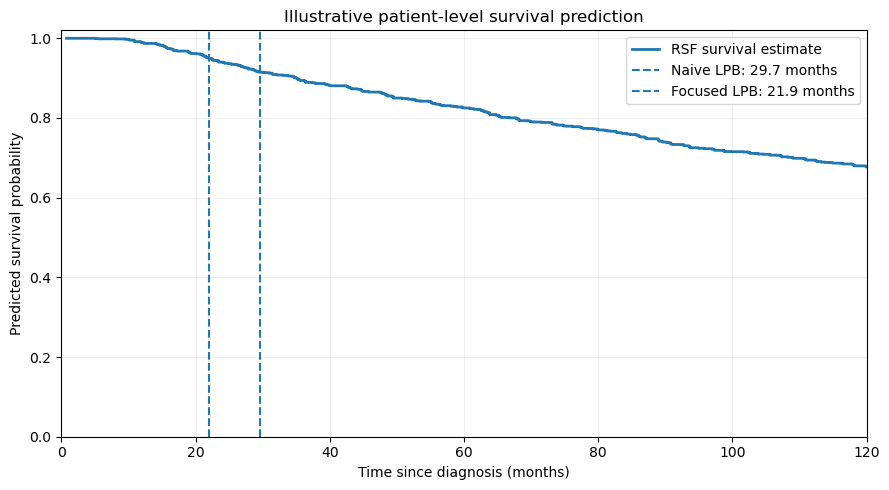

In [60]:

# Hypothetical patient profile
new_patient = pd.DataFrame({
    "Age": [55],
    "Histology": ["Ductal"]
})

# Survival prediction
survival_curve = transport_core_rsf.predict_survival_function(
    new_patient[transport_core_features]
)[0]

# Survival probabilities at selected time points
time_points = [12, 36, 60]

patient_results = {
    "Age": 55,
    "Histology": "Ductal"
}

for t in time_points:
    patient_results[f"Survival at {t} months (%)"] = (
        100 * float(survival_curve(t))
    )

# Conformal lower predictive bounds
patient_quantiles = predict_time_quantiles(
    transport_core_rsf,
    new_patient[transport_core_features],
    tau_grid
)

patient_bounds = {}

for method in ["Naive", "Focused"]:
    tau = transport_calibration[method]["tau"]
    idx = np.argmin(np.abs(tau_grid - tau))

    lower_bound = float(patient_quantiles[idx, 0])
    patient_bounds[method] = lower_bound

    patient_results[f"{method} LPB (months)"] = lower_bound

print("Illustrative patient-level predictions:")
display(pd.DataFrame([patient_results]).round(2))

# Plot the survival curve and conformal bounds
fig, ax = plt.subplots(figsize=(9, 5))

ax.step(
    survival_curve.x,
    survival_curve.y,
    where="post",
    linewidth=2,
    label="RSF survival estimate"
)

for method, lower_bound in patient_bounds.items():
    ax.axvline(
        lower_bound,
        linestyle="--",
        linewidth=1.5,
        label=f"{method} LPB: {lower_bound:.1f} months"
    )

ax.set_xlim(0, 120)
ax.set_ylim(0, 1.02)
ax.set_xlabel("Time since diagnosis (months)")
ax.set_ylabel("Predicted survival probability")
ax.set_title("Illustrative patient-level survival prediction")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()



## 58. Export of Preliminary Results Tables

Previously calculated and numerically verified summary tables were exported as draft CSV files for reproducibility and manuscript preparation.

These tables are preliminary and remain subject to methodological verification. No statistical models or estimates were recalculated.


In [ ]:

# # Export preliminary results
# output_dir = Path("../results/draft_tables")
# output_dir.mkdir(parents=True, exist_ok=True)

# tables = {
#     "DRAFT_01_internal_external": audit_core_summary,
#     "DRAFT_02_conformal_calibration": transport_calibration_summary,
#     "DRAFT_03_external_coverage": external_coverage_summary,
#     "DRAFT_04_external_ipcw": external_ipcw_summary,
#     "DRAFT_05_subgroup_coverage": subgroup_ci,
#     "DRAFT_06_subgroup_differences": subgroup_diff_ci,
#     "DRAFT_07_cross_cohort_comparison": cross_cohort_summary
# }

# for filename, table in tables.items():
#     path = output_dir / f"{filename}.csv"
#     table.to_csv(path, index=False, encoding="utf-8-sig")
#     print("Saved:", path)

# print("\nDraft tables exported:", len(tables))


Saved: ../results/draft_tables/DRAFT_01_internal_external.csv
Saved: ../results/draft_tables/DRAFT_02_conformal_calibration.csv
Saved: ../results/draft_tables/DRAFT_03_external_coverage.csv
Saved: ../results/draft_tables/DRAFT_04_external_ipcw.csv
Saved: ../results/draft_tables/DRAFT_05_subgroup_coverage.csv
Saved: ../results/draft_tables/DRAFT_06_subgroup_differences.csv
Saved: ../results/draft_tables/DRAFT_07_cross_cohort_comparison.csv

Draft tables exported: 7



## 59. Methodological Audit of Conformal Calibration

**Reference:** Davidov H, Feldman S, Shamai G, Kimmel R, Romano Y. *Conformalized Survival Analysis for General Right-Censored Data*. ICLR 2025, Algorithms 1–3.

**Objective:** Independently verify the calibration calculations for the transportable RSF model.

**Checks:** Quantile ordering, miscoverage estimation, selection of calibration levels, and consistency of Naive, Focused, and Fused results.

**Implementation:** The previously fitted models and calibration data are reused without refitting or modifying predictions. The analysis uses a finite quantile grid and does not implement the optional failsafe procedure.




In [62]:

# Review the existing calibration data
n_cal = len(transport_cal_times)

assert transport_quantiles.shape == (len(tau_grid), n_cal)
assert len(transport_p_cal) == n_cal
assert np.all(transport_p_cal > 0)

# Check ordering of finite predicted quantiles
for j in range(n_cal):
    q = transport_quantiles[:, j]
    finite_q = q[np.isfinite(q)]
    assert np.all(np.diff(finite_q) >= -1e-8)

# Miscoverage indicators
errors = (
    transport_quantiles > transport_cal_times[None, :]
)

# Naive calibration
naive_error = errors.mean(axis=1)

# Focused calibration
event_weights = np.where(
    transport_cal_events,
    1 / transport_p_cal,
    0.0
)

focused_error = (
    errors @ event_weights
) / event_weights.sum()

# Reconstruct the Fused selection rule
p_censored = positive_class_probabilities(
    core_selection_model,
    np.column_stack([
        X_core_cal,
        np.zeros(n_cal)
    ])
)

p_observed = positive_class_probabilities(
    core_selection_model,
    np.column_stack([
        X_core_cal,
        np.ones(n_cal)
    ])
)

selection = p_censored < p_observed

fused_weights_check = np.where(
    selection,
    1.0,
    event_weights[:, None]
)

fused_error_check = (
    (errors.T * fused_weights_check).sum(axis=0)
    / fused_weights_check.sum(axis=0)
)

# Recalculate the selected calibration levels
error_curves = {
    "Naive": naive_error,
    "Focused": focused_error,
    "Fused": fused_error_check
}

audit_results = []

for method, error in error_curves.items():

    running_error = np.maximum.accumulate(error)
    eligible = np.flatnonzero(running_error <= alpha)

    assert len(eligible) > 0

    idx = eligible[-1]
    calculated_tau = tau_grid[idx]
    previous_tau = transport_calibration[method]["tau"]

    bounds = transport_quantiles[idx]

    assert np.isfinite(bounds).all()
    assert np.isclose(calculated_tau, previous_tau)

    audit_results.append({
        "Method": method,
        "Previous tau": previous_tau,
        "Verified tau": calculated_tau,
        "Miscoverage": error[idx],
        "Median LPB": np.median(bounds),
        "Included censored": (
            int(selection[~transport_cal_events, idx].sum())
            if method == "Fused" else np.nan
        ),
        "Check": "Passed"
    })

calibration_audit = pd.DataFrame(audit_results)

display(calibration_audit.round(4))

print("\nCalibration calculations verified successfully.")


,Method,Previous tau,Verified tau,Miscoverage,Median LPB,Included censored,Check
0,Naive,0.085,0.085,0.0960,30.9667,NaN,Passed
1,Focused,0.050,0.050,0.0869,21.9333,NaN,Passed
2,Fused,0.085,0.085,0.0960,30.9667,171.0,Passed



Calibration calculations verified successfully.



## 60. Simulation Study: Data-Generating Mechanism

**Methodological references:**

1. Davidov H et al. (2025). *Conformalized Survival Analysis for General Right-Censored Data*. ICLR.
2. Tibshirani RJ et al. (2019). *Conformal Prediction Under Covariate Shift*. NeurIPS.
3. Shin J, Lee CH, Kang S (2025). *Weighted Conformal Prediction for Survival Analysis under Covariate Shift*. arXiv:2512.03738.

**Objective:** Evaluate the empirical coverage and informativeness of conformal survival bounds under controlled changes in patient characteristics, censoring, and event-time distributions.

**Study design:** A log-normal accelerated failure time mechanism was used to generate true event times and censoring times. Five scenarios were considered: no shift, covariate shift, censoring shift, survival mechanism shift, and combined shift.

**Implementation:** This is a study-specific simulation design, not a reproduction of the referenced studies. True event and censoring times are retained strictly for simulation diagnostics and evaluation, and will not be supplied as model predictors.




In [63]:

# Simulation settings
sim_seed = 2026
sim_rng = np.random.default_rng(sim_seed)

sim_n_train = 1200
sim_n_cal = 400
sim_n_test = 800
sim_n_target = 1200

sim_scenarios = {
    "No shift": (False, False, False),
    "Covariate shift": (True, False, False),
    "Censoring shift": (False, True, False),
    "Survival shift": (False, False, True),
    "Combined shift": (True, True, True)
}


def generate_sim_data(n, rng, shifts=(False, False, False)):
    shift_x, shift_c, shift_t = shifts

    # Patient characteristics
    age = rng.normal(
        loc=54 if shift_x else 60,
        scale=10,
        size=n
    )

    lobular = rng.binomial(
        1, 0.30 if shift_x else 0.12, size=n
    )

    # True event times
    log_t = (
        np.log(65)
        - 0.22 * ((age - 60) / 10)
        + 0.20 * lobular
        - 0.50 * shift_t
        + 0.60 * rng.normal(size=n)
    )

    # Censoring times
    log_c = (
        np.log(85)
        - 0.08 * ((age - 60) / 10)
        - 0.90 * shift_c
        + 0.65 * rng.normal(size=n)
    )

    true_t = np.exp(log_t)
    true_c = np.exp(log_c)

    observed_time = np.minimum(true_t, true_c)
    event = (true_t <= true_c).astype(int)

    return pd.DataFrame({
        "Age": age,
        "Histology": np.where(lobular == 1, "Lobular", "Ductal"),
        "Y": observed_time,
        "event": event,
        "T_true": true_t,
        "C_true": true_c
    })


# Source datasets
sim_train = generate_sim_data(sim_n_train, sim_rng)
sim_cal = generate_sim_data(sim_n_cal, sim_rng)
sim_test = generate_sim_data(sim_n_test, sim_rng)

# Target datasets under different shifts
sim_targets = {
    name: generate_sim_data(sim_n_target, sim_rng, shifts)
    for name, shifts in sim_scenarios.items()
}

# Inspect the generated distributions
sim_summary = []

all_sim_data = {
    "Source training": sim_train,
    "Source calibration": sim_cal,
    "Source test": sim_test,
    **sim_targets
}

for name, data in all_sim_data.items():
    sim_summary.append({
        "Dataset": name,
        "Patients": len(data),
        "Mean age": data["Age"].mean(),
        "Lobular (%)": 100 * (data["Histology"] == "Lobular").mean(),
        "Censored (%)": 100 * (data["event"] == 0).mean(),
        "Median observed time": data["Y"].median(),
        "Median true event time": data["T_true"].median()
    })

sim_summary = pd.DataFrame(sim_summary)

display(sim_summary.round(2))

# Basic data checks
for data in all_sim_data.values():
    assert (data["Y"] > 0).all()
    assert (data["T_true"] > 0).all()
    assert (data["C_true"] > 0).all()
    assert (data["Y"] <= data["T_true"]).all()
    assert (data["Y"] <= data["C_true"]).all()

print("\nSimulation data checks passed.")


,Dataset,Patients,Mean age,Lobular (%),Censored (%),Median observed time,Median true event time
0,Source training,1200,60.00,12.58,40.17,53.05,68.02
1,Source calibration,400,60.35,17.25,40.00,49.05,64.46
2,Source test,800,59.90,11.88,40.38,51.74,67.46
3,No shift,1200,59.84,14.42,38.00,51.40,67.10
4,Covariate shift,1200,53.85,28.50,45.17,58.23,80.79
5,Censoring shift,1200,60.43,12.50,76.33,30.94,65.44
6,Survival shift,1200,59.92,12.00,21.08,36.55,40.29
7,Combined shift,1200,53.69,27.83,61.50,29.98,49.14



Simulation data checks passed.



## 61. Pilot Monte Carlo Evaluation of True Predictive Coverage

**Methodological references:**

1. Davidov H et al. (2025). *Conformalized Survival Analysis for General Right-Censored Data*. ICLR 2025.
2. Tibshirani RJ et al. (2019). *Conformal Prediction Under Covariate Shift*. NeurIPS 2019.
3. Shin J, Lee CH, Kang S (2025). *Weighted Conformal Prediction for Survival Analysis under Covariate Shift*. arXiv:2512.03738.

**Objective:** Examine the empirical coverage of survival lower predictive bounds under five controlled distribution-shift scenarios.

**Methods:** A survival forest and auxiliary calibration models were trained on simulated source data. Naive, Focused, Fused, and exploratory shift-weighted variants were evaluated against the fully observed true event times.

**Oracle weighting:** Exact source-to-target density ratios were calculated from the known covariate-generating distributions. No true event times from calibration or target samples were used in model fitting.

**Implementation:** This is a single-replication pilot. Repeated Monte Carlo experiments and comparisons with estimated density ratios will follow after verification. No finite-sample guarantees are claimed for the exploratory weighted Focused combination.



In [64]:

# Pilot simulation: one independent training and calibration experiment
sim_features = ["Age", "Histology"]

sim_y_train = Surv.from_arrays(
    event=sim_train["event"].to_numpy().astype(bool),
    time=sim_train["Y"].to_numpy()
)

# Fit the survival model on simulated source data
sim_rsf = clone(transport_core_rsf)
sim_rsf.set_params(rsf__n_jobs=1)

sim_rsf.fit(sim_train[sim_features], sim_y_train)

# Fit the event-observation probability model
sim_event_model = clone(transport_event_model)
sim_event_model.fit(
    sim_train[sim_features],
    sim_train["event"]
)

sim_p_cal = sim_event_model.predict_proba(
    sim_cal[sim_features]
)[:, 1]

# Survival quantiles and calibration errors
sim_q_cal = predict_time_quantiles(
    sim_rsf, sim_cal[sim_features], tau_grid
)

sim_errors = (
    sim_q_cal > sim_cal["Y"].to_numpy()[None, :]
)

sim_events = sim_cal["event"].to_numpy().astype(bool)

sim_event_weights = np.where(
    sim_events, 1 / sim_p_cal, 0.0
)


def select_sim_level(weighted_errors, total_weight, new_weight=0):
    error = np.maximum.accumulate(
        (weighted_errors + new_weight) /
        (total_weight + new_weight)
    )

    eligible = np.flatnonzero(error <= alpha)
    return int(eligible[-1]) if len(eligible) else 0


# Naive and Focused calibration
sim_naive_idx = select_sim_level(
    sim_errors.sum(axis=1),
    len(sim_cal)
)

sim_focused_idx = select_sim_level(
    sim_errors @ sim_event_weights,
    sim_event_weights.sum()
)

# Fused auxiliary model
sim_train_encoded = sim_rsf.named_steps[
    "preprocessing"
].transform(sim_train[sim_features])

sim_cal_encoded = sim_rsf.named_steps[
    "preprocessing"
].transform(sim_cal[sim_features])

sim_q_train = predict_time_quantiles(
    sim_rsf, sim_train[sim_features], tau_grid
)

sim_labels = (
    sim_train["Y"].to_numpy()[:, None] < sim_q_train.T
).astype(int)

sim_selection_model = clone(core_selection_model)

sim_selection_model.fit(
    np.column_stack([
        sim_train_encoded,
        sim_train["event"].to_numpy()
    ]),
    sim_labels
)

sim_p0 = positive_class_probabilities(
    sim_selection_model,
    np.column_stack([
        sim_cal_encoded, np.zeros(len(sim_cal))
    ])
)

sim_p1 = positive_class_probabilities(
    sim_selection_model,
    np.column_stack([
        sim_cal_encoded, np.ones(len(sim_cal))
    ])
)

sim_include = sim_p0 < sim_p1

sim_fused_weights = np.where(
    sim_include, 1.0, sim_event_weights[:, None]
)

sim_fused_idx = select_sim_level(
    (sim_errors.T * sim_fused_weights).sum(axis=0),
    sim_fused_weights.sum(axis=0)
)

sim_base_levels = {
    "Naive": sim_naive_idx,
    "Focused": sim_focused_idx,
    "Fused": sim_fused_idx
}

print("Source calibration levels:")
for method, idx in sim_base_levels.items():
    print(f"{method}: tau = {tau_grid[idx]:.3f}")


# Exact density ratios from the simulation mechanism
def sim_oracle_weights(data, covariate_shift=False):
    if not covariate_shift:
        return np.ones(len(data))

    age = data["Age"].to_numpy()

    age_ratio = np.exp(
        -0.5 * (
            ((age - 54) / 10) ** 2
            - ((age - 60) / 10) ** 2
        )
    )

    hist_ratio = np.where(
        data["Histology"].to_numpy() == "Lobular",
        0.30 / 0.12,
        0.70 / 0.88
    )

    return age_ratio * hist_ratio


sim_pilot_rows = []

for scenario, target in sim_targets.items():
    has_x_shift = sim_scenarios[scenario][0]

    q_target = predict_time_quantiles(
        sim_rsf, target[sim_features], tau_grid
    )

    w_cal = sim_oracle_weights(sim_cal, has_x_shift)
    w_target = sim_oracle_weights(target, has_x_shift)

    # Fixed unweighted methods
    level_indices = {
        name: np.full(len(target), idx, dtype=int)
        for name, idx in sim_base_levels.items()
    }

    # Target-specific shift-weighted calibration
    for method, base_weights in [
        ("Weighted Naive", w_cal),
        ("Weighted Focused", w_cal * sim_event_weights)
    ]:
        weighted_errors = np.maximum.accumulate(
            sim_errors @ base_weights
        )

        adjusted_errors = (
            weighted_errors[:, None] + w_target[None, :]
        ) / (
            base_weights.sum() + w_target[None, :]
        )

        admissible = adjusted_errors <= alpha

        indices = np.where(
            admissible,
            np.arange(len(tau_grid))[:, None],
            -1
        ).max(axis=0)

        level_indices[method] = np.maximum(indices, 0)

    # Evaluate coverage against the actual event times
    for method, indices in level_indices.items():
        bounds = q_target[
            indices, np.arange(len(target))
        ]

        assert np.isfinite(bounds).all()

        sim_pilot_rows.append({
            "Scenario": scenario,
            "Method": method,
            "True coverage (%)": 100 * np.mean(
                target["T_true"].to_numpy() >= bounds
            ),
            "Median LPB": np.median(bounds),
            "Mean LPB": bounds.mean()
        })

sim_pilot_results = pd.DataFrame(sim_pilot_rows)

print("\nTrue coverage across simulation scenarios (%):")
display(
    sim_pilot_results.pivot(
        index="Scenario",
        columns="Method",
        values="True coverage (%)"
    ).round(2)
)

print("\nMedian lower predictive bounds (months):")
display(
    sim_pilot_results.pivot(
        index="Scenario",
        columns="Method",
        values="Median LPB"
    ).round(2)
)

print("\nPilot simulation completed.")


Source calibration levels:
Naive: tau = 0.040
Focused: tau = 0.040
Fused: tau = 0.040

True coverage across simulation scenarios (%):


Method,Focused,Fused,Naive,Weighted Focused,Weighted Naive
Scenario,,,,,
Censoring shift,94.17,94.17,94.17,94.17,94.17
Combined shift,79.17,79.17,79.17,81.50,82.50
Covariate shift,95.00,95.00,95.00,95.42,96.00
No shift,94.50,94.50,94.50,94.50,94.50
Survival shift,80.17,80.17,80.17,80.17,80.17



Median lower predictive bounds (months):


Method,Focused,Fused,Naive,Weighted Focused,Weighted Naive
Scenario,,,,,
Censoring shift,24.81,24.81,24.81,24.81,24.81
Combined shift,33.03,33.03,33.03,32.69,30.77
Covariate shift,32.69,32.69,32.69,28.98,28.52
No shift,24.96,24.96,24.96,24.96,24.96
Survival shift,24.96,24.96,24.96,24.96,24.96



Pilot simulation completed.



## 62. Pilot Calibration Diagnostics

**Methodological reference:** Davidov H, Feldman S, Shamai G, Kimmel R, Romano Y. *Conformalized Survival Analysis for General Right-Censored Data*. ICLR 2025, Algorithms 1–3.

**Objective:** Investigate why Naive, Focused, and Fused Calibration selected identical quantile levels in the pilot simulation.

**Method:** Calibration miscoverage curves, adjacent candidate quantile levels, and censored-observation inclusion were examined using the existing simulated calibration data.

**Implementation:** Diagnostic analysis only. No models were refitted, no thresholds were modified, and no new simulation data were generated.



In [65]:

# Reconstruct calibration error curves
sim_error_curves = {
    "Naive": sim_errors.mean(axis=1),

    "Focused": (
        (sim_errors @ sim_event_weights)
        / sim_event_weights.sum()
    ),

    "Fused": (
        (sim_errors.T * sim_fused_weights).sum(axis=0)
        / sim_fused_weights.sum(axis=0)
    )
}

sim_diagnostics = []

for method, errors in sim_error_curves.items():
    running_error = np.maximum.accumulate(errors)

    idx = sim_base_levels[method]
    next_idx = min(idx + 1, len(tau_grid) - 1)

    sim_diagnostics.append({
        "Method": method,
        "Selected tau": tau_grid[idx],
        "Error at selected tau": errors[idx],
        "Next tau": tau_grid[next_idx],
        "Error at next tau": errors[next_idx],
        "Next tau admissible": running_error[next_idx] <= alpha,
        "Included censored": (
            int(sim_include[~sim_events, idx].sum())
            if method == "Fused" else np.nan
        )
    })

sim_diagnostic_summary = pd.DataFrame(sim_diagnostics)

display(sim_diagnostic_summary.round(4))

# Additional diagnostics
sim_oracle_w = sim_oracle_weights(
    sim_cal, covariate_shift=True
)

sim_ess = (
    sim_oracle_w.sum() ** 2
    / np.sum(sim_oracle_w ** 2)
)

print("\nCalibration diagnostics:")
print("Calibration patients:", len(sim_cal))
print("Observed deaths:", sim_events.sum())
print("Censored:", (~sim_events).sum())
print("Target miscoverage:", alpha)

print("\nOracle covariate-shift weights:")
print("Minimum:", round(sim_oracle_w.min(), 4))
print("Maximum:", round(sim_oracle_w.max(), 4))
print("Effective sample size:", round(sim_ess, 2))


,Method,Selected tau,Error at selected tau,Next tau,Error at next tau,Next tau admissible,Included censored
0,Naive,0.04,0.0875,0.045,0.1100,False,NaN
1,Focused,0.04,0.0954,0.045,0.1113,False,NaN
2,Fused,0.04,0.0954,0.045,0.1113,False,0.0



Calibration diagnostics:
Calibration patients: 400
Observed deaths: 240
Censored: 160
Target miscoverage: 0.1

Oracle covariate-shift weights:
Minimum: 0.1032
Maximum: 5.4764
Effective sample size: 238.68



## 63. Oracle Monte Carlo Benchmark

**Methodological references:**

1. Davidov H et al. (2025). Conformalized Survival Analysis for General Right-Censored Data. ICLR.
2. Tibshirani RJ et al. (2019). Conformal Prediction Under Covariate Shift. NeurIPS.

**Objective:** Separate errors in conformal calibration from errors in survival-model estimation, event-observation probability estimation, and censoring adjustment.

**Design:** One hundred independent Monte Carlo replications were generated across five distribution-shift scenarios. True source survival quantiles, event-observation probabilities, and covariate density ratios were calculated analytically from the data-generating mechanism.

**Methods:** Naive, Focused, and exploratory shift-weighted versions were evaluated using true target survival times. Oracle conditional IPCW estimates were compared with empirical true coverage.

**Limitations:** This is an oracle benchmark, not a learned-model experiment. Fused Calibration will be investigated separately in the full RSF simulation. Weighted Focused remains an exploratory extension without a claimed finite-sample coverage guarantee.



In [66]:

from scipy.stats import norm

sim_oracle_tau = tau_grid[
    (tau_grid > 0) & (tau_grid < 1)
]

sim_oracle_z = norm.ppf(sim_oracle_tau)


def oracle_survival_quantiles(data):
    age = data["Age"].to_numpy()
    lobular = (data["Histology"].to_numpy() == "Lobular")

    mu_t = (
        np.log(65)
        - 0.22 * ((age - 60) / 10)
        + 0.20 * lobular
    )

    return np.exp(
        mu_t[None, :] + 0.60 * sim_oracle_z[:, None]
    )


def oracle_event_probability(data):
    age = data["Age"].to_numpy()
    lobular = (data["Histology"].to_numpy() == "Lobular")

    mu_t = (
        np.log(65)
        - 0.22 * ((age - 60) / 10)
        + 0.20 * lobular
    )

    mu_c = np.log(85) - 0.08 * ((age - 60) / 10)

    return norm.cdf(
        (mu_c - mu_t) / np.sqrt(0.60**2 + 0.65**2)
    )


def oracle_censor_survival(data, censoring_shift=False):
    age = data["Age"].to_numpy()
    times = data["Y"].to_numpy()

    mu_c = (
        np.log(85)
        - 0.08 * ((age - 60) / 10)
        - 0.90 * int(censoring_shift)
    )

    return norm.sf(
        (np.log(times) - mu_c) / 0.65
    )


def oracle_select_level(errors, weights):
    curve = (errors @ weights) / weights.sum()
    curve = np.maximum.accumulate(curve)

    eligible = np.flatnonzero(curve <= alpha)

    return int(eligible[-1]) if len(eligible) else -1


def oracle_weighted_levels(errors, weights, target_weights):
    cumulative_errors = np.maximum.accumulate(
        errors @ weights
    )

    rates = (
        cumulative_errors[:, None] + target_weights[None, :]
    ) / (
        weights.sum() + target_weights[None, :]
    )

    return np.where(
        rates <= alpha,
        np.arange(len(sim_oracle_tau))[:, None],
        -1
    ).max(axis=0)


sim_oracle_rng = np.random.default_rng(2027)
sim_oracle_reps = 100
sim_oracle_records = []

for rep in range(sim_oracle_reps):

    cal = generate_sim_data(
        sim_n_cal, sim_oracle_rng
    )

    q_cal = oracle_survival_quantiles(cal)
    errors = q_cal > cal["Y"].to_numpy()[None, :]

    p_event = oracle_event_probability(cal)

    focused_weights = np.where(
        cal["event"].to_numpy() == 1,
        1 / p_event,
        0.0
    )

    base_levels = {
        "Naive": oracle_select_level(
            errors, np.ones(len(cal))
        ),
        "Focused": oracle_select_level(
            errors, focused_weights
        )
    }

    for scenario, shifts in sim_scenarios.items():

        target = generate_sim_data(
            sim_n_target, sim_oracle_rng, shifts
        )

        q_target = oracle_survival_quantiles(target)

        has_x_shift = shifts[0]
        has_c_shift = shifts[1]

        w_cal = sim_oracle_weights(
            cal, has_x_shift
        )

        w_target = sim_oracle_weights(
            target, has_x_shift
        )

        levels = {
            name: np.full(len(target), idx, dtype=int)
            for name, idx in base_levels.items()
        }

        levels["Weighted Naive"] = oracle_weighted_levels(
            errors, w_cal, w_target
        )

        levels["Weighted Focused"] = oracle_weighted_levels(
            errors, w_cal * focused_weights, w_target
        )

        true_times = target["T_true"].to_numpy()
        observed_times = target["Y"].to_numpy()
        events = target["event"].to_numpy() == 1

        g_true = oracle_censor_survival(
            target, has_c_shift
        )

        for method, indices in levels.items():

            bounds = np.zeros(len(target))
            valid = indices >= 0

            bounds[valid] = q_target[
                indices[valid],
                np.flatnonzero(valid)
            ]

            true_coverage = 100 * np.mean(
                true_times >= bounds
            )

            misses = events & (observed_times < bounds)

            oracle_ipcw = 100 * (
                1 - np.sum(1 / g_true[misses]) / len(target)
            )

            sim_oracle_records.append({
                "Replication": rep + 1,
                "Scenario": scenario,
                "Method": method,
                "True coverage (%)": true_coverage,
                "Oracle IPCW (%)": oracle_ipcw,
                "IPCW bias (pp)": oracle_ipcw - true_coverage,
                "Median LPB": np.median(bounds)
            })

sim_oracle_results = pd.DataFrame(sim_oracle_records)

sim_oracle_summary = (
    sim_oracle_results
    .groupby(["Scenario", "Method"], sort=False)
    .agg(
        Mean_coverage=("True coverage (%)", "mean"),
        Coverage_SD=("True coverage (%)", "std"),
        Under_90_pct=(
            "True coverage (%)",
            lambda x: 100 * (x < 90).mean()
        ),
        Mean_IPCW_bias=("IPCW bias (pp)", "mean"),
        Median_LPB=("Median LPB", "mean")
    )
    .reset_index()
)

sim_oracle_summary["MC_SE"] = (
    sim_oracle_summary["Coverage_SD"]
    / np.sqrt(sim_oracle_reps)
)

print("Mean true coverage (%):")
display(
    sim_oracle_summary.pivot(
        index="Scenario",
        columns="Method",
        values="Mean_coverage"
    ).round(2)
)

print("\nMonte Carlo summary:")
display(
    sim_oracle_summary[
        [
            "Scenario", "Method", "Mean_coverage",
            "MC_SE", "Under_90_pct",
            "Mean_IPCW_bias", "Median_LPB"
        ]
    ].round(3)
)

print("\nCompleted replications:", sim_oracle_reps)
print("All estimates finite:",
      np.isfinite(
          sim_oracle_results[
              ["True coverage (%)", "Oracle IPCW (%)"]
          ].to_numpy()
      ).all())


Mean true coverage (%):


Method,Focused,Naive,Weighted Focused,Weighted Naive
Scenario,,,,
Censoring shift,93.93,93.87,94.04,94.06
Combined shift,76.73,76.47,78.72,80.01
Covariate shift,94.02,93.97,94.72,95.20
No shift,94.05,93.95,94.16,94.14
Survival shift,76.49,76.26,76.75,76.75



Monte Carlo summary:


,Scenario,Method,Mean_coverage,MC_SE,Under_90_pct,Mean_IPCW_bias,Median_LPB
0,No shift,Naive,93.951,0.115,0.0,-0.008,26.169
1,No shift,Focused,94.046,0.127,0.0,-0.011,26.051
2,No shift,Weighted Naive,94.142,0.112,0.0,-0.011,25.917
3,No shift,Weighted Focused,94.157,0.126,0.0,-0.012,25.895
4,Covariate shift,Naive,93.971,0.119,0.0,0.012,30.953
5,Covariate shift,Focused,94.016,0.136,0.0,0.014,30.813
6,Covariate shift,Weighted Naive,95.204,0.140,0.0,0.002,28.853
7,Covariate shift,Weighted Focused,94.725,0.173,1.0,0.010,29.659
8,Censoring shift,Naive,93.872,0.118,0.0,-0.001,26.227
9,Censoring shift,Focused,93.929,0.135,0.0,-0.029,26.110



Completed replications: 100
All estimates finite: True



## 64. Adverse Covariate Shift Under Survival-Model Misspecification

**References:**

1. Tibshirani RJ et al. (2019). Conformal Prediction Under Covariate Shift. NeurIPS.
2. Davidov H et al. (2025). Conformalized Survival Analysis for General Right-Censored Data. ICLR.

**Objective:** Evaluate whether covariate-shift weighting improves predictive coverage when the working survival model is misspecified and the target population contains patients with less favorable prognostic characteristics.

**Design:** Three scenarios were evaluated: no covariate shift, favorable covariate shift, and adverse covariate shift. Conditional event-time and censoring mechanisms were held constant.

**Working model:** A deliberately misspecified log-normal quantile model underestimated the age effect and omitted histology.

**Calibration:** Naive, Focused, Weighted Naive, and exploratory Weighted Focused methods were compared. Exact source-to-target density ratios and source event-observation probabilities were used.

**Evaluation:** One hundred independent Monte Carlo replications were performed. True coverage, Monte Carlo standard error, the frequency of coverage below 90%, and median lower predictive bounds were recorded.

**Limitations:** This is a controlled misspecification experiment, not the final learned-RSF benchmark. The simulation design and weighted Focused extension are study-specific.




In [67]:

# Controlled covariate-shift scenarios
sim_stress_settings = {
    "No shift": (60, 0.12),
    "Favorable shift": (54, 0.30),
    "Adverse shift": (70, 0.04)
}

sim_stress_tau = sim_oracle_tau
sim_stress_z = norm.ppf(sim_stress_tau)


def sim_stress_sample(n, rng, age_mean, lobular_prob):
    age = rng.normal(age_mean, 10, n)
    lobular = rng.binomial(1, lobular_prob, n)

    log_t = (
        np.log(65)
        - 0.22 * ((age - 60) / 10)
        + 0.20 * lobular
        + 0.60 * rng.normal(size=n)
    )

    log_c = (
        np.log(85)
        - 0.08 * ((age - 60) / 10)
        + 0.65 * rng.normal(size=n)
    )

    true_t = np.exp(log_t)
    true_c = np.exp(log_c)

    return pd.DataFrame({
        "Age": age,
        "Histology": np.where(lobular == 1, "Lobular", "Ductal"),
        "Y": np.minimum(true_t, true_c),
        "event": (true_t <= true_c).astype(int),
        "T_true": true_t
    })


def sim_working_quantiles(data):
    age = data["Age"].to_numpy()

    # Deliberately underestimate the age effect
    # and omit the histological effect
    mu = np.log(65) - 0.05 * ((age - 60) / 10)

    return np.exp(
        mu[None, :] + 0.60 * sim_stress_z[:, None]
    )


def sim_stress_ratio(data, age_mean, lobular_prob):
    age = data["Age"].to_numpy()
    lobular = data["Histology"].to_numpy() == "Lobular"

    log_age_ratio = (
        norm.logpdf(age, loc=age_mean, scale=10)
        - norm.logpdf(age, loc=60, scale=10)
    )

    hist_ratio = np.where(
        lobular,
        lobular_prob / 0.12,
        (1 - lobular_prob) / 0.88
    )

    return np.exp(log_age_ratio) * hist_ratio


def sim_stress_select(errors, weights):
    curve = np.maximum.accumulate(
        (errors @ weights) / weights.sum()
    )

    eligible = np.flatnonzero(curve <= alpha)

    return int(eligible[-1]) if len(eligible) else -1


def sim_stress_weighted_select(errors, weights, new_weights):
    weighted_errors = np.maximum.accumulate(
        errors @ weights
    )

    rates = (
        weighted_errors[:, None] + new_weights[None, :]
    ) / (
        weights.sum() + new_weights[None, :]
    )

    return np.where(
        rates <= alpha,
        np.arange(errors.shape[0])[:, None],
        -1
    ).max(axis=0)


sim_stress_rng = np.random.default_rng(2030)
sim_stress_reps = 100
sim_stress_records = []

for rep in range(sim_stress_reps):
    cal = sim_stress_sample(
        sim_n_cal, sim_stress_rng, 60, 0.12
    )

    q_cal = sim_working_quantiles(cal)
    errors = q_cal > cal["Y"].to_numpy()[None, :]

    events = cal["event"].to_numpy().astype(bool)
    p_event = oracle_event_probability(cal)

    event_weights = np.where(
        events, 1 / p_event, 0.0
    )

    base_levels = {
        "Naive": sim_stress_select(
            errors, np.ones(len(cal))
        ),
        "Focused": sim_stress_select(
            errors, event_weights
        )
    }

    for scenario, (age_mean, lobular_prob) in sim_stress_settings.items():

        target = sim_stress_sample(
            sim_n_target,
            sim_stress_rng,
            age_mean,
            lobular_prob
        )

        q_target = sim_working_quantiles(target)

        w_cal = sim_stress_ratio(
            cal, age_mean, lobular_prob
        )

        w_target = sim_stress_ratio(
            target, age_mean, lobular_prob
        )

        assert np.isfinite(w_cal).all()
        assert np.isfinite(w_target).all()
        assert (w_cal > 0).all()
        assert (w_target > 0).all()

        levels = {
            method: np.full(len(target), idx, dtype=int)
            for method, idx in base_levels.items()
        }

        levels["Weighted Naive"] = sim_stress_weighted_select(
            errors, w_cal, w_target
        )

        levels["Weighted Focused"] = sim_stress_weighted_select(
            errors, w_cal * event_weights, w_target
        )

        true_times = target["T_true"].to_numpy()

        ess = w_cal.sum() ** 2 / np.sum(w_cal ** 2)

        for method, indices in levels.items():

            bounds = np.zeros(len(target))
            valid = indices >= 0

            bounds[valid] = q_target[
                indices[valid],
                np.flatnonzero(valid)
            ]

            sim_stress_records.append({
                "Replication": rep + 1,
                "Scenario": scenario,
                "Method": method,
                "Coverage (%)": 100 * np.mean(
                    true_times >= bounds
                ),
                "Median LPB": np.median(bounds),
                "Density weight ESS": ess
            })


sim_stress_results = pd.DataFrame(sim_stress_records)

sim_stress_summary = (
    sim_stress_results
    .groupby(["Scenario", "Method"])
    .agg(
        Mean_coverage=("Coverage (%)", "mean"),
        Coverage_SD=("Coverage (%)", "std"),
        Under_90_pct=(
            "Coverage (%)",
            lambda x: 100 * (x < 90).mean()
        ),
        Mean_median_LPB=("Median LPB", "mean"),
        Mean_ESS=("Density weight ESS", "mean")
    )
    .reset_index()
)

sim_stress_summary["MC_SE"] = (
    sim_stress_summary["Coverage_SD"]
    / np.sqrt(sim_stress_reps)
)

print("Mean true coverage (%):")
display(
    sim_stress_summary.pivot(
        index="Scenario",
        columns="Method",
        values="Mean_coverage"
    ).round(2)
)

print("\nFull Monte Carlo summary:")
display(
    sim_stress_summary[
        [
            "Scenario", "Method", "Mean_coverage",
            "MC_SE", "Under_90_pct",
            "Mean_median_LPB", "Mean_ESS"
        ]
    ].round(3)
)

assert np.isfinite(
    sim_stress_results[
        ["Coverage (%)", "Median LPB", "Density weight ESS"]
    ].to_numpy()
).all()

print("\nCompleted replications:", sim_stress_reps)
print("All simulation checks passed.")


Mean true coverage (%):


Method,Focused,Naive,Weighted Focused,Weighted Naive
Scenario,,,,
Adverse shift,89.37,88.68,94.00,93.34
Favorable shift,95.94,95.58,94.16,94.28
No shift,93.83,93.38,93.92,93.53



Full Monte Carlo summary:


,Scenario,Method,Mean_coverage,MC_SE,Under_90_pct,Mean_median_LPB,Mean_ESS
0,Adverse shift,Focused,89.372,0.207,64.0,24.080,144.758
1,Adverse shift,Naive,88.681,0.152,82.0,24.647,144.758
2,Adverse shift,Weighted Focused,94.003,0.222,2.0,20.160,144.758
3,Adverse shift,Weighted Naive,93.338,0.230,8.0,20.803,144.758
4,Favorable shift,Focused,95.937,0.102,0.0,26.073,219.650
5,Favorable shift,Naive,95.584,0.082,0.0,26.686,219.650
6,Favorable shift,Weighted Focused,94.162,0.147,0.0,28.873,219.650
7,Favorable shift,Weighted Naive,94.279,0.106,0.0,28.810,219.650
8,No shift,Focused,93.833,0.133,0.0,25.303,400.000
9,No shift,Naive,93.378,0.103,0.0,25.900,400.000



Completed replications: 100
All simulation checks passed.



## 65. Learned RSF Under Covariate Shift

**References:**

1. Davidov et al. (2025). Conformalized Survival Analysis for General Right-Censored Data. ICLR.
2. Tibshirani et al. (2019). Conformal Prediction Under Covariate Shift. NeurIPS.

**Objective:** Evaluate the effects of estimating survival distributions, event-observation probabilities, and source-to-target density ratios on predictive coverage.

**Design:** Independent source training and calibration samples were generated in each replication. Three target populations were examined: no shift, favorable covariate shift, and adverse covariate shift.

**Models:** A Random Survival Forest estimated survival quantiles. Logistic regression estimated event-observation probabilities and cohort-membership probabilities.

**Comparisons:** Oracle and estimated nuisance-model quantities were compared under otherwise identical simulated samples.

**Evaluation:** True survival-time coverage, median lower predictive bounds, and density-weight effective sample sizes were assessed.

**Implementation:** This is a 10-replication computational pilot. Model settings were fixed without target-outcome tuning. The weighted Focused procedure remains exploratory.




In [68]:

sim_learn_rng = np.random.default_rng(2040)
sim_learn_reps = 10

sim_learn_features = ["Age", "Histology"]
sim_learn_records = []


def sim_density_ess(weights):
    return weights.sum() ** 2 / np.sum(weights ** 2)


for rep in range(sim_learn_reps):

    # Independent source samples
    train = sim_stress_sample(
        sim_n_train, sim_learn_rng, 60, 0.12
    )

    cal = sim_stress_sample(
        sim_n_cal, sim_learn_rng, 60, 0.12
    )

    y_train_sim = Surv.from_arrays(
        event=train["event"].to_numpy().astype(bool),
        time=train["Y"].to_numpy()
    )

    # Fit RSF using source training data only
    model = clone(transport_core_rsf)

    model.set_params(
        rsf__n_estimators=120,
        rsf__n_jobs=1,
        rsf__oob_score=False,
        rsf__random_state=2040 + rep
    )

    model.fit(train[sim_learn_features], y_train_sim)

    # Estimate event-observation probabilities
    event_model = Pipeline([
        ("preprocessing", clone(domain_preprocessor)),
        ("classifier", LogisticRegression(max_iter=1000))
    ])

    event_model.fit(
        train[sim_learn_features],
        train["event"]
    )

    p_est = event_model.predict_proba(
        cal[sim_learn_features]
    )[:, 1]

    p_oracle = oracle_event_probability(cal)

    cal_events = cal["event"].to_numpy().astype(bool)

    estimated_event_weights = np.where(
        cal_events, 1 / p_est, 0.0
    )

    oracle_event_weights = np.where(
        cal_events, 1 / p_oracle, 0.0
    )

    # Calibration quantiles
    q_cal = predict_time_quantiles(
        model, cal[sim_learn_features], tau_grid
    )

    errors = (
        q_cal > cal["Y"].to_numpy()[None, :]
    )

    base_levels = {
        "Naive": sim_stress_select(
            errors, np.ones(len(cal))
        ),
        "Focused estimated p": sim_stress_select(
            errors, estimated_event_weights
        ),
        "Focused oracle p": sim_stress_select(
            errors, oracle_event_weights
        )
    }

    for scenario, (age_mean, lobular_prob) in sim_stress_settings.items():

        target = sim_stress_sample(
            sim_n_target,
            sim_learn_rng,
            age_mean,
            lobular_prob
        )

        q_target = predict_time_quantiles(
            model, target[sim_learn_features], tau_grid
        )

        # Oracle density ratios
        w_cal_oracle = sim_stress_ratio(
            cal, age_mean, lobular_prob
        )

        w_target_oracle = sim_stress_ratio(
            target, age_mean, lobular_prob
        )

        # Estimate density ratios using source and target covariates
        domain_X_sim = pd.concat([
            train[sim_learn_features],
            target[sim_learn_features]
        ], ignore_index=True)

        domain_y_sim = np.r_[
            np.zeros(len(train), dtype=int),
            np.ones(len(target), dtype=int)
        ]

        domain_classifier = Pipeline([
            ("preprocessing", clone(domain_preprocessor)),
            ("classifier", LogisticRegression(max_iter=1000))
        ])

        domain_classifier.fit(
            domain_X_sim, domain_y_sim
        )

        p_cal_target = domain_classifier.predict_proba(
            cal[sim_learn_features]
        )[:, 1]

        p_new_target = domain_classifier.predict_proba(
            target[sim_learn_features]
        )[:, 1]

        assert np.all((p_cal_target > 0) & (p_cal_target < 1))
        assert np.all((p_new_target > 0) & (p_new_target < 1))

        prior_ratio = len(train) / len(target)

        w_cal_est = (
            p_cal_target / (1 - p_cal_target)
        ) * prior_ratio

        w_target_est = (
            p_new_target / (1 - p_new_target)
        ) * prior_ratio

        n_target = len(target)

        levels = {
            name: np.full(n_target, idx, dtype=int)
            for name, idx in base_levels.items()
        }

        # Oracle and estimated density-weight comparisons
        weighted_settings = {
            "W-Naive oracle": (
                w_cal_oracle, w_target_oracle
            ),
            "W-Naive estimated": (
                w_cal_est, w_target_est
            ),
            "W-Focused oracle": (
                w_cal_oracle * oracle_event_weights,
                w_target_oracle
            ),
            "W-Focused estimated": (
                w_cal_est * estimated_event_weights,
                w_target_est
            )
        }

        for name, (cal_weights, target_weights) in weighted_settings.items():
            levels[name] = sim_stress_weighted_select(
                errors, cal_weights, target_weights
            )

        true_times = target["T_true"].to_numpy()

        for method, indices in levels.items():

            bounds = np.zeros(n_target)
            valid = indices >= 0

            bounds[valid] = q_target[
                indices[valid],
                np.flatnonzero(valid)
            ]

            sim_learn_records.append({
                "Replication": rep + 1,
                "Scenario": scenario,
                "Method": method,
                "Coverage (%)": 100 * np.mean(
                    true_times >= bounds
                ),
                "Median LPB": np.median(bounds),
                "Zero bounds (%)": 100 * np.mean(bounds == 0),
                "Oracle density ESS": sim_density_ess(w_cal_oracle),
                "Estimated density ESS": sim_density_ess(w_cal_est)
            })

    print(f"Replication {rep + 1}/{sim_learn_reps} completed.")


sim_learn_results = pd.DataFrame(sim_learn_records)

sim_learn_summary = (
    sim_learn_results
    .groupby(["Scenario", "Method"])
    .agg(
        Mean_coverage=("Coverage (%)", "mean"),
        Coverage_SD=("Coverage (%)", "std"),
        Mean_median_LPB=("Median LPB", "mean"),
        Under_90_pct=(
            "Coverage (%)",
            lambda x: 100 * (x < 90).mean()
        ),
        Mean_zero_bounds=("Zero bounds (%)", "mean"),
        Mean_oracle_ESS=("Oracle density ESS", "mean"),
        Mean_estimated_ESS=("Estimated density ESS", "mean")
    )
    .reset_index()
)

sim_learn_summary["MC_SE"] = (
    sim_learn_summary["Coverage_SD"]
    / np.sqrt(sim_learn_reps)
)

print("\nTrue coverage (%):")
display(
    sim_learn_summary.pivot(
        index="Scenario",
        columns="Method",
        values="Mean_coverage"
    ).round(2)
)

print("\nMonte Carlo diagnostics:")
display(
    sim_learn_summary[
        [
            "Scenario", "Method", "Mean_coverage",
            "MC_SE", "Under_90_pct",
            "Mean_median_LPB", "Mean_zero_bounds",
            "Mean_oracle_ESS", "Mean_estimated_ESS"
        ]
    ].round(3)
)

assert np.isfinite(
    sim_learn_results.select_dtypes(include="number").to_numpy()
).all()

print("\nAll learned-RSF simulation checks passed.")


Replication 1/10 completed.
Replication 2/10 completed.
Replication 3/10 completed.
Replication 4/10 completed.
Replication 5/10 completed.
Replication 6/10 completed.
Replication 7/10 completed.
Replication 8/10 completed.
Replication 9/10 completed.
Replication 10/10 completed.

True coverage (%):


Method,Focused estimated p,Focused oracle p,Naive,W-Focused estimated,W-Focused oracle,W-Naive estimated,W-Naive oracle
Scenario,,,,,,,
Adverse shift,92.76,92.76,92.63,94.03,93.94,93.79,93.72
Favorable shift,94.12,94.12,93.85,93.94,93.92,94.54,94.62
No shift,93.67,93.67,93.35,94.07,94.02,93.87,93.73



Monte Carlo diagnostics:


,Scenario,Method,Mean_coverage,MC_SE,Under_90_pct,Mean_median_LPB,Mean_zero_bounds,Mean_oracle_ESS,Mean_estimated_ESS
0,Adverse shift,Focused estimated p,92.758,0.639,10.0,21.112,0.000,149.419,148.552
1,Adverse shift,Focused oracle p,92.758,0.639,10.0,21.112,0.000,149.419,148.552
2,Adverse shift,Naive,92.633,0.610,10.0,21.335,0.000,149.419,148.552
3,Adverse shift,W-Focused estimated,94.033,0.660,10.0,19.940,0.358,149.419,148.552
4,Adverse shift,W-Focused oracle,93.942,0.670,10.0,19.868,0.417,149.419,148.552
5,Adverse shift,W-Naive estimated,93.792,0.608,10.0,20.319,0.350,149.419,148.552
6,Adverse shift,W-Naive oracle,93.725,0.636,10.0,20.429,0.367,149.419,148.552
7,Favorable shift,Focused estimated p,94.125,0.563,0.0,29.327,0.000,210.893,211.571
8,Favorable shift,Focused oracle p,94.125,0.563,0.0,29.327,0.000,210.893,211.571
9,Favorable shift,Naive,93.850,0.460,0.0,29.936,0.000,210.893,211.571



All learned-RSF simulation checks passed.



## 66. Repeated Monte Carlo Evaluation of Learned RSF

**Methodological references:**

1. Davidov H et al. (2025). *Conformalized Survival Analysis for General Right-Censored Data*. ICLR 2025.
2. Tibshirani RJ et al. (2019). *Conformal Prediction Under Covariate Shift*. NeurIPS 2019.

**Objective:** Evaluate the stability of censoring-aware conformal lower bounds under covariate shift when survival predictions and nuisance quantities are estimated from data.

**Design:** One hundred independent Monte Carlo replications were conducted under no shift, favorable shift, and adverse shift. Source training, source calibration, and target evaluation samples were independently generated for each replication.

**Methods:** RSF-based survival quantiles, Naive and Focused Calibration, and exploratory shift-weighted extensions were evaluated. Oracle and estimated density ratios were compared using identical calibration and target samples.

**Outcomes:** True coverage, Monte Carlo standard error, paired coverage differences, median lower predictive bound, zero-bound frequency, and effective sample size.

**Implementation:** Model configurations were fixed before this analysis. Target event times were used exclusively for evaluation. No results were saved pending diagnostic verification.

**Limitations:** The weighted Focused extension has no established finite-sample guarantee. This experiment does not yet include the independent survival-conformal benchmark or Fused selection model.



In [69]:

sim_mc_rng = np.random.default_rng(2066)
sim_mc_reps = 100
sim_mc_records = []

features = ["Age", "Histology"]

for rep in range(sim_mc_reps):

    train = sim_stress_sample(
        sim_n_train, sim_mc_rng, 60, 0.12
    )
    cal = sim_stress_sample(
        sim_n_cal, sim_mc_rng, 60, 0.12
    )

    y_train_mc = Surv.from_arrays(
        event=train["event"].to_numpy().astype(bool),
        time=train["Y"].to_numpy()
    )

    # Survival model
    rsf = clone(transport_core_rsf)
    rsf.set_params(
        rsf__n_estimators=120,
        rsf__n_jobs=1,
        rsf__oob_score=False,
        rsf__random_state=2066 + rep
    )
    rsf.fit(train[features], y_train_mc)

    # Event-observation model
    event_model = Pipeline([
        ("preprocessing", clone(domain_preprocessor)),
        ("classifier", LogisticRegression(max_iter=1000))
    ])
    event_model.fit(train[features], train["event"])

    p_est = event_model.predict_proba(cal[features])[:, 1]
    p_oracle = oracle_event_probability(cal)

    assert np.all(p_est > 0)

    events = cal["event"].to_numpy().astype(bool)

    event_weights_est = np.where(events, 1 / p_est, 0.0)
    event_weights_oracle = np.where(events, 1 / p_oracle, 0.0)

    # Calibration errors
    q_cal = predict_time_quantiles(
        rsf, cal[features], tau_grid
    )
    errors = q_cal > cal["Y"].to_numpy()[None, :]

    base_levels = {
        "Naive": sim_stress_select(
            errors, np.ones(len(cal))
        ),
        "Focused estimated": sim_stress_select(
            errors, event_weights_est
        ),
        "Focused oracle": sim_stress_select(
            errors, event_weights_oracle
        )
    }

    # Target populations
    for scenario, (age_mean, lobular_prob) in sim_stress_settings.items():

        target = sim_stress_sample(
            sim_n_target, sim_mc_rng, age_mean, lobular_prob
        )

        q_target = predict_time_quantiles(
            rsf, target[features], tau_grid
        )

        # Oracle density ratios
        w_cal_true = sim_stress_ratio(
            cal, age_mean, lobular_prob
        )
        w_target_true = sim_stress_ratio(
            target, age_mean, lobular_prob
        )

        # Estimated density ratios
        domain_X_mc = pd.concat(
            [train[features], target[features]],
            ignore_index=True
        )
        domain_y_mc = np.r_[
            np.zeros(len(train), dtype=int),
            np.ones(len(target), dtype=int)
        ]

        domain = Pipeline([
            ("preprocessing", clone(domain_preprocessor)),
            ("classifier", LogisticRegression(max_iter=1000))
        ])
        domain.fit(domain_X_mc, domain_y_mc)

        p_cal = domain.predict_proba(cal[features])[:, 1]
        p_target = domain.predict_proba(target[features])[:, 1]

        assert np.all((p_cal > 0) & (p_cal < 1))
        assert np.all((p_target > 0) & (p_target < 1))

        prior_ratio = len(train) / len(target)

        w_cal_est = p_cal / (1 - p_cal) * prior_ratio
        w_target_est = p_target / (1 - p_target) * prior_ratio

        n_target = len(target)

        levels = {
            name: np.full(n_target, idx, dtype=int)
            for name, idx in base_levels.items()
        }

        weighted_settings = {
            "W-Naive oracle": (
                w_cal_true, w_target_true
            ),
            "W-Naive estimated": (
                w_cal_est, w_target_est
            ),
            "W-Focused oracle": (
                w_cal_true * event_weights_oracle,
                w_target_true
            ),
            "W-Focused estimated": (
                w_cal_est * event_weights_est,
                w_target_est
            )
        }

        for name, (cal_w, target_w) in weighted_settings.items():
            levels[name] = sim_stress_weighted_select(
                errors, cal_w, target_w
            )

        true_times = target["T_true"].to_numpy()

        oracle_ess = sim_density_ess(w_cal_true)
        estimated_ess = sim_density_ess(w_cal_est)

        for method, indices in levels.items():

            bounds = np.zeros(n_target)
            valid = indices >= 0

            bounds[valid] = q_target[
                indices[valid], np.flatnonzero(valid)
            ]

            sim_mc_records.append({
                "Replication": rep + 1,
                "Scenario": scenario,
                "Method": method,
                "Coverage (%)": 100 * np.mean(
                    true_times >= bounds
                ),
                "Median LPB": np.median(bounds),
                "Zero bounds (%)": 100 * np.mean(bounds == 0),
                "Oracle ESS": oracle_ess,
                "Estimated ESS": estimated_ess
            })

    if (rep + 1) % 10 == 0:
        print(f"Completed {rep + 1}/{sim_mc_reps} replications")


sim_mc_results = pd.DataFrame(sim_mc_records)

# Overall Monte Carlo summaries
sim_mc_summary = (
    sim_mc_results
    .groupby(["Scenario", "Method"], sort=False)
    .agg(
        Mean_coverage=("Coverage (%)", "mean"),
        Coverage_SD=("Coverage (%)", "std"),
        Mean_LPB=("Median LPB", "mean"),
        Under_90_pct=(
            "Coverage (%)",
            lambda x: 100 * (x < 90).mean()
        ),
        Zero_bounds_pct=("Zero bounds (%)", "mean"),
        Oracle_ESS=("Oracle ESS", "mean"),
        Estimated_ESS=("Estimated ESS", "mean")
    )
    .reset_index()
)

sim_mc_summary["MC_SE"] = (
    sim_mc_summary["Coverage_SD"] / np.sqrt(sim_mc_reps)
)

print("\nMean true coverage (%):")
display(
    sim_mc_summary.pivot(
        index="Scenario",
        columns="Method",
        values="Mean_coverage"
    ).round(2)
)

print("\nCoverage uncertainty and informativeness:")
display(
    sim_mc_summary[
        [
            "Scenario", "Method", "Mean_coverage",
            "MC_SE", "Under_90_pct",
            "Mean_LPB", "Zero_bounds_pct"
        ]
    ].round(3)
)

# Paired coverage comparisons
sim_mc_wide = sim_mc_results.pivot(
    index=["Replication", "Scenario"],
    columns="Method",
    values="Coverage (%)"
)

sim_mc_pairs = [
    ("W-Naive estimated", "Naive"),
    ("W-Focused estimated", "Focused estimated"),
    ("W-Naive estimated", "W-Naive oracle"),
    ("W-Focused estimated", "W-Focused oracle")
]

paired_rows = []

for scenario in sim_stress_settings:

    block = sim_mc_wide.xs(scenario, level="Scenario")

    for method_a, method_b in sim_mc_pairs:

        diff = (block[method_a] - block[method_b]).to_numpy()

        mean_diff = diff.mean()
        se_diff = diff.std(ddof=1) / np.sqrt(len(diff))

        paired_rows.append({
            "Scenario": scenario,
            "Comparison": f"{method_a} - {method_b}",
            "Difference (pp)": mean_diff,
            "MC SE": se_diff,
            "95% MC lower": mean_diff - 1.96 * se_diff,
            "95% MC upper": mean_diff + 1.96 * se_diff
        })

sim_mc_paired = pd.DataFrame(paired_rows)

print("\nPaired coverage differences:")
display(sim_mc_paired.round(3))

# Final checks
expected_rows = sim_mc_reps * len(sim_stress_settings) * 7

assert len(sim_mc_results) == expected_rows
assert np.isfinite(
    sim_mc_results.select_dtypes(include="number").to_numpy()
).all()

print("\nMonte Carlo checks passed.")
print("Total evaluation records:", len(sim_mc_results))


Completed 10/100 replications
Completed 20/100 replications
Completed 30/100 replications
Completed 40/100 replications
Completed 50/100 replications
Completed 60/100 replications
Completed 70/100 replications
Completed 80/100 replications
Completed 90/100 replications
Completed 100/100 replications

Mean true coverage (%):


Method,Focused estimated,Focused oracle,Naive,W-Focused estimated,W-Focused oracle,W-Naive estimated,W-Naive oracle
Scenario,,,,,,,
Adverse shift,93.14,93.13,93.10,93.73,93.77,93.26,93.28
Favorable shift,94.59,94.58,94.52,94.55,94.58,95.17,95.17
No shift,93.94,93.92,93.89,94.06,94.08,94.12,94.05



Coverage uncertainty and informativeness:


,Scenario,Method,Mean_coverage,MC_SE,Under_90_pct,Mean_LPB,Zero_bounds_pct
0,No shift,Naive,93.892,0.125,0.0,25.862,0.000
1,No shift,Focused estimated,93.935,0.152,0.0,25.672,0.000
2,No shift,Focused oracle,93.916,0.153,0.0,25.702,0.000
3,No shift,W-Naive oracle,94.050,0.123,0.0,25.681,0.000
4,No shift,W-Naive estimated,94.118,0.124,0.0,25.602,0.000
5,No shift,W-Focused oracle,94.077,0.150,0.0,25.526,0.000
6,No shift,W-Focused estimated,94.058,0.152,0.0,25.538,0.000
7,Favorable shift,Naive,94.518,0.125,1.0,29.587,0.000
8,Favorable shift,Focused estimated,94.588,0.149,1.0,29.433,0.000
9,Favorable shift,Focused oracle,94.582,0.147,1.0,29.455,0.000



Paired coverage differences:


,Scenario,Comparison,Difference (pp),MC SE,95% MC lower,95% MC upper
0,No shift,W-Naive estimated - Naive,0.226,0.036,0.155,0.297
1,No shift,W-Focused estimated - Focused estimated,0.122,0.030,0.064,0.181
2,No shift,W-Naive estimated - W-Naive oracle,0.067,0.017,0.033,0.102
3,No shift,W-Focused estimated - W-Focused oracle,-0.019,0.024,-0.066,0.028
4,Favorable shift,W-Naive estimated - Naive,0.651,0.094,0.467,0.834
5,Favorable shift,W-Focused estimated - Focused estimated,-0.035,0.133,-0.295,0.225
6,Favorable shift,W-Naive estimated - W-Naive oracle,0.002,0.015,-0.028,0.031
7,Favorable shift,W-Focused estimated - W-Focused oracle,-0.023,0.026,-0.073,0.027
8,Adverse shift,W-Naive estimated - Naive,0.157,0.185,-0.206,0.521
9,Adverse shift,W-Focused estimated - Focused estimated,0.584,0.205,0.183,0.985



Monte Carlo checks passed.
Total evaluation records: 2100



## 67. Simulation Diagnostics and Reproducibility Check

**References:**

- Davidov et al. (2025). Conformalized Survival Analysis for General Right-Censored Data. ICLR.
- Tibshirani et al. (2019). Conformal Prediction Under Covariate Shift. NeurIPS.

**Objective:** Assess the stability, informativeness, and implementation-related differences of the conformal methods across 100 Monte Carlo replications.

**Checks:** Replication completeness, empirical undercoverage, paired method comparisons, oracle versus estimated weighting, and the finite-sample correction under no covariate shift.

**Interpretation:** Weighted Focused remains exploratory. Any differences observed without distribution shift must not be attributed to covariate-shift correction.

**Next step:** Independent published-method benchmarking, followed by final sensitivity analysis and publication-quality tables and figures.


In [70]:

# Check completeness of Monte Carlo results
methods = sim_mc_results["Method"].unique()
scenarios = sim_mc_results["Scenario"].unique()

replication_check = (
    sim_mc_results
    .groupby(["Scenario", "Method"])
    .agg(
        Replications=("Replication", "nunique"),
        Mean_coverage=("Coverage (%)", "mean"),
        Minimum_coverage=("Coverage (%)", "min"),
        Under_90_pct=("Coverage (%)", lambda x: 100 * (x < 90).mean()),
        Mean_LPB=("Median LPB", "mean"),
        Mean_zero_bounds=("Zero bounds (%)", "mean")
    )
    .reset_index()
)

assert (replication_check["Replications"] == sim_mc_reps).all()

print("All methods have", sim_mc_reps, "replications.")

# Isolate comparisons under no covariate shift
no_shift_pairs = sim_mc_paired.loc[
    sim_mc_paired["Scenario"] == "No shift"
].copy()

print("\nMethod differences without covariate shift:")
display(no_shift_pairs.round(3))

# Check adverse-shift coverage and informativeness
adverse_results = replication_check.loc[
    replication_check["Scenario"] == "Adverse shift"
].copy()

print("\nAdverse-shift performance:")
display(adverse_results.round(3))

# Oracle versus estimated weighting
estimation_comparisons = sim_mc_paired.loc[
    sim_mc_paired["Comparison"].str.contains(
        "estimated - W-", regex=False
    )
].copy()

print("\nEffect of density-ratio estimation:")
display(estimation_comparisons.round(3))

# Basic result integrity
assert sim_mc_results["Coverage (%)"].between(0, 100).all()
assert (sim_mc_results["Median LPB"] >= 0).all()
assert np.isfinite(
    sim_mc_results.select_dtypes(include="number").to_numpy()
).all()

print("\nSimulation integrity checks passed.")


All methods have 100 replications.

Method differences without covariate shift:


,Scenario,Comparison,Difference (pp),MC SE,95% MC lower,95% MC upper
0,No shift,W-Naive estimated - Naive,0.226,0.036,0.155,0.297
1,No shift,W-Focused estimated - Focused estimated,0.122,0.030,0.064,0.181
2,No shift,W-Naive estimated - W-Naive oracle,0.067,0.017,0.033,0.102
3,No shift,W-Focused estimated - W-Focused oracle,-0.019,0.024,-0.066,0.028



Adverse-shift performance:


,Scenario,Method,Replications,Mean_coverage,Minimum_coverage,Under_90_pct,Mean_LPB,Mean_zero_bounds
0,Adverse shift,Focused estimated,100,93.144,88.417,7.0,21.306,0.000
1,Adverse shift,Focused oracle,100,93.128,88.417,7.0,21.341,0.000
2,Adverse shift,Naive,100,93.100,88.417,3.0,21.376,0.000
3,Adverse shift,W-Focused estimated,100,93.728,87.250,3.0,20.873,0.406
4,Adverse shift,W-Focused oracle,100,93.773,87.667,4.0,20.708,1.202
5,Adverse shift,W-Naive estimated,100,93.258,87.083,3.0,21.352,0.177
6,Adverse shift,W-Naive oracle,100,93.283,87.167,3.0,21.335,0.228



Effect of density-ratio estimation:


,Scenario,Comparison,Difference (pp),MC SE,95% MC lower,95% MC upper
2,No shift,W-Naive estimated - W-Naive oracle,0.067,0.017,0.033,0.102
3,No shift,W-Focused estimated - W-Focused oracle,-0.019,0.024,-0.066,0.028
6,Favorable shift,W-Naive estimated - W-Naive oracle,0.002,0.015,-0.028,0.031
7,Favorable shift,W-Focused estimated - W-Focused oracle,-0.023,0.026,-0.073,0.027
10,Adverse shift,W-Naive estimated - W-Naive oracle,-0.026,0.026,-0.078,0.026
11,Adverse shift,W-Focused estimated - W-Focused oracle,-0.045,0.030,-0.103,0.013



Simulation integrity checks passed.


In [ ]:

# # Archive preliminary simulation results
# sim_output_dir = Path("../results/draft_simulation")
# sim_output_dir.mkdir(parents=True, exist_ok=True)

# sim_tables = {
#     "DRAFT_01_learned_rsf_replications": sim_mc_results,
#     "DRAFT_02_learned_rsf_summary": sim_mc_summary,
#     "DRAFT_03_paired_comparisons": sim_mc_paired,
#     "DRAFT_04_misspecification_stress": sim_stress_results,
#     "DRAFT_05_oracle_benchmark": sim_oracle_results
# }

# for name, table in sim_tables.items():
#     file_path = sim_output_dir / f"{name}.csv"
#     table.to_csv(file_path, index=False)

#     print("Saved:", file_path)

# print("\nDraft simulation files:", len(sim_tables))


Saved: ../results/draft_simulation/DRAFT_01_learned_rsf_replications.csv
Saved: ../results/draft_simulation/DRAFT_02_learned_rsf_summary.csv
Saved: ../results/draft_simulation/DRAFT_03_paired_comparisons.csv
Saved: ../results/draft_simulation/DRAFT_04_misspecification_stress.csv
Saved: ../results/draft_simulation/DRAFT_05_oracle_benchmark.csv

Draft simulation files: 5



## 68. Independent Benchmark: Doubly Robust Conformal Survival

**Reference:** Sesia M, Svetnik V. Doubly Robust Conformalized Survival Analysis with Right-Censored Data. ICML 2025.

**Objective:** Compare the current survival conformal methods with an independently published doubly robust approach.

**Benchmark:** A censoring-aware conformal procedure using censoring-time imputation and weighted calibration.

**Validation plan:** The reference implementation and an independent Python implementation will be inspected and tested before benchmarking. Comparisons will use consistent source and target cohorts, a 90% nominal coverage target, and true event times in simulations.

**Paper:** https://proceedings.mlr.press/v267/sesia25a.html

**Official code:** https://github.com/msesia/conformal_survival

**Python implementation:** https://github.com/emonzhw/conformal-survival


In [74]:

# Check the downloaded benchmark repositories
reference_paths = {
    "Official implementation": Path("../references/sesia_official"),
    "Python implementation": Path("../references/sesia_python")
}

for name, folder in reference_paths.items():
    print(f"\n{name}")
    print("-" * 45)

    if not folder.exists():
        print("Folder not found:", folder)
        continue

    print("Location:", folder.resolve())

    print("\nFiles and folders:")
    for item in sorted(folder.iterdir()):
        print(" -", item.name)

    print("\nPython files:")
    for file in sorted(folder.rglob("*.py"))[:25]:
        print(" -", file.relative_to(folder))

print("\nRepository inspection completed.")



Official implementation
---------------------------------------------
Location: /home/ali_mr/Projects/8-naseri_survival/references/sesia_official

Files and folders:
 - README.md
 - code

Python files:

Python implementation
---------------------------------------------
Location: /home/ali_mr/Projects/8-naseri_survival/references/sesia_python

Files and folders:
 - .gitignore
 - LICENSE
 - README.md
 - experiments
 - pyproject.toml
 - src
 - tests

Python files:
 - experiments/coverage.py
 - experiments/plots.py
 - experiments/real_data.py
 - src/conformal_survival/__init__.py
 - src/conformal_survival/_curves.py
 - src/conformal_survival/_weighted.py
 - src/conformal_survival/lpb.py
 - src/conformal_survival/simulate.py
 - tests/test_core.py

Repository inspection completed.



## 69. Initial Validation of the Independent DR-Conformal Benchmark

**Reference:** Sesia M, Svetnik V. Doubly Robust Conformalized Survival Analysis with Right-Censored Data. ICML 2025.

**Objective:** Test the independent Python implementation of doubly robust conformal survival prediction.

**Method:** A Random Survival Forest was fitted using synthetic right-censored data. Conformal lower predictive bounds were generated and evaluated against the known true event times.

**Implementation:** This is a preliminary software test with a fixed censoring threshold. No existing models or results were modified.




In [75]:

import sys

# Load the local benchmark package
bench_path = Path("../references/sesia_python/src").resolve()

assert (bench_path / "conformal_survival" / "__init__.py").exists()

if str(bench_path) not in sys.path:
    sys.path.insert(0, str(bench_path))

import conformal_survival as bench_package

DRConformalSurvivalLPB = bench_package.DRConformalSurvivalLPB

print("Benchmark loaded from:", bench_package.__file__)


# Generate independent synthetic samples
bench_rng = np.random.default_rng(2069)

bench_train = sim_stress_sample(600, bench_rng, 60, 0.12)
bench_test = sim_stress_sample(500, bench_rng, 60, 0.12)


def bench_features(data):
    return np.column_stack([
        data["Age"].to_numpy(),
        (data["Histology"] == "Lobular").astype(int).to_numpy()
    ])


X_bench_train = bench_features(bench_train)
X_bench_test = bench_features(bench_test)


# Survival and censoring models
bench_survival_model = RandomSurvivalForest(
    n_estimators=100,
    min_samples_leaf=15,
    random_state=2069,
    n_jobs=1
)

bench_censor_model = RandomSurvivalForest(
    n_estimators=100,
    min_samples_leaf=15,
    random_state=2070,
    n_jobs=1
)


# Doubly robust conformal prediction
bench_dr = DRConformalSurvivalLPB(
    survival_model=bench_survival_model,
    censoring_model=bench_censor_model,
    alpha=0.10,
    c0=40.0,
    score="cqr",
    cal_size=0.35,
    random_state=2069
)

bench_dr.fit(
    X_bench_train,
    bench_train["Y"].to_numpy(),
    bench_train["event"].to_numpy().astype(bool)
)

bench_bounds = np.asarray(
    bench_dr.predict(X_bench_test)
).reshape(-1)

assert len(bench_bounds) == len(bench_test)
assert np.isfinite(bench_bounds).all()
assert (bench_bounds >= 0).all()


# Evaluate against true survival times
bench_coverage = 100 * np.mean(
    bench_test["T_true"].to_numpy() >= bench_bounds
)

print("\nBenchmark results:")
print("Training patients:", len(bench_train))
print("Test patients:", len(bench_test))
print("Calibration patients used:", bench_dr.n_calibration_used_)
print("Censoring threshold:", bench_dr.c0_)
print("True coverage (%):", round(bench_coverage, 2))
print("Median LPB:", round(np.median(bench_bounds), 2))
print("Zero bounds (%):", round(100 * np.mean(bench_bounds == 0), 2))

print("\nBenchmark smoke test completed.")


Benchmark loaded from: /home/ali_mr/Projects/8-naseri_survival/references/sesia_python/src/conformal_survival/__init__.py

Benchmark results:
Training patients: 600
Test patients: 500
Calibration patients used: 189
Censoring threshold: 40.0
True coverage (%): 89.6
Median LPB: 29.76
Zero bounds (%): 0.0

Benchmark smoke test completed.



## 70. Matched-Split Comparison of Survival Conformal Methods

**References:**

- Sesia M, Svetnik V. Doubly Robust Conformalized Survival Analysis with Right-Censored Data. ICML 2025.
- Davidov H et al. Conformalized Survival Analysis for General Right-Censored Data. ICLR 2025.

**Objective:** Compare Naive, Focused, and doubly robust conformal lower bounds using identical synthetic patients and the same fitted survival model.

**Method:** The training and calibration split of the independent DR benchmark was reconstructed using its fixed random seed. Naive and Focused calibration were applied to the same RSF without refitting it.

**Evaluation:** Empirical true coverage, median lower predictive bound, and calibration sample sizes were compared.

**Limitation:** The methods use different censoring adjustments and calibration procedures. This is a preliminary single-sample comparison, not a definitive assessment of relative performance.

**Reference implementation:** https://github.com/msesia/conformal_survival


In [76]:

# Reconstruct the benchmark training and calibration split
bench_split_rng = np.random.default_rng(2069)
bench_order = bench_split_rng.permutation(len(bench_train))

n_cal = round(0.35 * len(bench_train))

cal_idx = bench_order[:n_cal]
fit_idx = bench_order[n_cal:]

# Use the survival forest already fitted by the DR benchmark
bench_fitted_rsf = bench_dr.models_["survival"]

# Predictions for the calibration and test patients
cal_curves = bench_package.predict_curves(
    bench_fitted_rsf, X_bench_train[cal_idx]
)

test_curves = bench_package.predict_curves(
    bench_fitted_rsf, X_bench_test
)

q_cal = np.vstack([
    cal_curves.quantile(float(tau))
    for tau in tau_grid
])

q_test = np.vstack([
    test_curves.quantile(float(tau))
    for tau in tau_grid
])

cal_times = bench_train["Y"].to_numpy()[cal_idx]
cal_events = bench_train["event"].to_numpy()[cal_idx].astype(bool)

# Estimate event-observation probabilities from training data
bench_event_model = LogisticRegression(max_iter=1000)

bench_event_model.fit(
    X_bench_train[fit_idx],
    bench_train["event"].to_numpy()[fit_idx]
)

p_event = bench_event_model.predict_proba(
    X_bench_train[cal_idx]
)[:, 1]

assert np.all(p_event > 0)

# Calibration errors
errors = q_cal > cal_times[None, :]

event_weights = np.where(
    cal_events, 1 / p_event, 0.0
)

calibration_curves = {
    "Naive": errors.mean(axis=1),
    "Focused": errors @ event_weights / event_weights.sum()
}

# Fixed DR benchmark and calibrated comparison methods
bench_comparison = [{
    "Method": "DR-COSARC",
    "Calibration n": bench_dr.n_calibration_used_,
    "Selected tau": np.nan,
    "True coverage (%)": bench_coverage,
    "Median LPB": np.median(bench_bounds),
    "Zero bounds (%)": 100 * np.mean(bench_bounds == 0)
}]

true_times = bench_test["T_true"].to_numpy()

for method, error_curve in calibration_curves.items():
    running_error = np.maximum.accumulate(error_curve)
    eligible = np.flatnonzero(running_error <= alpha)

    if len(eligible):
        idx = eligible[-1]
        bounds = q_test[idx].copy()
        bounds[~np.isfinite(bounds)] = 0.0
        selected_tau = tau_grid[idx]
    else:
        bounds = np.zeros(len(bench_test))
        selected_tau = np.nan

    bench_comparison.append({
        "Method": method,
        "Calibration n": len(cal_idx),
        "Selected tau": selected_tau,
        "True coverage (%)": 100 * np.mean(true_times >= bounds),
        "Median LPB": np.median(bounds),
        "Zero bounds (%)": 100 * np.mean(bounds == 0)
    })

bench_comparison = pd.DataFrame(bench_comparison)

print("Matched benchmark comparison:")
display(bench_comparison.round(3))

print("\nTraining patients:", len(fit_idx))
print("Calibration patients:", len(cal_idx))
print("DR calibration patients retained:", bench_dr.n_calibration_used_)
print("Test patients:", len(bench_test))

assert np.isfinite(bench_comparison["True coverage (%)"]).all()
print("\nComparison checks passed.")


Matched benchmark comparison:


,Method,Calibration n,Selected tau,True coverage (%),Median LPB,Zero bounds (%)
0,DR-COSARC,189,NaN,89.6,29.758,0.0
1,Naive,210,0.045,93.4,27.070,0.0
2,Focused,210,0.040,93.4,27.070,0.0



Training patients: 390
Calibration patients: 210
DR calibration patients retained: 189
Test patients: 500

Comparison checks passed.



## 71. Repeated Comparison with DR-COSARC

**References:**

- Sesia M, Svetnik V. Doubly Robust Conformalized Survival Analysis with Right-Censored Data. ICML 2025.
- Davidov H et al. Conformalized Survival Analysis for General Right-Censored Data. ICLR 2025.

**Objective:** Compare the empirical coverage and informativeness of Naive, Focused, and DR-COSARC lower predictive bounds.

**Design:** One hundred independent Monte Carlo replications were conducted under no shift, favorable covariate shift, and adverse covariate shift.

**Methods:** All procedures used identical source patients, training/calibration splits, fitted survival forests, and target samples. DR-COSARC used censoring-time imputation and weighted calibration with a fixed threshold of 40 months.

**Outcomes:** True coverage, Monte Carlo standard error, median lower predictive bounds, zero-bound frequency, and paired coverage differences.

**Limitations:** The DR-COSARC implementation is an independent Python reproduction. The fixed censoring threshold is preliminary and requires sensitivity analysis before final publication.

**Sources:**
- https://proceedings.mlr.press/v267/sesia25a.html
- https://github.com/emonzhw/conformal-survival
- https://openreview.net/forum?id=JQtuCumAFD


In [77]:

bench_mc_rng = np.random.default_rng(2071)
bench_mc_reps = 100
bench_mc_records = []

for rep in range(bench_mc_reps):

    source = sim_stress_sample(
        600, bench_mc_rng, 60, 0.12
    )

    seed = 2071 + rep
    X_source = bench_features(source)

    # Fit the published benchmark
    survival_model = clone(bench_survival_model)
    censor_model = clone(bench_censor_model)

    survival_model.set_params(random_state=seed)
    censor_model.set_params(random_state=seed + 1000)

    dr_model = DRConformalSurvivalLPB(
        survival_model=survival_model,
        censoring_model=censor_model,
        alpha=0.10,
        c0=40.0,
        score="cqr",
        cal_size=0.35,
        random_state=seed
    )

    dr_model.fit(
        X_source,
        source["Y"].to_numpy(),
        source["event"].to_numpy().astype(bool)
    )

    # Reconstruct the benchmark's exact split
    order = np.random.default_rng(seed).permutation(len(source))
    n_cal = int(round(0.35 * len(source)))

    cal_idx = order[:n_cal]
    fit_idx = order[n_cal:]

    X_cal = X_source[cal_idx]

    # Reuse the fitted survival forest
    fitted_rsf = dr_model.models_["survival"]

    cal_curves = bench_package.predict_curves(
        fitted_rsf, X_cal
    )

    q_cal = np.vstack([
        cal_curves.quantile(float(tau))
        for tau in tau_grid
    ])

    cal_times = source["Y"].to_numpy()[cal_idx]
    cal_events = source["event"].to_numpy()[cal_idx].astype(bool)

    errors = q_cal > cal_times[None, :]

    # Event-observation probabilities
    event_model = LogisticRegression(max_iter=1000)

    event_model.fit(
        X_source[fit_idx],
        source["event"].to_numpy()[fit_idx]
    )

    p_event = event_model.predict_proba(X_cal)[:, 1]
    p_event = np.clip(p_event, 1e-6, 1.0)

    event_weights = np.where(
        cal_events, 1 / p_event, 0.0
    )

    # Calibrate Naive and Focused
    calibration_errors = {
        "Naive": errors.mean(axis=1),
        "Focused": errors @ event_weights / event_weights.sum()
    }

    selected_levels = {}

    for method, curve in calibration_errors.items():
        running_error = np.maximum.accumulate(curve)
        eligible = np.flatnonzero(running_error <= alpha)

        selected_levels[method] = (
            int(eligible[-1]) if len(eligible) else -1
        )

    # Evaluate on identical target populations
    for scenario, (age_mean, lobular_prob) in sim_stress_settings.items():

        target = sim_stress_sample(
            500, bench_mc_rng, age_mean, lobular_prob
        )

        X_target = bench_features(target)
        true_times = target["T_true"].to_numpy()

        test_curves = bench_package.predict_curves(
            fitted_rsf, X_target
        )

        bounds_by_method = {
            "DR-COSARC": np.asarray(
                dr_model.predict(X_target)
            ).reshape(-1)
        }

        for method, idx in selected_levels.items():

            if idx < 0:
                bounds = np.zeros(len(target))
            else:
                bounds = np.asarray(
                    test_curves.quantile(float(tau_grid[idx]))
                ).reshape(-1)

                bounds = np.where(
                    np.isfinite(bounds),
                    np.maximum(bounds, 0),
                    0.0
                )

            bounds_by_method[method] = bounds

        for method, bounds in bounds_by_method.items():

            assert np.isfinite(bounds).all()
            assert (bounds >= 0).all()

            bench_mc_records.append({
                "Replication": rep + 1,
                "Scenario": scenario,
                "Method": method,
                "Coverage (%)": 100 * np.mean(true_times >= bounds),
                "Median LPB": np.median(bounds),
                "Zero bounds (%)": 100 * np.mean(bounds == 0),
                "DR calibration n": dr_model.n_calibration_used_
            })

    if (rep + 1) % 10 == 0:
        print(f"Completed {rep + 1}/{bench_mc_reps} replications")


bench_mc_results = pd.DataFrame(bench_mc_records)

bench_mc_summary = (
    bench_mc_results
    .groupby(["Scenario", "Method"], sort=False)
    .agg(
        Mean_coverage=("Coverage (%)", "mean"),
        Coverage_SD=("Coverage (%)", "std"),
        Mean_LPB=("Median LPB", "mean"),
        Under_90_pct=(
            "Coverage (%)",
            lambda x: 100 * (x < 90).mean()
        ),
        Zero_bounds_pct=("Zero bounds (%)", "mean"),
        Mean_DR_cal_n=("DR calibration n", "mean")
    )
    .reset_index()
)

bench_mc_summary["MC_SE"] = (
    bench_mc_summary["Coverage_SD"] / np.sqrt(bench_mc_reps)
)

print("\nMean true coverage (%):")
display(
    bench_mc_summary.pivot(
        index="Scenario",
        columns="Method",
        values="Mean_coverage"
    ).round(2)
)

print("\nCoverage and informativeness:")
display(
    bench_mc_summary[
        [
            "Scenario", "Method", "Mean_coverage",
            "MC_SE", "Under_90_pct",
            "Mean_LPB", "Zero_bounds_pct",
            "Mean_DR_cal_n"
        ]
    ].round(3)
)

# Paired comparisons
bench_mc_wide = bench_mc_results.pivot(
    index=["Replication", "Scenario"],
    columns="Method",
    values="Coverage (%)"
)

bench_mc_pairs = []

for scenario in sim_stress_settings:

    block = bench_mc_wide.xs(scenario, level="Scenario")

    for comparison in ["Naive", "Focused"]:

        diff = (
            block["DR-COSARC"] - block[comparison]
        ).to_numpy()

        mean_diff = diff.mean()
        se = diff.std(ddof=1) / np.sqrt(len(diff))

        bench_mc_pairs.append({
            "Scenario": scenario,
            "Comparison": f"DR-COSARC - {comparison}",
            "Difference (pp)": mean_diff,
            "MC SE": se,
            "95% MC lower": mean_diff - 1.96 * se,
            "95% MC upper": mean_diff + 1.96 * se
        })

bench_mc_pairs = pd.DataFrame(bench_mc_pairs)

print("\nPaired coverage differences:")
display(bench_mc_pairs.round(3))

assert len(bench_mc_results) == bench_mc_reps * 3 * 3

assert np.isfinite(
    bench_mc_results.select_dtypes(include="number").to_numpy()
).all()

print("\nBenchmark checks passed.")


Completed 10/100 replications
Completed 20/100 replications
Completed 30/100 replications
Completed 40/100 replications
Completed 50/100 replications
Completed 60/100 replications
Completed 70/100 replications
Completed 80/100 replications
Completed 90/100 replications
Completed 100/100 replications

Mean true coverage (%):


Method,DR-COSARC,Focused,Naive
Scenario,,,
Adverse shift,89.70,93.09,92.96
Favorable shift,92.49,94.50,94.30
No shift,91.10,93.86,93.68



Coverage and informativeness:


,Scenario,Method,Mean_coverage,MC_SE,Under_90_pct,Mean_LPB,Zero_bounds_pct,Mean_DR_cal_n
0,No shift,DR-COSARC,91.100,0.180,25.0,29.834,0.0,184.03
1,No shift,Naive,93.684,0.182,3.0,25.471,0.0,184.03
2,No shift,Focused,93.858,0.228,4.0,25.041,1.0,184.03
3,Favorable shift,DR-COSARC,92.494,0.168,7.0,34.734,0.0,184.03
4,Favorable shift,Naive,94.300,0.179,2.0,29.532,0.0,184.03
5,Favorable shift,Focused,94.504,0.215,2.0,28.798,1.0,184.03
6,Adverse shift,DR-COSARC,89.702,0.281,50.0,22.914,0.0,184.03
7,Adverse shift,Naive,92.956,0.244,10.0,19.981,0.0,184.03
8,Adverse shift,Focused,93.094,0.295,15.0,19.617,1.0,184.03



Paired coverage differences:


,Scenario,Comparison,Difference (pp),MC SE,95% MC lower,95% MC upper
0,No shift,DR-COSARC - Naive,-2.584,0.145,-2.868,-2.300
1,No shift,DR-COSARC - Focused,-2.758,0.162,-3.076,-2.440
2,Favorable shift,DR-COSARC - Naive,-1.806,0.133,-2.067,-1.545
3,Favorable shift,DR-COSARC - Focused,-2.010,0.153,-2.309,-1.711
4,Adverse shift,DR-COSARC - Naive,-3.254,0.210,-3.665,-2.843
5,Adverse shift,DR-COSARC - Focused,-3.392,0.214,-3.811,-2.973



Benchmark checks passed.



## 72. Sensitivity Analysis of the DR-COSARC Censoring Threshold

**Reference:** Sesia M, Svetnik V. Doubly Robust Conformalized Survival Analysis with Right-Censored Data. ICML 2025.

**Objective:** Evaluate the sensitivity of DR-COSARC coverage and lower predictive bounds to the censoring threshold c0.

**Design:** Twenty independent Monte Carlo replications were performed under no shift, favorable covariate shift, and adverse covariate shift.

**Methods:** Four threshold strategies were examined: c0 = 20, 40, 60 months, and automatic threshold selection performed internally using training data.

**Outcomes:** True coverage, Monte Carlo standard error, median lower predictive bound, zero-bound frequency, and retained calibration sample size.

**Implementation:** Identical source and target samples were reused across threshold strategies within each replication. No thresholds were selected using target survival outcomes.

**Limitation:** This is an exploratory sensitivity experiment. Results from 20 replications will not be treated as definitive evidence of superiority.

**References:**
- https://proceedings.mlr.press/v267/sesia25a.html
- https://github.com/msesia/conformal_survival
- https://github.com/emonzhw/conformal-survival


In [78]:

# Step 72: Censoring-threshold sensitivity analysis

bench_sens_rng = np.random.default_rng(2072)
bench_sens_reps = 20
bench_sens_thresholds = [20.0, 40.0, 60.0, "auto"]

bench_sens_records = []

for rep in range(bench_sens_reps):

    # Generate identical source data for all thresholds
    source = sim_stress_sample(
        600, bench_sens_rng, 60, 0.12
    )

    X_source = bench_features(source)

    # Generate target datasets once per replication
    targets = {
        scenario: sim_stress_sample(
            500, bench_sens_rng, age_mean, lobular_prob
        )
        for scenario, (age_mean, lobular_prob)
        in sim_stress_settings.items()
    }

    for c0_setting in bench_sens_thresholds:

        seed = 2072 + rep

        survival_model = clone(bench_survival_model)
        censor_model = clone(bench_censor_model)

        survival_model.set_params(random_state=seed)
        censor_model.set_params(random_state=seed + 1000)

        dr = DRConformalSurvivalLPB(
            survival_model=survival_model,
            censoring_model=censor_model,
            alpha=0.10,
            c0=c0_setting,
            score="cqr",
            cal_size=0.35,
            random_state=seed
        )

        dr.fit(
            X_source,
            source["Y"].to_numpy(),
            source["event"].to_numpy().astype(bool)
        )

        for scenario, target in targets.items():

            bounds = np.asarray(
                dr.predict(bench_features(target))
            ).reshape(-1)

            assert len(bounds) == len(target)
            assert np.isfinite(bounds).all()
            assert (bounds >= 0).all()

            true_times = target["T_true"].to_numpy()

            bench_sens_records.append({
                "Replication": rep + 1,
                "Scenario": scenario,
                "Threshold": str(c0_setting),
                "Selected c0": float(dr.c0_),
                "Calibration n": int(dr.n_calibration_used_),
                "Coverage (%)": 100 * np.mean(
                    true_times >= bounds
                ),
                "Median LPB": float(np.median(bounds)),
                "Zero bounds (%)": 100 * np.mean(bounds == 0)
            })

    if (rep + 1) % 5 == 0:
        print(
            f"Completed {rep + 1}/{bench_sens_reps} replications"
        )


# Summarize sensitivity results
bench_sens_results = pd.DataFrame(bench_sens_records)

bench_sens_summary = (
    bench_sens_results
    .groupby(["Scenario", "Threshold"], sort=False)
    .agg(
        Mean_coverage=("Coverage (%)", "mean"),
        Coverage_SD=("Coverage (%)", "std"),
        Mean_LPB=("Median LPB", "mean"),
        Mean_calibration_n=("Calibration n", "mean"),
        Mean_selected_c0=("Selected c0", "mean"),
        Zero_bounds_pct=("Zero bounds (%)", "mean"),
        Under_90_pct=(
            "Coverage (%)",
            lambda x: 100 * (x < 90).mean()
        )
    )
    .reset_index()
)

bench_sens_summary["MC_SE"] = (
    bench_sens_summary["Coverage_SD"]
    / np.sqrt(bench_sens_reps)
)

print("\nCoverage by censoring threshold:")
display(
    bench_sens_summary.pivot(
        index="Scenario",
        columns="Threshold",
        values="Mean_coverage"
    ).round(2)
)

print("\nDetailed sensitivity results:")
display(
    bench_sens_summary[
        [
            "Scenario",
            "Threshold",
            "Mean_selected_c0",
            "Mean_coverage",
            "MC_SE",
            "Mean_LPB",
            "Mean_calibration_n",
            "Zero_bounds_pct",
            "Under_90_pct"
        ]
    ].round(3)
)

# Integrity checks
expected_rows = (
    bench_sens_reps
    * len(sim_stress_settings)
    * len(bench_sens_thresholds)
)

assert len(bench_sens_results) == expected_rows

assert np.isfinite(
    bench_sens_results.select_dtypes(
        include="number"
    ).to_numpy()
).all()

print("\nSensitivity checks passed.")
print("Total records:", len(bench_sens_results))


Completed 5/20 replications
Completed 10/20 replications
Completed 15/20 replications
Completed 20/20 replications

Coverage by censoring threshold:


Threshold,20.0,40.0,60.0,auto
Scenario,,,,
Adverse shift,93.69,89.53,90.09,90.56
Favorable shift,98.60,91.84,91.01,92.33
No shift,96.84,90.41,90.15,91.20



Detailed sensitivity results:


,Scenario,Threshold,Mean_selected_c0,Mean_coverage,MC_SE,Mean_LPB,Mean_calibration_n,Zero_bounds_pct,Under_90_pct
0,No shift,20.0,20.000,96.84,0.146,20.000,207.60,0.0,0.0
1,Favorable shift,20.0,20.000,98.60,0.093,20.000,207.60,0.0,0.0
2,Adverse shift,20.0,20.000,93.69,0.336,20.000,207.60,0.0,0.0
3,No shift,40.0,40.000,90.41,0.404,30.440,184.85,0.0,35.0
4,Favorable shift,40.0,40.000,91.84,0.417,36.159,184.85,0.0,15.0
5,Adverse shift,40.0,40.000,89.53,0.646,23.219,184.85,0.0,45.0
6,No shift,60.0,60.000,90.15,0.489,29.616,148.45,0.0,40.0
7,Favorable shift,60.0,60.000,91.01,0.537,35.451,148.45,0.0,35.0
8,Adverse shift,60.0,60.000,90.09,0.783,22.433,148.45,0.0,45.0
9,No shift,auto,55.587,91.20,0.331,29.334,158.90,0.0,10.0



Sensitivity checks passed.
Total records: 240



## 73. Benchmark Results Archiving and Preliminary Figures

**Primary reference:** Sesia M, Svetnik V. Doubly Robust Conformalized Survival Analysis with Right-Censored Data. ICML 2025.

**Objective:** Preserve repeated benchmark results and produce preliminary publication-oriented figures illustrating coverage, informativeness, and censoring-threshold sensitivity.

**Analyses included:**
- 100-replication matched-sample benchmark comparing DR-COSARC, Naive, and Focused.
- 20-replication sensitivity analysis of the censoring threshold c0.

**Outputs:** Replication-level CSV files, summary tables, and high-resolution PNG and vector PDF figures.

**Interpretation:** Results are preliminary and must not be used to select the most favorable censoring threshold based on target outcomes. Confidence intervals based on Monte Carlo standard errors quantify simulation uncertainty.

**Implementation status:** Independent Python reproduction; comparison against the official R reference remains pending.

**References:**
- https://proceedings.mlr.press/v267/sesia25a.html
- https://github.com/msesia/conformal_survival
- https://github.com/emonzhw/conformal-survival


In [80]:

# STEP 73 - CELL 1
# TABLE ARCHIVING ONLY
# No figures or statistical computations

SAVE_TABLES = False

benchmark_tables = {
    "DRAFT_01_benchmark_replications": bench_mc_results,
    "DRAFT_02_benchmark_summary": bench_mc_summary,
    "DRAFT_03_benchmark_paired": bench_mc_pairs,
    "DRAFT_04_threshold_replications": bench_sens_results,
    "DRAFT_05_threshold_summary": bench_sens_summary
}

# Verify tables
for name, df in benchmark_tables.items():
    assert isinstance(df, pd.DataFrame)
    assert len(df) > 0

print("Tables ready:", len(benchmark_tables))

if SAVE_TABLES:

    benchmark_dir = Path("../results/draft_benchmark")
    benchmark_dir.mkdir(parents=True, exist_ok=True)

    for name, df in benchmark_tables.items():

        file_path = benchmark_dir / f"{name}.csv"

        df.to_csv(
            file_path,
            index=False,
            encoding="utf-8-sig"
        )

        print("Saved:", file_path)

    print("\nAll benchmark tables saved.")

else:
    print("Saving disabled. Tables remain in memory.")


Tables ready: 5
Saving disabled. Tables remain in memory.


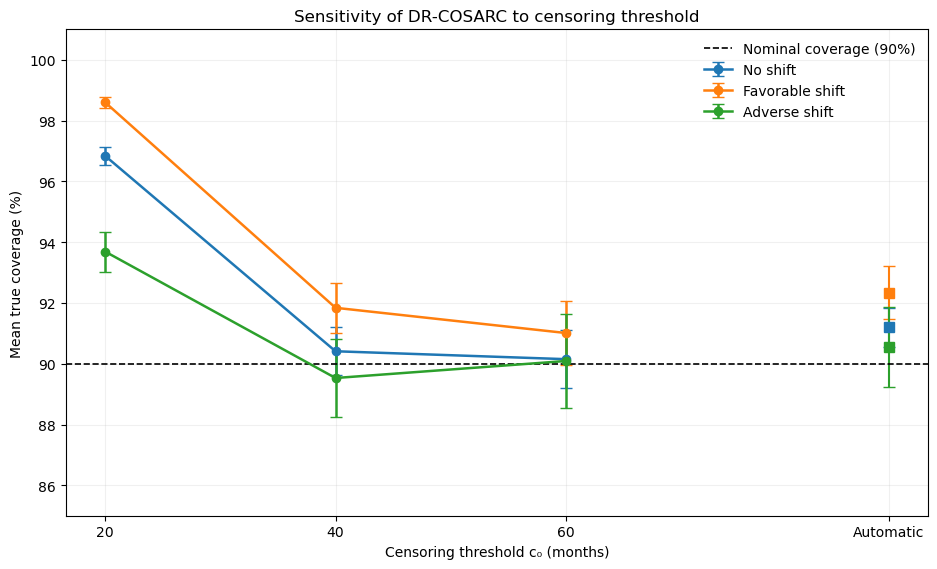

In [81]:

# STEP 73 - CELL 2
# FIGURE 1: CENSORING THRESHOLD SENSITIVITY
# VISUALIZATION ONLY - NO SAVING

threshold_order = ["20.0", "40.0", "60.0", "auto"]
threshold_positions = np.array([0, 1, 2, 3.4])

scenario_order = [
    "No shift",
    "Favorable shift",
    "Adverse shift"
]

fig_threshold, ax_threshold = plt.subplots(
    figsize=(9.5, 5.8)
)

for scenario in scenario_order:

    data = (
        bench_sens_summary
        .loc[bench_sens_summary["Scenario"] == scenario]
        .set_index("Threshold")
        .reindex(threshold_order)
    )

    assert data["Mean_coverage"].notna().all()

    y = data["Mean_coverage"].to_numpy()
    yerr = 1.96 * data["MC_SE"].to_numpy()

    # Fixed thresholds: connected
    plotted = ax_threshold.errorbar(
        threshold_positions[:3],
        y[:3],
        yerr=yerr[:3],
        fmt="o-",
        linewidth=1.8,
        markersize=6,
        capsize=4,
        label=scenario
    )

    # Automatic threshold: separate point
    ax_threshold.errorbar(
        threshold_positions[3],
        y[3],
        yerr=yerr[3],
        fmt="s",
        markersize=7,
        capsize=4,
        color=plotted.lines[0].get_color()
    )

ax_threshold.axhline(
    y=90,
    color="black",
    linestyle="--",
    linewidth=1.2,
    label="Nominal coverage (90%)"
)

ax_threshold.set_xticks(threshold_positions)
ax_threshold.set_xticklabels([
    "20", "40", "60", "Automatic"
])

ax_threshold.set_xlabel(
    "Censoring threshold c₀ (months)"
)

ax_threshold.set_ylabel(
    "Mean true coverage (%)"
)

ax_threshold.set_title(
    "Sensitivity of DR-COSARC to censoring threshold"
)

ax_threshold.set_ylim(85, 101)
ax_threshold.grid(alpha=0.18)

ax_threshold.legend(
    frameon=False,
    loc="upper right"
)

fig_threshold.tight_layout()

plt.show()


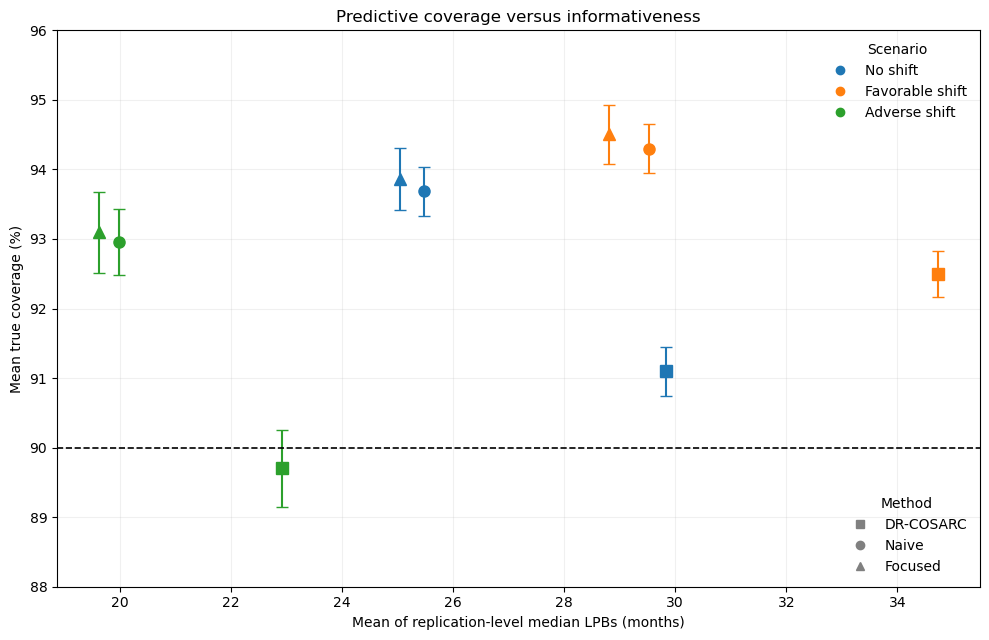

In [82]:

# STEP 73 - CELL 3
# FIGURE 2: COVERAGE VS INFORMATIVENESS
# VISUALIZATION ONLY - NO SAVING

scenario_order = [
    "No shift",
    "Favorable shift",
    "Adverse shift"
]

method_order = [
    "DR-COSARC",
    "Naive",
    "Focused"
]

method_markers = {
    "DR-COSARC": "s",
    "Naive": "o",
    "Focused": "^"
}

default_colors = plt.rcParams[
    "axes.prop_cycle"
].by_key()["color"]

scenario_colors = dict(
    zip(scenario_order, default_colors)
)

fig_tradeoff, ax_tradeoff = plt.subplots(
    figsize=(10, 6.5)
)

for scenario in scenario_order:

    for method in method_order:

        row = bench_mc_summary.loc[
            (bench_mc_summary["Scenario"] == scenario)
            & (bench_mc_summary["Method"] == method)
        ].iloc[0]

        ax_tradeoff.errorbar(
            row["Mean_LPB"],
            row["Mean_coverage"],
            yerr=1.96 * row["MC_SE"],
            fmt=method_markers[method],
            color=scenario_colors[scenario],
            markersize=8,
            capsize=4,
            linewidth=1.5
        )

# Nominal coverage reference
ax_tradeoff.axhline(
    90,
    color="black",
    linestyle="--",
    linewidth=1.2
)

# Scenario legend
scenario_handles = []

for scenario in scenario_order:

    handle, = ax_tradeoff.plot(
        [],
        [],
        marker="o",
        linestyle="None",
        color=scenario_colors[scenario],
        label=scenario
    )

    scenario_handles.append(handle)

legend_scenarios = ax_tradeoff.legend(
    handles=scenario_handles,
    title="Scenario",
    loc="upper right",
    frameon=False
)

ax_tradeoff.add_artist(legend_scenarios)

# Method legend
method_handles = []

for method in method_order:

    handle, = ax_tradeoff.plot(
        [],
        [],
        marker=method_markers[method],
        linestyle="None",
        color="gray",
        label=method
    )

    method_handles.append(handle)

ax_tradeoff.legend(
    handles=method_handles,
    title="Method",
    loc="lower right",
    frameon=False
)

ax_tradeoff.set_xlabel(
    "Mean of replication-level median LPBs (months)"
)

ax_tradeoff.set_ylabel(
    "Mean true coverage (%)"
)

ax_tradeoff.set_title(
    "Predictive coverage versus informativeness"
)

ax_tradeoff.set_ylim(88, 96)
ax_tradeoff.grid(alpha=0.18)

fig_tradeoff.tight_layout()

plt.show()


In [84]:

# STEP 73 - CELL 4
# FIGURE ARCHIVING ONLY
# Run ONLY after visual and scientific approval

SAVE_FIGURES = False

figures_to_save = {
    "DRAFT_Figure_threshold_coverage": fig_threshold,
    "DRAFT_Figure_coverage_vs_LPB": fig_tradeoff
}

if SAVE_FIGURES:

    figure_dir = Path("../figures/draft_benchmark")
    figure_dir.mkdir(parents=True, exist_ok=True)

    for name, figure in figures_to_save.items():

        png_path = figure_dir / f"{name}.png"
        pdf_path = figure_dir / f"{name}.pdf"

        figure.savefig(
            png_path,
            dpi=350,
            bbox_inches="tight",
            facecolor="white"
        )

        figure.savefig(
            pdf_path,
            bbox_inches="tight",
            facecolor="white"
        )

        assert png_path.is_file()
        assert pdf_path.is_file()

        print("Saved:", png_path)
        print("Saved:", pdf_path)

    print("\nAll approved figures saved successfully.")

else:
    print("Figure saving is disabled.")
    print("Review and approve both figures first.")


Figure saving is disabled.
Review and approve both figures first.



## 74. Internal–External Validation and Subgroup Coverage

**Primary reference:** Davidov H et al. Conformalized Survival Analysis for General Right-Censored Data. ICLR 2025.

**Objective:** Visualize the transportability and subgroup performance of conformal survival lower predictive bounds.

**Study populations:**
- METABRIC internal test cohort: 397 patients.
- TCGA-BRCA external cohort: 1,084 patients.

**Model:** Fixed transportable Random Survival Forest using age and tumor histology.

**Methods:** Naive and Focused calibration, evaluated using IPCW-adjusted coverage.

**Outputs:**
1. Internal versus external coverage with 95% bootstrap confidence intervals.
2. External subgroup coverage by age and tumor histology.

**Statistical considerations:** The bootstrap intervals are exploratory and conditional on previously fitted prediction and calibration models. They do not capture uncertainty from the entire modeling process. Subgroup results are descriptive and should not be interpreted as evidence of conditional coverage guarantees.



In [85]:

# STEP 74 - CELL 2
# MAIN VALIDATION TABLE - DISPLAY ONLY

validation_rows = []

for _, row in audit_core_summary.iterrows():

    for cohort in ["Internal", "External"]:

        validation_rows.append({
            "Cohort": (
                "METABRIC Test"
                if cohort == "Internal"
                else "TCGA-BRCA"
            ),
            "Method": row["Method"],
            "Patients": int(row[f"{cohort} n"]),
            "IPCW coverage (%)": row[
                f"{cohort} coverage (%)"
            ],
            "95% CI": (
                f'{row[f"{cohort} CI lower"]:.2f}–'
                f'{row[f"{cohort} CI upper"]:.2f}'
            ),
            "Median LPB (months)": row[
                f"{cohort} median LPB"
            ]
        })

validation_table_74 = pd.DataFrame(validation_rows)

display(validation_table_74.round(2))

assert len(validation_table_74) == 4

print("Validation table prepared. Nothing saved.")


,Cohort,Method,Patients,IPCW coverage (%),95% CI,Median LPB (months)
0,METABRIC Test,Naive,397,88.29,84.80–91.37,30.97
1,TCGA-BRCA,Naive,1084,91.77,89.64–93.78,30.37
2,METABRIC Test,Focused,397,92.63,89.88–94.95,21.93
3,TCGA-BRCA,Focused,1084,95.31,93.79–96.75,21.93


Validation table prepared. Nothing saved.


In [90]:

# STEP 74 - CELL 3
# SAVE APPROVED TABLE ONLY

SAVE_TABLE_74 = False

if SAVE_TABLE_74:

    table_dir = Path("../results/draft_tables")
    table_dir.mkdir(parents=True, exist_ok=True)

    table_path = (
        table_dir / "DRAFT_08_internal_external_validation.csv"
    )

    validation_table_74.to_csv(
        table_path,
        index=False,
        encoding="utf-8-sig"
    )

    print("Saved:", table_path)

else:
    print("Table saving disabled.")


Table saving disabled.


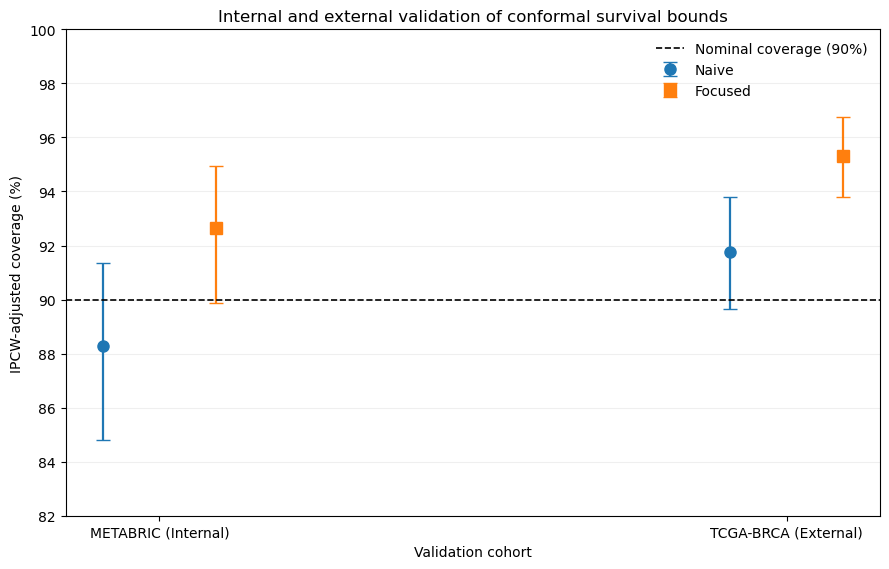

In [87]:

# STEP 74 - CELL 4
# FIGURE 3: INTERNAL VS EXTERNAL COVERAGE
# DISPLAY ONLY - NO SAVING

fig_validation, ax_validation = plt.subplots(
    figsize=(9, 5.8)
)

cohort_positions = np.array([0, 1])

method_offsets = {
    "Naive": -0.09,
    "Focused": 0.09
}

method_markers = {
    "Naive": "o",
    "Focused": "s"
}

for method in ["Naive", "Focused"]:

    row = audit_core_summary.loc[
        audit_core_summary["Method"] == method
    ].iloc[0]

    values = np.array([
        row["Internal coverage (%)"],
        row["External coverage (%)"]
    ])

    lower = np.array([
        row["Internal CI lower"],
        row["External CI lower"]
    ])

    upper = np.array([
        row["Internal CI upper"],
        row["External CI upper"]
    ])

    errors = np.vstack([
        values - lower,
        upper - values
    ])

    ax_validation.errorbar(
        cohort_positions + method_offsets[method],
        values,
        yerr=errors,
        fmt=method_markers[method],
        markersize=8,
        capsize=5,
        linewidth=1.6,
        label=method
    )

ax_validation.axhline(
    90,
    linestyle="--",
    color="black",
    linewidth=1.2,
    label="Nominal coverage (90%)"
)

ax_validation.set_xticks(cohort_positions)

ax_validation.set_xticklabels([
    "METABRIC (Internal)",
    "TCGA-BRCA (External)"
])

ax_validation.set_ylabel(
    "IPCW-adjusted coverage (%)"
)

ax_validation.set_xlabel("Validation cohort")

ax_validation.set_title(
    "Internal and external validation of conformal survival bounds"
)

ax_validation.set_ylim(82, 100)
ax_validation.grid(axis="y", alpha=0.2)

ax_validation.legend(frameon=False)

fig_validation.tight_layout()

plt.show()


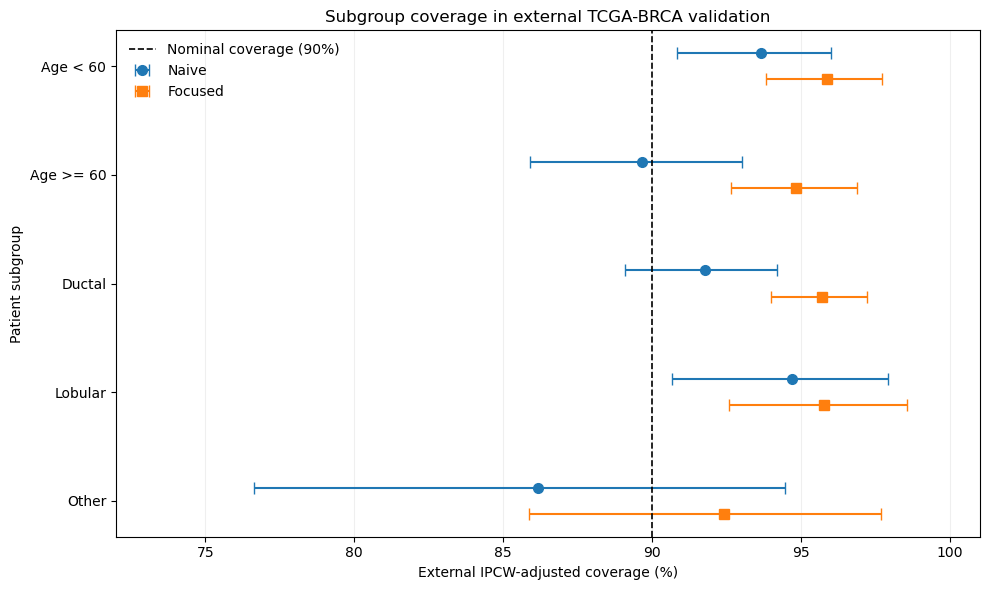

In [88]:

# STEP 74 - CELL 5
# FIGURE 4: EXTERNAL SUBGROUP COVERAGE
# DISPLAY ONLY - NO SAVING

subgroup_order = [
    "Age < 60",
    "Age >= 60",
    "Ductal",
    "Lobular",
    "Other"
]

fig_subgroups, ax_subgroups = plt.subplots(
    figsize=(10, 6)
)

positions = np.arange(len(subgroup_order))

for method, offset, marker in [
    ("Naive", -0.12, "o"),
    ("Focused", 0.12, "s")
]:

    data = (
        subgroup_ci.loc[
            subgroup_ci["Method"] == method
        ]
        .set_index("Subgroup")
        .reindex(subgroup_order)
    )

    assert data["Coverage (%)"].notna().all()

    coverage = data["Coverage (%)"].to_numpy()

    ci_lower = data["95% CI lower"].to_numpy()
    ci_upper = data["95% CI upper"].to_numpy()

    errors = np.vstack([
        coverage - ci_lower,
        ci_upper - coverage
    ])

    ax_subgroups.errorbar(
        coverage,
        positions + offset,
        xerr=errors,
        fmt=marker,
        markersize=7,
        linewidth=1.5,
        capsize=4,
        label=method
    )

ax_subgroups.axvline(
    90,
    linestyle="--",
    color="black",
    linewidth=1.2,
    label="Nominal coverage (90%)"
)

ax_subgroups.set_yticks(positions)
ax_subgroups.set_yticklabels(subgroup_order)
ax_subgroups.invert_yaxis()

ax_subgroups.set_xlabel(
    "External IPCW-adjusted coverage (%)"
)

ax_subgroups.set_ylabel("Patient subgroup")

ax_subgroups.set_title(
    "Subgroup coverage in external TCGA-BRCA validation"
)

ax_subgroups.set_xlim(72, 101)
ax_subgroups.grid(axis="x", alpha=0.2)
ax_subgroups.legend(frameon=False)

fig_subgroups.tight_layout()

plt.show()


In [92]:

# STEP 74 - CELL 6
# SAVE APPROVED FIGURES ONLY

SAVE_FIGURES_74 = False

figures_74 = {
    "DRAFT_Figure_internal_external_coverage": fig_validation,
    "DRAFT_Figure_external_subgroup_coverage": fig_subgroups
}

if SAVE_FIGURES_74:

    figure_dir = Path("../figures/draft_real")
    figure_dir.mkdir(parents=True, exist_ok=True)

    for name, figure in figures_74.items():

        for extension in ["png", "pdf"]:

            file_path = figure_dir / f"{name}.{extension}"

            save_options = {
                "bbox_inches": "tight",
                "facecolor": "white"
            }

            if extension == "png":
                save_options["dpi"] = 350

            figure.savefig(file_path, **save_options)

            print("Saved:", file_path)

else:
    print("Figure saving disabled.")
    print("Review both figures before archiving.")


Figure saving disabled.
Review both figures before archiving.



## 75. Baseline Characteristics of the Study Cohorts

**Objective:** Describe the demographic, histological, and observed survival characteristics of the METABRIC development/calibration/test cohorts and the independent TCGA-BRCA cohort.

**Variables:** Age at diagnosis, histological subtype, observed death status, censoring frequency, observed overall survival time, and missingness.

**Methods:** Continuous variables are summarized using median and interquartile range (IQR). Categorical variables are summarized as counts and percentages.

**Harmonization:** Tumor histology is grouped using the OncoTree categories IDC (Ductal), ILC (Lobular), and all other recorded nonmissing categories (Other).

**Statistical considerations:** Descriptive statistics are not used for model fitting or hyperparameter selection. Observed survival times are not interpreted as uncensored survival times, and no significance tests are used for baseline comparisons.

**Implementation:** Existing METABRIC splits are preserved, and TCGA-BRCA is used only for descriptive external cohort characterization.


In [93]:

# STEP 75 - CELL 2
# TABLE 1: BASELINE CHARACTERISTICS
# DISPLAY ONLY - NO SAVING

table1_tcga_path = Path(
    "../data/raw/brca_tcga_pan_can_atlas_2018_clinical_data.tsv"
)

assert table1_tcga_path.is_file(), (
    f"TCGA file not found: {table1_tcga_path}"
)

table1_tcga = pd.read_csv(
    table1_tcga_path,
    sep="\t",
    low_memory=False
)


def table1_median_iqr(values):
    values = pd.to_numeric(values, errors="coerce").dropna()

    if len(values) == 0:
        return "NA"

    return (
        f"{values.median():.2f} "
        f"[{values.quantile(0.25):.2f}–"
        f"{values.quantile(0.75):.2f}]"
    )


def table1_n_pct(mask):
    n = int(mask.sum())
    return f"{n} ({100 * n / len(mask):.1f}%)"


def table1_summarize(name, df, age_col, event_values):

    required = {
        age_col,
        "Oncotree Code",
        "Overall Survival (Months)"
    }

    missing = required - set(df.columns)
    assert not missing, f"{name}: missing columns {missing}"

    age = pd.to_numeric(df[age_col], errors="coerce")

    observed_time = pd.to_numeric(
        df["Overall Survival (Months)"],
        errors="coerce"
    )

    events = pd.Series(
        np.asarray(event_values),
        index=df.index
    )

    assert len(events) == len(df)
    assert events.notna().all()
    assert events.isin([0, 1]).all()
    assert observed_time.notna().all()
    assert (observed_time >= 0).all()

    oncotree = (
        df["Oncotree Code"]
        .astype("string")
        .str.strip()
        .str.upper()
    )

    assert oncotree.notna().all(), (
        f"{name}: missing OncoTree values; "
        "review harmonization before continuing."
    )

    histology = pd.Series(
        np.select(
            [
                oncotree.eq("IDC").to_numpy(),
                oncotree.eq("ILC").to_numpy()
            ],
            ["Ductal", "Lobular"],
            default="Other"
        ),
        index=df.index
    )

    return {
        "Cohort": name,
        "Patients": len(df),
        "Deaths, n (%)": table1_n_pct(events == 1),
        "Censored, n (%)": table1_n_pct(events == 0),
        "Age, median [IQR]": table1_median_iqr(age),
        "Ductal, n (%)": table1_n_pct(histology == "Ductal"),
        "Lobular, n (%)": table1_n_pct(histology == "Lobular"),
        "Other, n (%)": table1_n_pct(histology == "Other"),
        "Observed OS, median [IQR]": table1_median_iqr(
            observed_time
        ),
        "Missing age, n": int(age.isna().sum()),
        "Zero OS times, n": int((observed_time == 0).sum())
    }


# Verify TCGA outcome coding
table1_status = (
    table1_tcga["Overall Survival Status"]
    .astype("string")
    .str.strip()
    .str.upper()
)

assert table1_status.isin([
    "0:LIVING", "1:DECEASED"
]).all(), "Unexpected TCGA status coding."

table1_tcga_event = (
    table1_status == "1:DECEASED"
).astype(int)


# Create descriptive table
table1_rows = []

for name, df in [
    ("METABRIC Training", train_df),
    ("METABRIC Calibration", cal_df),
    ("METABRIC Test", test_df)
]:
    table1_rows.append(
        table1_summarize(
            name,
            df,
            "Age at Diagnosis",
            df["event"]
        )
    )

table1_rows.append(
    table1_summarize(
        "TCGA-BRCA External",
        table1_tcga,
        "Diagnosis Age",
        table1_tcga_event
    )
)

baseline_table_75 = pd.DataFrame(table1_rows)

# Integrity checks
assert len(baseline_table_75) == 4

assert (
    len(train_df) + len(cal_df) + len(test_df)
    == len(os_df)
)

assert (
    int(table1_tcga_event.sum()) == 151
), "TCGA event count differs from previous validation."

display(baseline_table_75)

print("\nMETABRIC total:", len(os_df))
print("TCGA external:", len(table1_tcga))
print("Baseline table prepared. Nothing saved.")


,Cohort,Patients,"Deaths, n (%)","Censored, n (%)","Age, median [IQR]","Ductal, n (%)","Lobular, n (%)","Other, n (%)","Observed OS, median [IQR]","Missing age, n","Zero OS times, n"
0,METABRIC Training,1188,686 (57.7%),502 (42.3%),62.44 [51.61–70.76],923 (77.7%),86 (7.2%),179 (15.1%),120.05 [62.84–187.43],0,0
1,METABRIC Calibration,396,225 (56.8%),171 (43.2%),61.66 [50.41–69.99],304 (76.8%),35 (8.8%),57 (14.4%),111.73 [55.91–181.13],0,1
2,METABRIC Test,397,233 (58.7%),164 (41.3%),60.89 [51.42–70.58],311 (78.3%),25 (6.3%),61 (15.4%),111.37 [55.20–168.53],0,0
3,TCGA-BRCA External,1084,151 (13.9%),933 (86.1%),58.00 [49.00–67.00],780 (72.0%),201 (18.5%),103 (9.5%),27.01 [14.72–55.00],0,13



METABRIC total: 1981
TCGA external: 1084
Baseline table prepared. Nothing saved.


In [95]:

# STEP 75 - TABLE 1 ARCHIVING ONLY

SAVE_TABLE_75 = False

if SAVE_TABLE_75:

    table_dir = Path("../results/draft_tables")
    table_dir.mkdir(parents=True, exist_ok=True)

    table_path = (
        table_dir / "DRAFT_09_baseline_characteristics.csv"
    )

    baseline_table_75.to_csv(
        table_path,
        index=False,
        encoding="utf-8-sig"
    )

    assert table_path.is_file()

    print("Saved:", table_path)
    print("Baseline characteristics table archived.")

else:
    print("Table saving disabled.")


Table saving disabled.



## 76. Study Population and Data-Splitting Flow Diagram

**Objective:** Illustrate the development, calibration, internal testing, and external validation cohorts.

**Data sources:** METABRIC and TCGA-BRCA (PanCancer Atlas).

**Design:**
- METABRIC analytical population: 1,981 patients.
- Training set: 1,188 patients.
- Calibration set: 396 patients.
- Internal test set: 397 patients.
- TCGA-BRCA external cohort: 1,084 patients.

**Methodological considerations:** Patient-level non-overlap was verified across METABRIC splits. External TCGA patients were not used to fit the source survival forest or to calibrate the unweighted source conformal bounds.

**Limitation:** The diagram begins with the available analytical cohorts and does not represent the full eligibility and exclusion process from the original source populations.

**Implementation:** Visualization only; no fitting, recalibration, or saving.


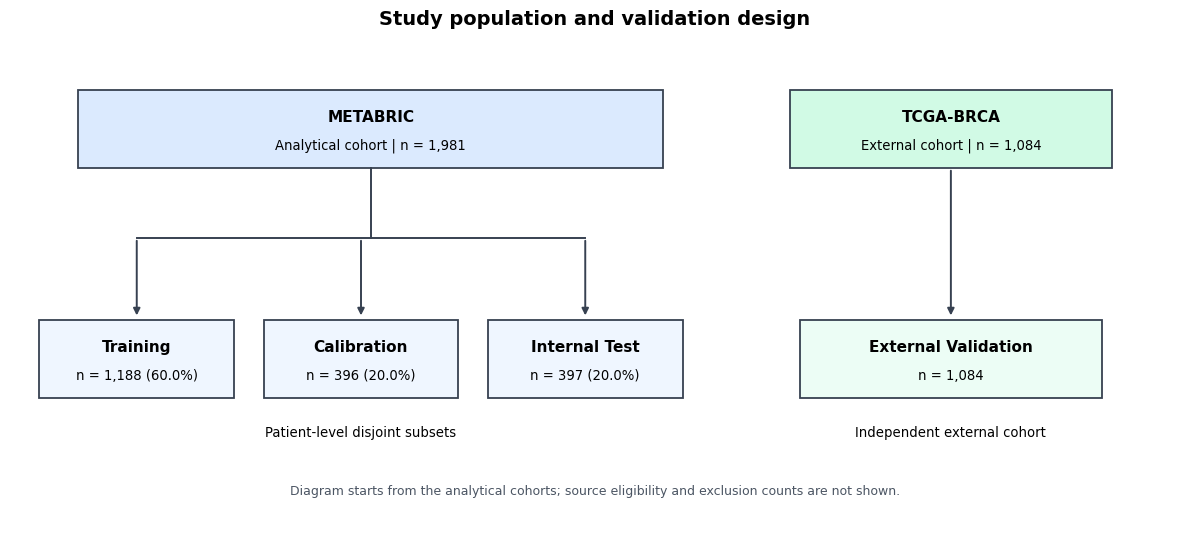

In [96]:

# STEP 76 - COHORT FLOW DIAGRAM
# VISUALIZATION ONLY - NO SAVING

fig_flow_76, ax = plt.subplots(figsize=(12, 5.5))

ax.set_xlim(0, 12)
ax.set_ylim(0, 6.2)
ax.axis("off")


def draw_flow_box(x, y, w, h, title, details, facecolor):

    rect = plt.Rectangle(
        (x, y), w, h,
        facecolor=facecolor,
        edgecolor="#374151",
        linewidth=1.3
    )

    ax.add_patch(rect)

    ax.text(
        x + w / 2,
        y + h * 0.65,
        title,
        ha="center",
        va="center",
        fontsize=11,
        fontweight="bold"
    )

    ax.text(
        x + w / 2,
        y + h * 0.28,
        details,
        ha="center",
        va="center",
        fontsize=9.5
    )


# METABRIC source cohort
draw_flow_box(
    0.7, 4.65, 6.0, 1.0,
    "METABRIC",
    "Analytical cohort | n = 1,981",
    "#DBEAFE"
)

# TCGA external cohort
draw_flow_box(
    8.0, 4.65, 3.3, 1.0,
    "TCGA-BRCA",
    "External cohort | n = 1,084",
    "#D1FAE5"
)

# METABRIC subsets
draw_flow_box(
    0.3, 1.7, 2.0, 1.0,
    "Training",
    "n = 1,188 (60.0%)",
    "#EFF6FF"
)

draw_flow_box(
    2.6, 1.7, 2.0, 1.0,
    "Calibration",
    "n = 396 (20.0%)",
    "#EFF6FF"
)

draw_flow_box(
    4.9, 1.7, 2.0, 1.0,
    "Internal Test",
    "n = 397 (20.0%)",
    "#EFF6FF"
)

draw_flow_box(
    8.1, 1.7, 3.1, 1.0,
    "External Validation",
    "n = 1,084",
    "#ECFDF5"
)

# Source split connectors
ax.plot(
    [3.7, 3.7],
    [4.65, 3.75],
    color="#374151",
    linewidth=1.4
)

ax.plot(
    [1.3, 5.9],
    [3.75, 3.75],
    color="#374151",
    linewidth=1.4
)

for x in [1.3, 3.6, 5.9]:

    ax.annotate(
        "",
        xy=(x, 2.72),
        xytext=(x, 3.75),
        arrowprops=dict(
            arrowstyle="-|>",
            color="#374151",
            lw=1.4
        )
    )

# External validation connector
ax.annotate(
    "",
    xy=(9.65, 2.72),
    xytext=(9.65, 4.65),
    arrowprops=dict(
        arrowstyle="-|>",
        color="#374151",
        lw=1.4
    )
)

# Descriptive labels
ax.text(
    3.6, 1.20,
    "Patient-level disjoint subsets",
    ha="center",
    fontsize=9.5
)

ax.text(
    9.65, 1.20,
    "Independent external cohort",
    ha="center",
    fontsize=9.5
)

ax.text(
    6.0, 0.45,
    "Diagram starts from the analytical cohorts; "
    "source eligibility and exclusion counts are not shown.",
    ha="center",
    fontsize=9,
    color="#4B5563"
)

ax.set_title(
    "Study population and validation design",
    fontsize=14,
    fontweight="bold",
    pad=16
)

fig_flow_76.tight_layout()

plt.show()


In [98]:

# STEP 76 - CELL 3
# SAVE APPROVED STUDY FLOW DIAGRAM
# ARCHIVING ONLY - NO NEW VISUALIZATION

SAVE_FLOW_76 = False

if SAVE_FLOW_76:

    flow_dir = Path("../figures/draft_real")
    flow_dir.mkdir(parents=True, exist_ok=True)

    figures_to_save = {
        "DRAFT_Figure_study_population_flow": fig_flow_76
    }

    for name, figure in figures_to_save.items():

        png_path = flow_dir / f"{name}.png"
        pdf_path = flow_dir / f"{name}.pdf"

        figure.savefig(
            png_path,
            dpi=350,
            bbox_inches="tight",
            facecolor="white"
        )

        figure.savefig(
            pdf_path,
            bbox_inches="tight",
            facecolor="white"
        )

        assert png_path.is_file()
        assert pdf_path.is_file()

        print("Saved:", png_path)
        print("Saved:", pdf_path)

    print("\nStudy flow diagram archived successfully.")

else:
    print("Figure saving is disabled.")


Figure saving is disabled.



## 77. Final Statistical and Data Integrity Audit

### Objective
To assess the statistical integrity, reproducibility, and methodological validity of the METABRIC–TCGA conformal survival prediction framework before final manuscript preparation.

### Methodological references
1. Davidov H et al. (2025). Conformalized Survival Analysis for General Right-Censored Data. ICLR.
2. Sesia M, Svetnik V. (2025). Doubly Robust Conformalized Survival Analysis with Right-Censored Data. ICML.
3. Collins GS et al. (2024). TRIPOD+AI reporting guidelines.

### Audit domains
- Patient-level independence across data splits
- Survival outcome consistency and zero-time observations
- Predictor eligibility and potential data leakage
- Compatibility of the source and target cohorts
- Conformal calibration and censoring assumptions
- Limitations of covariate-shift weighting
- Reproducibility of benchmark evaluations

### Interpretation
Passing computational integrity checks does not establish theoretical validity. Conditional independent censoring, endpoint compatibility, and equivalence to published reference implementations require separate methodological verification.

### Implementation
This step is diagnostic only. No models are refitted, no calibration thresholds are modified, and no results are saved.



In [99]:

# STEP 77 - CELL 2
# AUDIT A: SURVIVAL DATA INTEGRITY
# DISPLAY ONLY - NO SAVING

audit_cohorts = [
    ("METABRIC Training", train_df,
     time_col, train_df["event"]),

    ("METABRIC Calibration", cal_df,
     time_col, cal_df["event"]),

    ("METABRIC Test", test_df,
     time_col, test_df["event"]),

    ("TCGA-BRCA External", table1_tcga,
     "Overall Survival (Months)", table1_tcga_event)
]

audit_data_rows = []

for name, df, t_col, event_values in audit_cohorts:

    times = pd.to_numeric(df[t_col], errors="coerce")
    events = pd.to_numeric(
        pd.Series(event_values, index=df.index),
        errors="coerce"
    )

    valid_events = events.isin([0, 1])
    valid_times = times.notna() & np.isfinite(times)

    valid_outcome = valid_events & valid_times & (times >= 0)

    zero_deaths = int(((times == 0) & (events == 1)).sum())
    zero_censored = int(((times == 0) & (events == 0)).sum())

    duplicate_ids = (
        int(df["Patient ID"].duplicated().sum())
        if "Patient ID" in df.columns else np.nan
    )

    audit_data_rows.append({
        "Cohort": name,
        "Patients": len(df),
        "Deaths": int((events == 1).sum()),
        "Censored": int((events == 0).sum()),
        "Missing time": int(times.isna().sum()),
        "Invalid outcomes": int((~valid_outcome).sum()),
        "Negative times": int((times < 0).sum()),
        "Zero-time deaths": zero_deaths,
        "Zero-time censored": zero_censored,
        "Duplicate patient IDs": duplicate_ids,
        "Max follow-up": times.max()
    })

audit_data_77 = pd.DataFrame(audit_data_rows)

display(audit_data_77.round(2))

# Check patient-level separation
train_ids_77 = set(train_df["Patient ID"].dropna())
cal_ids_77 = set(cal_df["Patient ID"].dropna())
test_ids_77 = set(test_df["Patient ID"].dropna())

overlap_check_77 = {
    "Train-Cal": len(train_ids_77 & cal_ids_77),
    "Train-Test": len(train_ids_77 & test_ids_77),
    "Cal-Test": len(cal_ids_77 & test_ids_77)
}

print("\nPatient-level overlaps:")
for pair, count in overlap_check_77.items():
    print(f"{pair}: {count}")

assert all(v == 0 for v in overlap_check_77.values())

assert len(train_df) + len(cal_df) + len(test_df) == len(os_df)

assert (audit_data_77["Invalid outcomes"] == 0).all()
assert (audit_data_77["Missing time"] == 0).all()

print("\nSurvival data integrity checks passed.")
print("Zero-time observations require documented handling.")


,Cohort,Patients,Deaths,Censored,Missing time,Invalid outcomes,Negative times,Zero-time deaths,Zero-time censored,Duplicate patient IDs,Max follow-up
0,METABRIC Training,1188,686,502,0,0,0,0,0,0,355.20
1,METABRIC Calibration,396,225,171,0,0,0,0,1,0,307.93
2,METABRIC Test,397,233,164,0,0,0,0,0,0,337.03
3,TCGA-BRCA External,1084,151,933,0,0,0,0,13,0,282.90



Patient-level overlaps:
Train-Cal: 0
Train-Test: 0
Cal-Test: 0

Survival data integrity checks passed.
Zero-time observations require documented handling.


In [100]:

# STEP 77 - CELL 3
# AUDIT B: FEATURE ELIGIBILITY AND LEAKAGE
# DISPLAY ONLY - NO SAVING

audit_forbidden = set(excluded_cols) | {
    "event",
    time_col,
    "Overall Survival (Months)",
    "Overall Survival Status",
    "Relapse Free Status",
    "Relapse Free Status (Months)",
    "Patient's Vital Status"
}

audit_feature_sets = {
    "Clinical": clinical_features,
    "Extended": extended_features
}

feature_audit_rows = []

for model_name, features in audit_feature_sets.items():

    missing_columns = [
        col for col in features
        if col not in train_df.columns
    ]

    forbidden_used = sorted(
        set(features) & audit_forbidden
    )

    duplicates = len(features) - len(set(features))

    constants = [
        col for col in features
        if col in train_df.columns
        and train_df[col].nunique(dropna=True) <= 1
    ]

    feature_audit_rows.append({
        "Model": model_name,
        "Original predictors": len(features),
        "Missing columns": len(missing_columns),
        "Forbidden predictors": len(forbidden_used),
        "Duplicate predictors": duplicates,
        "Constant predictors": len(constants),
        "Status": (
            "PASS"
            if not missing_columns
            and not forbidden_used
            and duplicates == 0
            and not constants
            else "REVIEW"
        )
    })

audit_features_77 = pd.DataFrame(feature_audit_rows)

display(audit_features_77)

# Verify the transportable model's feature definition
print("\nTransportable model predictors:")
print(list(transport_core_features))

print("\nForbidden variables in clinical/extended sets:")
for model_name, features in audit_feature_sets.items():
    found = sorted(set(features) & audit_forbidden)
    print(model_name, ":", found if found else "None")

# Check nested feature sets
assert set(clinical_features).issubset(set(extended_features))

# Ensure no prohibited features are present
assert all(
    len(set(features) & audit_forbidden) == 0
    for features in audit_feature_sets.values()
)

print("\nFeature leakage screening passed.")
print("Feature timing and derived-variable provenance")
print("still require methodological review.")


,Model,Original predictors,Missing columns,Forbidden predictors,Duplicate predictors,Constant predictors,Status
0,Clinical,11,0,0,0,0,PASS
1,Extended,22,0,0,0,0,PASS



Transportable model predictors:
['Age', 'Histology']

Forbidden variables in clinical/extended sets:
Clinical : None
Extended : None

Feature leakage screening passed.
Feature timing and derived-variable provenance
still require methodological review.



### 77.C. Censoring Distribution and IPCW Positivity Audit

**Objective:** Examine censoring distributions and the positivity of inverse-probability-of-censoring weights across the METABRIC and TCGA-BRCA cohorts.

**Method:** The marginal censoring survival function G(t) was estimated using the reverse-event Kaplan–Meier estimator, treating censoring as the event of interest.

**Diagnostics:** Censoring survival probabilities at 12, 36, 60, and 120 months; minimum censoring survival probability at observed deaths; maximum inverse censoring weight; and effective sample size.

**Important distinction:** The KM estimates computed here are descriptive, within-cohort diagnostics. They do not replace the cross-fitted or conditional censoring models used in earlier coverage evaluations.

**Statistical limitations:** Positive estimated censoring probabilities do not establish conditional independent censoring, absence of unmeasured confounding, or valid marginal predictive coverage.




In [101]:

# STEP 77 - CELL 5
# AUDIT C: CENSORING AND IPCW POSITIVITY
# DIAGNOSTIC ONLY - NO SAVING

audit_censoring_rows = []

audit_censoring_cohorts = [
    ("METABRIC Training", train_df,
     time_col, train_df["event"]),

    ("METABRIC Calibration", cal_df,
     time_col, cal_df["event"]),

    ("METABRIC Test", test_df,
     time_col, test_df["event"]),

    ("TCGA-BRCA External", table1_tcga,
     "Overall Survival (Months)", table1_tcga_event)
]

for name, df, duration_col, event_values in audit_censoring_cohorts:

    times = pd.to_numeric(
        df[duration_col], errors="coerce"
    ).to_numpy(dtype=float)

    events = np.asarray(event_values, dtype=int)

    assert len(times) == len(events)
    assert np.isfinite(times).all()
    assert (times >= 0).all()
    assert np.isin(events, [0, 1]).all()

    # Reverse-event KM: censoring is the event
    km_censor = KaplanMeierFitter()

    km_censor.fit(
        durations=times,
        event_observed=(events == 0)
    )

    # Censoring survival at fixed time horizons
    horizons = [12.0, 36.0, 60.0, 120.0]

    g_horizons = np.asarray(
        km_censor.predict(horizons),
        dtype=float
    )

    # Evaluate G(t-) at observed death times
    death_times = times[events == 1]

    assert len(death_times) > 0

    death_times_left = np.nextafter(
        death_times, -np.inf
    )

    g_deaths = np.asarray(
        km_censor.predict(death_times_left),
        dtype=float
    )

    positive_g = np.all(g_deaths > 0)

    if positive_g:
        weights = 1.0 / g_deaths

        max_weight = float(np.max(weights))

        effective_n = (
            weights.sum() ** 2
            / np.sum(weights ** 2)
        )
    else:
        max_weight = np.nan
        effective_n = np.nan

    audit_censoring_rows.append({
        "Cohort": name,
        "Patients": len(df),
        "Deaths": int((events == 1).sum()),
        "Censored (%)": 100 * np.mean(events == 0),
        "G(12)": g_horizons[0],
        "G(36)": g_horizons[1],
        "G(60)": g_horizons[2],
        "G(120)": g_horizons[3],
        "Minimum G at deaths": g_deaths.min(),
        "G < 0.10 at deaths": int(
            np.sum(g_deaths < 0.10)
        ),
        "Maximum IPCW weight": max_weight,
        "Death-weight ESS": effective_n,
        "Positive G at deaths": positive_g
    })


audit_censoring_77 = pd.DataFrame(
    audit_censoring_rows
)

print("Censoring distribution diagnostics:")
display(audit_censoring_77.round(4))

print("\nPositivity assessment:")

for _, row in audit_censoring_77.iterrows():

    print(
        f"{row['Cohort']}: "
        f"minimum G = {row['Minimum G at deaths']:.4f}, "
        f"max weight = {row['Maximum IPCW weight']:.2f}"
    )

if audit_censoring_77["Positive G at deaths"].all():
    print("\nPASS: All marginal G(t-) estimates at deaths are positive.")
else:
    print("\nWARNING: Non-positive censoring probabilities detected.")

print("\nDescriptive censoring audit completed.")
print("No models were refitted. Nothing saved.")


Censoring distribution diagnostics:


,Cohort,Patients,Deaths,Censored (%),G(12),G(36),G(60),G(120),Minimum G at deaths,G < 0.10 at deaths,Maximum IPCW weight,Death-weight ESS,Positive G at deaths
0,METABRIC Training,1188,686,42.2559,0.9924,0.9808,0.9653,0.8321,0.0240,11,41.6908,141.2092,True
1,METABRIC Calibration,396,225,43.1818,0.9899,0.9764,0.9610,0.7978,0.0512,4,19.5343,79.4531,True
2,METABRIC Test,397,233,41.3098,0.9924,0.9761,0.9633,0.7670,0.0672,1,14.8907,137.5473,True
3,TCGA-BRCA External,1084,151,86.0701,0.8524,0.4412,0.2812,0.0683,0.0164,19,61.0963,45.1712,True



Positivity assessment:
METABRIC Training: minimum G = 0.0240, max weight = 41.69
METABRIC Calibration: minimum G = 0.0512, max weight = 19.53
METABRIC Test: minimum G = 0.0672, max weight = 14.89
TCGA-BRCA External: minimum G = 0.0164, max weight = 61.10

PASS: All marginal G(t-) estimates at deaths are positive.

Descriptive censoring audit completed.
No models were refitted. Nothing saved.



### 77.D. Horizon-Specific IPCW Stability

**Objective:** Assess the numerical stability of marginal inverse-probability-of-censoring weights at prespecified follow-up horizons.

**Method:** Reverse-event Kaplan–Meier censoring estimates were evaluated immediately before observed death times. Analyses were restricted cumulatively to 36, 60, 120 months, and complete available follow-up.

**Diagnostics:** Number of observed deaths, minimum censoring survival probability, maximum IPCW weight, effective sample size, and concentration of the five largest weights.

**Interpretation:** These are descriptive stability diagnostics, not new predictive coverage estimates. Restricting the evaluation horizon does not itself establish valid IPCW coverage or conditional independent censoring.

**Reference:** Robins JM, Rotnitzky A. Recovery of Information and Adjustment for Dependent Censoring Using Surrogate Markers. AIDS Epidemiology, 1992.


In [102]:

# STEP 77 - CELL 7
# HORIZON-SPECIFIC IPCW STABILITY
# DIAGNOSTIC ONLY - NO SAVING

audit_d_rows = []

audit_horizons = [
    (36.0, "36 months"),
    (60.0, "60 months"),
    (120.0, "120 months"),
    (np.inf, "All follow-up")
]

for name, df, duration_col, event_values in audit_censoring_cohorts:

    times = pd.to_numeric(
        df[duration_col],
        errors="coerce"
    ).to_numpy(dtype=float)

    events = np.asarray(event_values, dtype=int)

    # Estimate marginal censoring survival
    km = KaplanMeierFitter()
    km.fit(
        durations=times,
        event_observed=(events == 0)
    )

    for horizon, horizon_label in audit_horizons:

        selected = (
            (events == 1)
            & (times <= horizon)
        )

        death_times = times[selected]
        n_deaths = len(death_times)

        if n_deaths == 0:
            continue

        # Left-limit G(t-) at observed death times
        g = np.asarray(
            km.predict(
                np.nextafter(death_times, -np.inf)
            ),
            dtype=float
        )

        assert np.isfinite(g).all()
        assert (g > 0).all()

        weights = 1.0 / g

        ess = (
            weights.sum() ** 2
            / np.sum(weights ** 2)
        )

        top_n = min(5, len(weights))

        top_weight_share = (
            100 * np.sort(weights)[-top_n:].sum()
            / weights.sum()
        )

        audit_d_rows.append({
            "Cohort": name,
            "Horizon": horizon_label,
            "Deaths": n_deaths,
            "Minimum G": g.min(),
            "Maximum weight": weights.max(),
            "IPCW ESS": ess,
            "ESS / deaths (%)": 100 * ess / n_deaths,
            "G < 0.10 (n)": int(np.sum(g < 0.10)),
            "Top 5 weight share (%)": top_weight_share
        })


audit_d_77 = pd.DataFrame(audit_d_rows)

display(audit_d_77.round(3))

assert (
    audit_d_77["IPCW ESS"]
    <= audit_d_77["Deaths"] + 1e-8
).all()

assert np.isfinite(
    audit_d_77.select_dtypes(include="number").to_numpy()
).all()

print("\nHorizon-specific IPCW audit completed.")
print("No models refitted. Nothing saved.")


,Cohort,Horizon,Deaths,Minimum G,Maximum weight,IPCW ESS,ESS / deaths (%),G < 0.10 (n),Top 5 weight share (%)
0,METABRIC Training,36 months,125,0.981,1.020,124.998,99.998,0,4.027
1,METABRIC Training,60 months,245,0.965,1.036,244.989,99.996,0,2.074
2,METABRIC Training,120 months,448,0.832,1.202,446.824,99.737,0,1.264
3,METABRIC Training,All follow-up,686,0.024,41.691,141.209,20.584,11,15.598
4,METABRIC Calibration,36 months,42,0.976,1.024,41.999,99.998,0,11.986
5,METABRIC Calibration,60 months,88,0.961,1.041,87.994,99.993,0,5.765
6,METABRIC Calibration,120 months,156,0.802,1.247,155.540,99.705,0,3.754
7,METABRIC Calibration,All follow-up,225,0.051,19.534,79.453,35.313,4,20.252
8,METABRIC Test,36 months,56,0.976,1.024,55.997,99.996,0,9.006
9,METABRIC Test,60 months,94,0.963,1.038,93.993,99.993,0,5.403



Horizon-specific IPCW audit completed.
No models refitted. Nothing saved.



### 77.E. Estimation of Median Follow-up Using Reverse Kaplan–Meier

**Reference:** Schemper M, Smith TL. A note on quantifying follow-up in studies of failure time. Controlled Clinical Trials. 1996;17(4):343–346. DOI: 10.1016/0197-2456(96)00075-x.

**Objective:** Estimate median potential follow-up duration separately for the METABRIC training, calibration, internal test, and TCGA-BRCA external cohorts.

**Method:** Reverse Kaplan–Meier estimation, with censoring treated as the event of interest and observed deaths treated as censored observations.

**Interpretation:** Reverse-KM median follow-up is distinct from the median observed overall survival time and the median event-free survival time.

**Implementation:** Existing cohorts and observed outcomes are reused. No survival prediction models are refitted or results saved.

**Reference:** https://pubmed.ncbi.nlm.nih.gov/8889347/


In [103]:

# STEP 77 - CELL 9
# REVERSE KAPLAN-MEIER FOLLOW-UP
# DISPLAY ONLY - NO SAVING

reverse_km_rows = []

for name, df, duration_col, event_values in audit_censoring_cohorts:

    times = pd.to_numeric(
        df[duration_col],
        errors="coerce"
    ).to_numpy(dtype=float)

    events = np.asarray(
        event_values,
        dtype=int
    )

    assert len(times) == len(events)
    assert np.isfinite(times).all()
    assert (times >= 0).all()
    assert np.isin(events, [0, 1]).all()

    # Reverse KM:
    # Original censoring becomes the event
    reverse_events = (events == 0)

    reverse_km = KaplanMeierFitter()

    reverse_km.fit(
        durations=times,
        event_observed=reverse_events
    )

    median_followup = float(
        reverse_km.median_survival_time_
    )

    reverse_km_rows.append({
        "Cohort": name,
        "Patients": len(df),
        "Deaths": int((events == 1).sum()),
        "Censored": int((events == 0).sum()),
        "Observed time median": np.median(times),
        "Reverse KM median follow-up": (
            median_followup
            if np.isfinite(median_followup)
            else np.nan
        ),
        "Median estimable": np.isfinite(median_followup)
    })


reverse_km_summary_77 = pd.DataFrame(
    reverse_km_rows
)

print("Median follow-up analysis:")
display(reverse_km_summary_77.round(2))


# Prepare an updated baseline table
# without modifying the original Table 1

baseline_table_75_updated = baseline_table_75.merge(
    reverse_km_summary_77[
        ["Cohort", "Reverse KM median follow-up"]
    ],
    on="Cohort",
    how="left",
    validate="one_to_one"
)

assert len(baseline_table_75_updated) == 4

print("\nUpdated baseline table preview:")
display(baseline_table_75_updated.round(2))

print("\nReverse-KM follow-up audit completed.")
print("Original baseline table unchanged.")
print("Nothing saved.")


Median follow-up analysis:


,Cohort,Patients,Deaths,Censored,Observed time median,Reverse KM median follow-up,Median estimable
0,METABRIC Training,1188,686,502,120.05,195.93,True
1,METABRIC Calibration,396,225,171,111.73,196.87,True
2,METABRIC Test,397,233,164,111.37,194.37,True
3,TCGA-BRCA External,1084,151,933,27.01,30.97,True



Updated baseline table preview:


,Cohort,Patients,"Deaths, n (%)","Censored, n (%)","Age, median [IQR]","Ductal, n (%)","Lobular, n (%)","Other, n (%)","Observed OS, median [IQR]","Missing age, n","Zero OS times, n",Reverse KM median follow-up
0,METABRIC Training,1188,686 (57.7%),502 (42.3%),62.44 [51.61–70.76],923 (77.7%),86 (7.2%),179 (15.1%),120.05 [62.84–187.43],0,0,195.93
1,METABRIC Calibration,396,225 (56.8%),171 (43.2%),61.66 [50.41–69.99],304 (76.8%),35 (8.8%),57 (14.4%),111.73 [55.91–181.13],0,1,196.87
2,METABRIC Test,397,233 (58.7%),164 (41.3%),60.89 [51.42–70.58],311 (78.3%),25 (6.3%),61 (15.4%),111.37 [55.20–168.53],0,0,194.37
3,TCGA-BRCA External,1084,151 (13.9%),933 (86.1%),58.00 [49.00–67.00],780 (72.0%),201 (18.5%),103 (9.5%),27.01 [14.72–55.00],0,13,30.97



Reverse-KM follow-up audit completed.
Original baseline table unchanged.
Nothing saved.



### 77.F. Survival Time Origin and Endpoint Compatibility Audit

**Objective:** Identify survival-related metadata and assess the comparability of the overall survival endpoints between METABRIC and TCGA-BRCA.

**Key questions:**
- Is overall survival measured from diagnosis, surgery, or sample collection?
- Are follow-up times reported in the same units?
- Are event indicators defined consistently?
- Are zero-time censored observations handled consistently?

**Method:** Inspect relevant clinical variables and dataset metadata without modifying patient records.

**Interpretation:** Column names and descriptive distributions alone cannot establish endpoint compatibility. Study-specific documentation is required to verify the time origin.




In [104]:

# STEP 77 - CELL 12
# SURVIVAL TIME ORIGIN AUDIT
# DISPLAY ONLY - NO SAVING

audit_origin_datasets = {
    "METABRIC": os_df,
    "TCGA-BRCA": table1_tcga
}

origin_keywords = [
    "diagnos",
    "survival",
    "follow",
    "date",
    "last",
    "time",
    "month",
    "surgery",
    "initial"
]

origin_audit_rows = []

for cohort_name, df in audit_origin_datasets.items():

    relevant_columns = [
        col for col in df.columns
        if any(
            keyword in col.lower()
            for keyword in origin_keywords
        )
    ]

    for col in relevant_columns:

        origin_audit_rows.append({
            "Cohort": cohort_name,
            "Variable": col,
            "Data type": str(df[col].dtype),
            "Available (n)": int(df[col].notna().sum()),
            "Missing (%)": round(
                100 * df[col].isna().mean(), 2
            )
        })

origin_audit_77 = pd.DataFrame(origin_audit_rows)

print("Survival-related variables:")
display(origin_audit_77)

print("\nImportant:")
print("This audit identifies candidate metadata only.")
print("Time-origin compatibility requires source documentation.")
print("Nothing saved.")


Survival-related variables:


,Cohort,Variable,Data type,Available (n),Missing (%)
0,METABRIC,Age at Diagnosis,float64,1981,0.00
1,METABRIC,Type of Breast Surgery,object,1955,1.31
2,METABRIC,Overall Survival (Months),float64,1981,0.00
3,METABRIC,Overall Survival Status,object,1981,0.00
4,METABRIC,Relapse Free Status (Months),float64,1981,0.00
5,TCGA-BRCA,Diagnosis Age,int64,1084,0.00
6,TCGA-BRCA,Last Communication Contact from Initial Pathol...,float64,980,9.59
7,TCGA-BRCA,Birth from Initial Pathologic Diagnosis Date,float64,1069,1.38
8,TCGA-BRCA,Last Alive Less Initial Pathologic Diagnosis D...,int64,1084,0.00
9,TCGA-BRCA,Disease Free (Months),float64,941,13.19



Important:
This audit identifies candidate metadata only.
Time-origin compatibility requires source documentation.
Nothing saved.



### 77.G. TCGA Overall Survival Endpoint Consistency

**Reference:** Liu J et al. (2018). An Integrated TCGA Pan-Cancer Clinical Data Resource to Drive High-Quality Survival Outcome Analytics. Cell.

**Objective:** Examine consistency between overall survival time and the recorded time since initial pathological diagnosis to last contact.

**Method:** Among living patients with available last-contact information, compare observed OS months against the diagnosis-to-last-contact interval converted from days to months.

**Interpretation:** Differences may arise from clinical data curation, additional follow-up records, or variations in source fields. This is a descriptive consistency audit, not a validation of exact time-origin equivalence.

**Implementation:** No patient records are modified, no models are refitted, and no results are saved.


In [105]:

# STEP 77 - CELL 14
# TCGA OVERALL SURVIVAL CONSISTENCY
# DIAGNOSTIC ONLY - NO SAVING

tcga_contact_columns = [
    col for col in table1_tcga.columns
    if "Last Communication Contact from Initial Pathol"
    in col
]

assert len(tcga_contact_columns) == 1, (
    f"Expected one last-contact column: {tcga_contact_columns}"
)

contact_col = tcga_contact_columns[0]

contact_days = pd.to_numeric(
    table1_tcga[contact_col],
    errors="coerce"
)

os_months = pd.to_numeric(
    table1_tcga["Overall Survival (Months)"],
    errors="coerce"
)

alive = table1_tcga_event.eq(0)

valid = (
    alive
    & contact_days.notna()
    & os_months.notna()
    & (contact_days >= 0)
    & (os_months >= 0)
)

# Convert days to months using the mean Gregorian month
contact_months = contact_days[valid] / (365.25 / 12)

absolute_difference = (
    os_months[valid] - contact_months
).abs()

tcga_origin_summary_77 = pd.DataFrame([{
    "Living patients": int(alive.sum()),
    "Comparable patients": int(valid.sum()),
    "Median OS (months)": os_months[valid].median(),
    "Median last-contact (months)": contact_months.median(),
    "Median absolute difference": absolute_difference.median(),
    "Within 1 month (%)": 100 * (
        absolute_difference <= 1
    ).mean(),
    "Within 3 months (%)": 100 * (
        absolute_difference <= 3
    ).mean(),
    "Difference > 12 months (n)": int(
        (absolute_difference > 12).sum()
    )
}])

print("TCGA endpoint consistency summary:")
display(tcga_origin_summary_77.round(3))

print("\nColumn examined:", contact_col)
print("No data modified. Nothing saved.")


TCGA endpoint consistency summary:


,Living patients,Comparable patients,Median OS (months),Median last-contact (months),Median absolute difference,Within 1 month (%),Within 3 months (%),Difference > 12 months (n)
0,933,931,24.953,24.936,0.017,98.496,98.496,10



Column examined: Last Communication Contact from Initial Pathologic Diagnosis Date
No data modified. Nothing saved.



### 77.H. Review of Discrepant TCGA Follow-up Records

**Reference:** Liu J et al. (2018). An Integrated TCGA Pan-Cancer Clinical Data Resource to Drive High-Quality Survival Outcome Analytics. Cell.

**Objective:** Identify living TCGA-BRCA patients with substantial disagreement between overall survival time and the recorded diagnosis-to-last-contact interval.

**Method:** Examine absolute differences exceeding three months and classify differences exceeding twelve months.

**Interpretation:** Discrepancies may reflect differences between clinical source fields and curated survival endpoints. Records will not be deleted or modified solely because these fields disagree.

**Implementation:** Diagnostic inspection only; no model fitting, patient exclusion, or file saving.

**Reference:** https://pmc.ncbi.nlm.nih.gov/articles/PMC6066282/


In [106]:

# STEP 77.H - TCGA FOLLOW-UP DISCREPANCIES
# DIAGNOSTIC ONLY - NO SAVING

origin_h_contact_col = (
    "Last Communication Contact from Initial Pathologic Diagnosis Date"
)

assert origin_h_contact_col in table1_tcga.columns

origin_h_contact_days = pd.to_numeric(
    table1_tcga[origin_h_contact_col],
    errors="coerce"
)

origin_h_os = pd.to_numeric(
    table1_tcga["Overall Survival (Months)"],
    errors="coerce"
)

origin_h_alive = table1_tcga_event.eq(0)

origin_h_valid = (
    origin_h_alive
    & origin_h_contact_days.notna()
    & origin_h_os.notna()
    & (origin_h_contact_days >= 0)
    & (origin_h_os >= 0)
)

origin_h_records = pd.DataFrame({
    "Row index": table1_tcga.index[origin_h_valid],
    "OS months": origin_h_os.loc[origin_h_valid].to_numpy(),
    "Last-contact months": (
        origin_h_contact_days.loc[origin_h_valid].to_numpy()
        / (365.25 / 12)
    )
})

origin_h_records["Signed difference"] = (
    origin_h_records["OS months"]
    - origin_h_records["Last-contact months"]
)

origin_h_records["Absolute difference"] = (
    origin_h_records["Signed difference"].abs()
)

origin_h_flagged = (
    origin_h_records.loc[
        origin_h_records["Absolute difference"] > 3
    ]
    .sort_values("Absolute difference", ascending=False)
)

print("Living patients:", int(origin_h_alive.sum()))
print("Comparable patients:", len(origin_h_records))

print(
    "Difference > 3 months:",
    len(origin_h_flagged)
)

print(
    "Difference > 12 months:",
    int(
        (origin_h_records["Absolute difference"] > 12).sum()
    )
)

print("\nRecords requiring documentation review:")
display(origin_h_flagged.round(3))

print("\nNo patients excluded or modified.")
print("Nothing saved.")


Living patients: 933
Comparable patients: 931
Difference > 3 months: 14
Difference > 12 months: 10

Records requiring documentation review:


,Row index,OS months,Last-contact months,Signed difference,Absolute difference
44,51,134.399,89.298,45.101,45.101
387,430,102.837,77.634,25.203,25.203
304,336,69.829,47.836,21.994,21.994
389,432,50.958,32.559,18.400,18.400
305,338,44.416,29.109,15.307,15.307
337,371,97.084,82.563,14.521,14.521
325,359,113.621,99.187,14.434,14.434
332,366,70.421,57.265,13.156,13.156
334,368,53.884,41.593,12.291,12.291
333,367,60.558,48.329,12.230,12.230



No patients excluded or modified.
Nothing saved.



### 77.I. Numerical Audit of Conformal Calibration

**Primary reference:** Davidov H, Feldman S, Shamai G, Kimmel R, Romano Y. Conformalized Survival Analysis for General Right-Censored Data. ICLR 2025.

**Objective:** Check the numerical implementation of Naive, Focused, and Fused calibration, and the finite-sample correction used by the exploratory weighted extensions.

**Audit components:**
- Correct handling of the event indicator in Focused Calibration.
- Correct handling of the selection mask and tau-dependent weights in Fused Calibration.
- Positivity and finiteness of calibration weights.
- Monotone-envelope calibration rule and admissible quantile selection.
- Independent numerical check of the weighted new-observation correction.

**Scope:** These checks assess computational consistency. They do not by themselves establish finite-sample coverage guarantees or equivalence to the published reference implementations.

**Implementation:** Existing pilot arrays and helper functions are reused without model refitting. No results are saved.



In [113]:

# STEP 77.I - CELL 18 (FINAL WEIGHT AUDIT)
# Verify Fused weights against the published formula
# NO FITTING - NO SAVING

audit18_s = np.asarray(sim_include, dtype=bool)
audit18_e = np.asarray(sim_events, dtype=bool)
audit18_w = np.asarray(sim_fused_weights, dtype=float)
audit18_focus_w = np.asarray(sim_event_weights, dtype=float)
audit18_errors = np.asarray(sim_errors, dtype=float)

n_tau, n_cal = audit18_errors.shape

assert audit18_s.shape == (n_cal, n_tau)
assert audit18_w.shape == (n_cal, n_tau)
assert audit18_e.shape == (n_cal,)
assert audit18_focus_w.shape == (n_cal,)

assert np.isfinite(audit18_w).all()
assert np.isfinite(audit18_focus_w).all()
assert (audit18_w >= 0).all()
assert (audit18_focus_w >= 0).all()

# ---------------------------------------------
# 1. Reconstruct the published Fused rule
# ---------------------------------------------

# s_tau: initial selection classifier
# zeta_tau: final inclusion rule
audit18_zeta = (
    audit18_s | audit18_e[:, None]
)

# Expected effective weights:
# s=1                  -> weight 1
# s=0 and event=1      -> weight 1/p(event|X)
# s=0 and censored     -> weight 0
audit18_expected_w = np.where(
    audit18_s,
    1.0,
    audit18_focus_w[:, None]
)

# ---------------------------------------------
# 2. Compare stored and expected weights
# ---------------------------------------------

audit18_abs_diff = np.abs(
    audit18_w - audit18_expected_w
)

audit18_max_diff = float(audit18_abs_diff.max())

audit18_weights_match = np.allclose(
    audit18_w,
    audit18_expected_w,
    rtol=1e-7,
    atol=1e-8
)

audit18_event_violations = int(
    (~audit18_zeta[audit18_e]).sum()
)

audit18_excluded_weight = int(
    np.sum(
        (audit18_w > 1e-10)
        & (~audit18_zeta)
    )
)

print("FUSED WEIGHT AUDIT")
print("----------------------------")
print("Calibration patients:", n_cal)
print("Observed events:", int(audit18_e.sum()))
print("Censored:", int((~audit18_e).sum()))
print("Event exclusions under zeta:", audit18_event_violations)
print("Positive weights outside zeta:", audit18_excluded_weight)
print("Maximum weight difference:", audit18_max_diff)
print("Weights match published structure:", audit18_weights_match)

# ---------------------------------------------
# 3. Compute calibration curves
# ---------------------------------------------

def audit18_select_level(curve):
    envelope = np.maximum.accumulate(curve)
    valid = np.flatnonzero(envelope <= alpha)

    if len(valid) == 0:
        return -1, np.nan, np.nan

    j = int(valid[-1])
    return j, float(tau_grid[j]), float(curve[j])


audit18_naive_curve = audit18_errors.mean(axis=1)

audit18_focused_curve = (
    audit18_errors @ audit18_focus_w
) / audit18_focus_w.sum()

audit18_stored_den = audit18_w.sum(axis=0)
audit18_expected_den = audit18_expected_w.sum(axis=0)

assert np.all(audit18_stored_den > 0)
assert np.all(audit18_expected_den > 0)

audit18_fused_stored = (
    (audit18_errors.T * audit18_w).sum(axis=0)
    / audit18_stored_den
)

audit18_fused_expected = (
    (audit18_errors.T * audit18_expected_w).sum(axis=0)
    / audit18_expected_den
)

audit18_curves_match = np.allclose(
    audit18_fused_stored,
    audit18_fused_expected,
    rtol=1e-7,
    atol=1e-8
)

# ---------------------------------------------
# 4. Compare calibration outcomes
# ---------------------------------------------

audit18_comparison = []

for method, curve in {
    "Naive": audit18_naive_curve,
    "Focused": audit18_focused_curve,
    "Fused stored": audit18_fused_stored,
    "Fused reconstructed": audit18_fused_expected
}.items():

    idx, selected_tau, error = audit18_select_level(curve)

    audit18_comparison.append({
        "Method": method,
        "Selected index": idx,
        "Selected tau": selected_tau,
        "Miscoverage": error
    })

audit18_final_table = pd.DataFrame(audit18_comparison)

print("\nCALIBRATION COMPARISON")
display(audit18_final_table.round(5))

# ---------------------------------------------
# 5. Final diagnostic decision
# ---------------------------------------------

audit18_pass = (
    audit18_weights_match
    and audit18_curves_match
    and audit18_event_violations == 0
    and audit18_excluded_weight == 0
)

print("\nFINAL NUMERICAL CHECK")

if audit18_pass:
    print("PASS: Stored Fused weights match the published structure.")
    print("PASS: All observed events are included.")
    print("PASS: Reconstructed calibration curve matches.")
else:
    print("REVIEW: Stored Fused weights differ from the expected formula.")
    print("Inspect the original Fused weight construction.")

print("\nNo original results modified.")
print("Nothing saved.")


FUSED WEIGHT AUDIT
----------------------------
Calibration patients: 400
Observed events: 240
Censored: 160
Event exclusions under zeta: 0
Positive weights outside zeta: 0
Maximum weight difference: 0.0
Weights match published structure: True

CALIBRATION COMPARISON


,Method,Selected index,Selected tau,Miscoverage
0,Naive,8,0.04,0.08750
1,Focused,8,0.04,0.09542
2,Fused stored,8,0.04,0.09542
3,Fused reconstructed,8,0.04,0.09542



FINAL NUMERICAL CHECK
PASS: Stored Fused weights match the published structure.
PASS: All observed events are included.
PASS: Reconstructed calibration curve matches.

No original results modified.
Nothing saved.


In [111]:

# STEP 77.I - CELL 19
# WEIGHTED CALIBRATION UNIT TEST
# NO FITTING - NO SAVING

toy_n = 100
toy_misses = [0, 2, 4, 8, 12, 17]

toy_errors = np.array([
    np.arange(toy_n) < n
    for n in toy_misses
], dtype=float)

toy_cal_weights = np.linspace(0.5, 1.5, toy_n)

toy_target_weights = np.array([
    0.75, 1.0, 2.0
])

# Independent reference calculation
toy_weighted_errors = (
    toy_errors @ toy_cal_weights
)

toy_reference_rates = (
    toy_weighted_errors[:, None]
    + toy_target_weights[None, :]
) / (
    toy_cal_weights.sum()
    + toy_target_weights[None, :]
)

toy_reference_rates = np.maximum.accumulate(
    toy_reference_rates, axis=0
)

toy_expected_levels = np.where(
    toy_reference_rates <= alpha,
    np.arange(len(toy_misses))[:, None],
    -1
).max(axis=0)

# Existing implementation
toy_observed_levels = sim_stress_weighted_select(
    toy_errors,
    toy_cal_weights,
    toy_target_weights
)

assert np.array_equal(
    toy_expected_levels,
    toy_observed_levels
)

# Scaling all weights equally must not change results
toy_scaled_levels = sim_stress_weighted_select(
    toy_errors,
    toy_cal_weights * 7.5,
    toy_target_weights * 7.5
)

assert np.array_equal(
    toy_observed_levels,
    toy_scaled_levels
)

toy_audit_table = pd.DataFrame({
    "New-patient weight": toy_target_weights,
    "Reference selected index": toy_expected_levels,
    "Implementation index": toy_observed_levels,
    "Scaling invariant": (
        toy_observed_levels == toy_scaled_levels
    )
})

display(toy_audit_table)

print("\nPASS: Weighted calibration matches")
print("the independent numerical reference calculation.")
print("PASS: Common weight scaling invariance.")
print("Nothing saved.")


,New-patient weight,Reference selected index,Implementation index,Scaling invariant
0,0.75,4,4,True
1,1.00,4,4,True
2,2.00,4,4,True



PASS: Weighted calibration matches
the independent numerical reference calculation.
PASS: Common weight scaling invariance.
Nothing saved.



## 78. Manuscript Simulation Results

**Objective:** Prepare publication-ready summary tables from the completed Monte Carlo simulations without rerunning computationally intensive models.

**Table 78A:** Learned-RSF conformal calibration under no shift, favorable covariate shift, and adverse covariate shift, including oracle and estimated weighting.

**Table 78B:** Independent DR-COSARC benchmark compared with Naive and Focused calibration using matched source and target samples.

**Outcomes:** Mean true coverage, 95% Monte Carlo interval for mean coverage, frequency of replication-level coverage below 90%, mean replication-level median lower predictive bound, and frequency of zero bounds.

**Statistical reporting:** Monte Carlo intervals quantify simulation uncertainty in estimated mean coverage. They are not patient-level prediction intervals or theoretical conformal coverage guarantees.

**Important:** The two experiments use different sample sizes and modeling arrangements. Comparisons are made within experiments, not by directly contrasting coverage values across tables.

**Implementation:** Descriptive table preparation only. No refitting, recalibration, or saving.


In [114]:

# STEP 78 - CELL 2
# TABLE 78A: MAIN MONTE CARLO RESULTS
# DISPLAY ONLY - NO SAVING

table78a = sim_mc_summary.copy()

table78a["95% MC lower"] = (
    table78a["Mean_coverage"]
    - 1.96 * table78a["MC_SE"]
)

table78a["95% MC upper"] = (
    table78a["Mean_coverage"]
    + 1.96 * table78a["MC_SE"]
)

table78a = table78a.rename(columns={
    "Mean_coverage": "Coverage (%)",
    "Under_90_pct": "Replications below 90% (%)",
    "Mean_LPB": "Mean median LPB (months)",
    "Zero_bounds_pct": "Zero LPBs (%)"
})

table78a = table78a[
    [
        "Scenario",
        "Method",
        "Coverage (%)",
        "95% MC lower",
        "95% MC upper",
        "Replications below 90% (%)",
        "Mean median LPB (months)",
        "Zero LPBs (%)"
    ]
]

scenario_order_78 = [
    "No shift",
    "Favorable shift",
    "Adverse shift"
]

method_order_78a = [
    "Naive",
    "Focused estimated",
    "Focused oracle",
    "W-Naive estimated",
    "W-Naive oracle",
    "W-Focused estimated",
    "W-Focused oracle"
]

table78a = (
    table78a.assign(
        Scenario_order=table78a["Scenario"].map(
            {v: i for i, v in enumerate(scenario_order_78)}
        ),
        Method_order=table78a["Method"].map(
            {v: i for i, v in enumerate(method_order_78a)}
        )
    )
    .sort_values(["Scenario_order", "Method_order"])
    .drop(columns=["Scenario_order", "Method_order"])
    .reset_index(drop=True)
)

assert len(table78a) == 21
assert table78a["Coverage (%)"].between(0, 100).all()

print("TABLE 78A — Main simulation results")
display(table78a.round(3))
print("\nNothing saved.")


TABLE 78A — Main simulation results


,Scenario,Method,Coverage (%),95% MC lower,95% MC upper,Replications below 90% (%),Mean median LPB (months),Zero LPBs (%)
0,No shift,Naive,93.892,93.647,94.137,0.0,25.862,0.000
1,No shift,Focused estimated,93.935,93.637,94.233,0.0,25.672,0.000
2,No shift,Focused oracle,93.916,93.615,94.216,0.0,25.702,0.000
3,No shift,W-Naive estimated,94.118,93.875,94.360,0.0,25.602,0.000
4,No shift,W-Naive oracle,94.050,93.809,94.291,0.0,25.681,0.000
5,No shift,W-Focused estimated,94.058,93.759,94.356,0.0,25.538,0.000
6,No shift,W-Focused oracle,94.077,93.783,94.371,0.0,25.526,0.000
7,Favorable shift,Naive,94.518,94.273,94.764,1.0,29.587,0.000
8,Favorable shift,Focused estimated,94.588,94.296,94.879,1.0,29.433,0.000
9,Favorable shift,Focused oracle,94.582,94.293,94.870,1.0,29.455,0.000



Nothing saved.


In [116]:

# STEP 78 - CELL 3 (REVISED)
# TABLE 78B: INDEPENDENT DR-COSARC BENCHMARK
# DISPLAY ONLY - NO SAVING

table78b = bench_mc_summary.copy()

# 95% Monte Carlo intervals
table78b["95% MC lower"] = (
    table78b["Mean_coverage"]
    - 1.96 * table78b["MC_SE"]
)

table78b["95% MC upper"] = (
    table78b["Mean_coverage"]
    + 1.96 * table78b["MC_SE"]
)

# Calibration sample sizes
# All methods start with a 210-patient calibration split.
# DR-COSARC retains a subset according to its procedure.

benchmark_calibration_n = 210

table78b["Mean calibration n"] = np.where(
    table78b["Method"] == "DR-COSARC",
    table78b["Mean_DR_cal_n"],
    benchmark_calibration_n
)

# Rename columns
table78b = table78b.rename(columns={
    "Mean_coverage": "Coverage (%)",
    "Under_90_pct": "Replications below 90% (%)",
    "Mean_LPB": "Mean median LPB (months)",
    "Zero_bounds_pct": "Zero LPBs (%)"
})

# Select manuscript columns
table78b = table78b[
    [
        "Scenario",
        "Method",
        "Mean calibration n",
        "Coverage (%)",
        "95% MC lower",
        "95% MC upper",
        "Replications below 90% (%)",
        "Mean median LPB (months)",
        "Zero LPBs (%)"
    ]
]

scenario_order_78 = [
    "No shift",
    "Favorable shift",
    "Adverse shift"
]

method_order_78b = [
    "Naive",
    "Focused",
    "DR-COSARC"
]

# Reorder rows
table78b["Scenario"] = pd.Categorical(
    table78b["Scenario"],
    categories=scenario_order_78,
    ordered=True
)

table78b["Method"] = pd.Categorical(
    table78b["Method"],
    categories=method_order_78b,
    ordered=True
)

table78b = (
    table78b
    .sort_values(["Scenario", "Method"])
    .reset_index(drop=True)
)

# Statistical consistency checks
assert len(table78b) == 9
assert table78b["Coverage (%)"].between(0, 100).all()

assert (
    table78b.loc[
        table78b["Method"].isin(["Naive", "Focused"]),
        "Mean calibration n"
    ] == 210
).all()

assert (
    table78b["95% MC lower"]
    <= table78b["Coverage (%)"]
).all()

assert (
    table78b["Coverage (%)"]
    <= table78b["95% MC upper"]
).all()

print("TABLE 78B - Corrected independent benchmark")
display(table78b.round(3))

print("\nCalibration sample sizes corrected.")
print("No simulation rerun.")
print("Nothing saved.")


TABLE 78B - Corrected independent benchmark


,Scenario,Method,Mean calibration n,Coverage (%),95% MC lower,95% MC upper,Replications below 90% (%),Mean median LPB (months),Zero LPBs (%)
0,No shift,Naive,210.00,93.684,93.328,94.040,3.0,25.471,0.0
1,No shift,Focused,210.00,93.858,93.412,94.304,4.0,25.041,1.0
2,No shift,DR-COSARC,184.03,91.100,90.746,91.454,25.0,29.834,0.0
3,Favorable shift,Naive,210.00,94.300,93.949,94.651,2.0,29.532,0.0
4,Favorable shift,Focused,210.00,94.504,94.083,94.925,2.0,28.798,1.0
5,Favorable shift,DR-COSARC,184.03,92.494,92.165,92.823,7.0,34.734,0.0
6,Adverse shift,Naive,210.00,92.956,92.477,93.435,10.0,19.981,0.0
7,Adverse shift,Focused,210.00,93.094,92.515,93.673,15.0,19.617,1.0
8,Adverse shift,DR-COSARC,184.03,89.702,89.151,90.253,50.0,22.914,0.0



Calibration sample sizes corrected.
No simulation rerun.
Nothing saved.


In [118]:

# STEP 78 - CELL 4
# ARCHIVE APPROVED SIMULATION TABLES
# NO NEW COMPUTATION OR VISUALIZATION

SAVE_TABLES_78 = False

tables_to_save_78 = {
    "DRAFT_11_main_simulation_results.csv": table78a,
    "DRAFT_12_independent_benchmark_results.csv": table78b
}

if SAVE_TABLES_78:

    output_dir_78 = Path("../results/draft_tables")
    output_dir_78.mkdir(parents=True, exist_ok=True)

    assert len(table78a) == 21
    assert len(table78b) == 9

    for filename, table in tables_to_save_78.items():

        file_path = output_dir_78 / filename

        table.to_csv(
            file_path,
            index=False,
            encoding="utf-8-sig"
        )

        assert file_path.is_file()

        print("Saved:", file_path)

    print("\nBoth simulation tables archived successfully.")

else:
    print("Saving disabled. Awaiting table approval.")


Saving disabled. Awaiting table approval.



## 79. Final Manuscript Results Organization

**Objective:** Organize and verify the completed real-world validation, Monte Carlo simulations, and independent benchmark results for manuscript preparation.

**Primary analyses:** METABRIC model development, TCGA-BRCA external evaluation, censoring-adjusted conformal coverage, and simulation-based assessment under distribution shift.

**Secondary analyses:** Subgroup coverage, oracle-versus-estimated weighting, DR-COSARC benchmarking, and censoring-threshold sensitivity.

**Statistical reporting:** Coverage estimates must be interpreted together with lower predictive bound informativeness, uncertainty, censoring assumptions, and effective sample sizes.

**Quality control:** All manuscript tables and figures must be traceable to archived outputs. Draft materials remain separate from final publication files.

**Reporting guideline:** TRIPOD+AI (Collins et al., BMJ, 2024).



In [119]:

# STEP 79 - CELL 2
# FINAL MANUSCRIPT INVENTORY
# DISPLAY ONLY - NO SAVING

manuscript_items_79 = [
    (
        "Table 1", "Main", "Table",
        "../results/draft_tables/DRAFT_10_baseline_with_reverseKM.csv"
    ),
    (
        "Table 2", "Main", "Table",
        "../results/draft_tables/DRAFT_08_internal_external_validation.csv"
    ),
    (
        "Table 3", "Main", "Table",
        "../results/draft_tables/DRAFT_11_main_simulation_results.csv"
    ),
    (
        "Figure 1", "Main", "Figure",
        "../figures/draft_real/DRAFT_Figure_study_population_flow.png"
    ),
    (
        "Figure 2", "Main", "Figure",
        "../figures/draft_real/DRAFT_Figure_internal_external_coverage.png"
    ),
    (
        "Supplementary Table S1", "Supplementary", "Table",
        "../results/draft_tables/DRAFT_05_subgroup_coverage.csv"
    ),
    (
        "Supplementary Table S2", "Supplementary", "Table",
        "../results/draft_tables/DRAFT_12_independent_benchmark_results.csv"
    ),
    (
        "Supplementary Table S3", "Supplementary", "Table",
        "../results/draft_benchmark/DRAFT_05_threshold_summary.csv"
    ),
    (
        "Supplementary Figure S1", "Supplementary", "Figure",
        "../figures/draft_real/DRAFT_Figure_external_subgroup_coverage.png"
    ),
    (
        "Supplementary Figure S2", "Supplementary", "Figure",
        "../figures/draft_benchmark/DRAFT_Figure_threshold_coverage.png"
    ),
    (
        "Supplementary Figure S3", "Supplementary", "Figure",
        "../figures/draft_benchmark/DRAFT_Figure_coverage_vs_LPB.png"
    )
]

inventory_rows_79 = []

for label, section, kind, filename in manuscript_items_79:

    path = Path(filename)
    exists = path.is_file()

    row = {
        "Output": label,
        "Section": section,
        "Type": kind,
        "Exists": exists,
        "File": path.name
    }

    if exists and kind == "Table":
        row["Rows"] = len(pd.read_csv(path))
    else:
        row["Rows"] = np.nan

    if kind == "Figure":
        row["PDF exists"] = (
            path.with_suffix(".pdf").is_file()
        )
    else:
        row["PDF exists"] = np.nan

    inventory_rows_79.append(row)

manuscript_inventory_79 = pd.DataFrame(
    inventory_rows_79
)

print("FINAL MANUSCRIPT INVENTORY")
display(manuscript_inventory_79)

print(
    "\nAvailable files:",
    int(manuscript_inventory_79["Exists"].sum()),
    "/",
    len(manuscript_inventory_79)
)

missing_79 = manuscript_inventory_79.loc[
    ~manuscript_inventory_79["Exists"]
]

if len(missing_79):
    print("\nFiles requiring attention:")
    display(missing_79)
else:
    print("\nAll listed draft outputs were found.")

print("\nNothing saved.")


FINAL MANUSCRIPT INVENTORY


,Output,Section,Type,Exists,File,Rows,PDF exists
0,Table 1,Main,Table,False,DRAFT_10_baseline_with_reverseKM.csv,NaN,NaN
1,Table 2,Main,Table,True,DRAFT_08_internal_external_validation.csv,4.0,NaN
2,Table 3,Main,Table,True,DRAFT_11_main_simulation_results.csv,21.0,NaN
3,Figure 1,Main,Figure,True,DRAFT_Figure_study_population_flow.png,NaN,True
4,Figure 2,Main,Figure,True,DRAFT_Figure_internal_external_coverage.png,NaN,True
5,Supplementary Table S1,Supplementary,Table,True,DRAFT_05_subgroup_coverage.csv,20.0,NaN
6,Supplementary Table S2,Supplementary,Table,True,DRAFT_12_independent_benchmark_results.csv,9.0,NaN
7,Supplementary Table S3,Supplementary,Table,True,DRAFT_05_threshold_summary.csv,12.0,NaN
8,Supplementary Figure S1,Supplementary,Figure,True,DRAFT_Figure_external_subgroup_coverage.png,NaN,True
9,Supplementary Figure S2,Supplementary,Figure,True,DRAFT_Figure_threshold_coverage.png,NaN,True



Available files: 10 / 11

Files requiring attention:


,Output,Section,Type,Exists,File,Rows,PDF exists
0,Table 1,Main,Table,False,DRAFT_10_baseline_with_reverseKM.csv,NaN,NaN



Nothing saved.


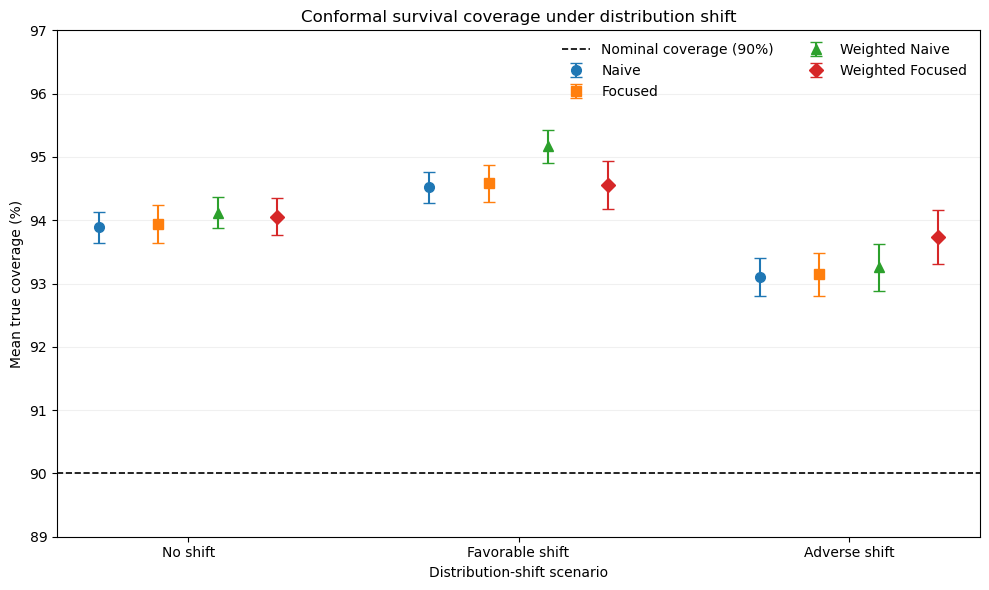

Figure 3 generated for review.
Nothing saved.


In [120]:

# STEP 79 - CELL 3
# MAIN FIGURE 3: COVERAGE UNDER DISTRIBUTION SHIFT
# VISUALIZATION ONLY - NO SAVING

figure79_scenarios = [
    "No shift",
    "Favorable shift",
    "Adverse shift"
]

figure79_methods = [
    "Naive",
    "Focused estimated",
    "W-Naive estimated",
    "W-Focused estimated"
]

figure79_labels = {
    "Naive": "Naive",
    "Focused estimated": "Focused",
    "W-Naive estimated": "Weighted Naive",
    "W-Focused estimated": "Weighted Focused"
}

figure79_markers = ["o", "s", "^", "D"]
figure79_offsets = [-0.27, -0.09, 0.09, 0.27]

fig_shift_79, ax_shift_79 = plt.subplots(
    figsize=(10, 6)
)

x_positions = np.arange(len(figure79_scenarios))

for method, marker, offset in zip(
    figure79_methods,
    figure79_markers,
    figure79_offsets
):

    data = (
        table78a.loc[
            table78a["Method"] == method
        ]
        .set_index("Scenario")
        .reindex(figure79_scenarios)
    )

    assert data["Coverage (%)"].notna().all()

    coverage = data["Coverage (%)"].to_numpy()

    lower = data["95% MC lower"].to_numpy()
    upper = data["95% MC upper"].to_numpy()

    y_errors = np.vstack([
        coverage - lower,
        upper - coverage
    ])

    ax_shift_79.errorbar(
        x_positions + offset,
        coverage,
        yerr=y_errors,
        fmt=marker,
        markersize=7,
        linewidth=1.5,
        capsize=4,
        linestyle="none",
        label=figure79_labels[method]
    )

ax_shift_79.axhline(
    90,
    color="black",
    linestyle="--",
    linewidth=1.2,
    label="Nominal coverage (90%)"
)

ax_shift_79.set_xticks(x_positions)
ax_shift_79.set_xticklabels(figure79_scenarios)

ax_shift_79.set_ylabel(
    "Mean true coverage (%)"
)

ax_shift_79.set_xlabel(
    "Distribution-shift scenario"
)

ax_shift_79.set_title(
    "Conformal survival coverage under distribution shift"
)

ax_shift_79.set_ylim(89, 97)
ax_shift_79.grid(axis="y", alpha=0.18)
ax_shift_79.legend(frameon=False, ncol=2)

fig_shift_79.tight_layout()

plt.show()

print("Figure 3 generated for review.")
print("Nothing saved.")


In [122]:

# STEP 79 - CELL 4
# COMPLETE MISSING MANUSCRIPT OUTPUTS
# ARCHIVING ONLY - NO FITTING OR VISUALIZATION

from pathlib import Path

SAVE_FINAL_MISSING = False

if SAVE_FINAL_MISSING:

    # -------------------------------------
    # 1. Output directories
    # -------------------------------------

    table_dir_79 = Path("../results/draft_tables")
    figure_dir_79 = Path("../figures/draft_real")

    table_dir_79.mkdir(parents=True, exist_ok=True)
    figure_dir_79.mkdir(parents=True, exist_ok=True)

    # -------------------------------------
    # 2. Save updated Table 1
    # -------------------------------------

    table79_path = (
        table_dir_79 /
        "DRAFT_10_baseline_with_reverseKM.csv"
    )

    assert len(baseline_table_75_updated) == 4
    assert baseline_table_75_updated[
        "Reverse KM median follow-up"
    ].notna().all()

    if not table79_path.exists():
        baseline_table_75_updated.to_csv(
            table79_path,
            index=False,
            encoding="utf-8-sig"
        )
        print("Saved Table 1:", table79_path)
    else:
        print("Table 1 already exists:", table79_path)

    # -------------------------------------
    # 3. Save approved Figure 3
    # -------------------------------------

    assert fig_shift_79 is not None
    assert len(fig_shift_79.axes) > 0

    fig79_base = (
        figure_dir_79 /
        "DRAFT_Figure_distribution_shift_coverage"
    )

    for extension in ["png", "pdf"]:

        file_path = fig79_base.with_suffix(
            "." + extension
        )

        if not file_path.exists():

            options = {
                "bbox_inches": "tight",
                "facecolor": "white"
            }

            if extension == "png":
                options["dpi"] = 350

            fig_shift_79.savefig(
                file_path,
                **options
            )

            print("Saved Figure:", file_path)

        else:
            print("Figure already exists:", file_path)

    # -------------------------------------
    # 4. Verify manuscript outputs
    # -------------------------------------

    expected_outputs = [
        "../results/draft_tables/DRAFT_10_baseline_with_reverseKM.csv",
        "../results/draft_tables/DRAFT_08_internal_external_validation.csv",
        "../results/draft_tables/DRAFT_11_main_simulation_results.csv",
        "../results/draft_tables/DRAFT_12_independent_benchmark_results.csv",
        "../figures/draft_real/DRAFT_Figure_study_population_flow.png",
        "../figures/draft_real/DRAFT_Figure_internal_external_coverage.png",
        "../figures/draft_real/DRAFT_Figure_external_subgroup_coverage.png",
        "../figures/draft_real/DRAFT_Figure_distribution_shift_coverage.png",
        "../figures/draft_benchmark/DRAFT_Figure_threshold_coverage.png",
        "../figures/draft_benchmark/DRAFT_Figure_coverage_vs_LPB.png"
    ]

    missing_outputs = [
        path for path in expected_outputs
        if not Path(path).is_file()
    ]

    print("\nMANUSCRIPT FILE CHECK")
    print("Expected outputs:", len(expected_outputs))
    print(
        "Available outputs:",
        len(expected_outputs) - len(missing_outputs)
    )

    if missing_outputs:
        print("\nMissing files:")
        for path in missing_outputs:
            print("-", path)
    else:
        print("PASS: All required outputs found.")

    print("\nArchiving completed.")

else:
    print("Archiving disabled.")


Archiving disabled.
